In [1]:
import onnxruntime as ort
import numpy as np
import json
import uproot
import pandas as pd
import matplotlib.pyplot as plt
import mplhep
from sklearn import metrics
from scipy.integrate import simpson
from scipy.integrate import trapezoid
from scipy.stats import distributions
from sklearn.ensemble import GradientBoostingClassifier
from xgboost import XGBClassifier
from sklearn.model_selection import KFold
from scipy.stats import chisquare
import xgboost 
import pickle
import json
from scipy.stats import chisquare
import warnings
from collections import defaultdict #for feature imp avg
import seaborn as sns
from pprint import pprint
from matplotlib.ticker import FuncFormatter  #for y-axis scaling for histograms
import matplotlib.ticker as mtick

In [2]:
uproot.__version__, pd.__version__, np.__version__, xgboost.__version__

('4.3.7', '1.5.3', '1.23.5', '2.0.2')

In [3]:
# Initialize the counter
if 'execution_count' not in globals():
    execution_count = 0


In [4]:
# KS Test
def ks_weighted(data1, data2, wei1, wei2, alternative='two-sided'):
    data1 = np.array(data1)
    data2 = np.array(data2)
    wei1 = np.array(wei1)
    wei2 = np.array(wei2)
    
    ix1 = np.argsort(data1)
    ix2 = np.argsort(data2)
    data1 = data1[ix1]
    data2 = data2[ix2]
    wei1 = wei1[ix1]
    wei2 = wei2[ix2]
    data = np.concatenate([data1, data2])
    cwei1 = np.hstack([0, np.cumsum(wei1)/sum(wei1)])
    cwei2 = np.hstack([0, np.cumsum(wei2)/sum(wei2)])
    cdf1we = cwei1[np.searchsorted(data1, data, side='right')]
    cdf2we = cwei2[np.searchsorted(data2, data, side='right')]
    d = np.max(np.abs(cdf1we - cdf2we))
    # calculate p-value
    n1 = data1.shape[0]
    n2 = data2.shape[0]
    m, n = sorted([float(n1), float(n2)], reverse=True)
    en = m * n / (m + n)
    if alternative == 'two-sided':
        prob = distributions.kstwo.sf(d, np.round(en))
    else:
        z = np.sqrt(en) * d
        # Use Hodges' suggested approximation Eqn 5.3
        # Requires m to be the larger of (n1, n2)
        expt = -2 * z**2 - 2 * z * (m + 2*n)/np.sqrt(m*n*(m+n))/3.0
        prob = np.exp(expt)
    return d, prob

In [5]:
# Set of variables for WP85

feature_cols = ['jet_pt[:,0]',
                'jet_pt[:,1]', 
                'met_met',
                'ph_eta[:,0]', 
                'ph_eta[:,1]',
                'ph_pt[:,0]', 
                'ph_pt[:,1]',
                'ph_mlph_closest[:,0]', 
                'ph_mlph_closest[:,1]',
                'diph_M', 
                'event_nbjets85', 
                'dr_lep_ph0', 
                'dr_lep_ph1',
                'ph_conversion_type[:,1]', 
                'ph_conversion_type[:,0]',
                'ph_mphb85_closest[:,0]',
                'ph_mphb85_closest[:,1]',
                'm_AllObjects',
                'jet_tagWeightBin_DL1r_Continuous_Max',
                'dr_ph'
                  ]
                  


# Update the counter
global execution_count
execution_count += 1
print(f"This cell has been run {execution_count} times.")


This cell has been run 1 times.


In [6]:
len(feature_cols)

20

In [7]:
cols = feature_cols+['eventNumber','weight','mcChannelNumber']
aliases = {'weight':'event_norm * weight_mc * weight_pileup * weight_leptonSF * weight_photonSF * weight_jvt * weight_bTagSF_DL1r_Continuous * event_lumi'}

In [8]:
df_sig_85 = uproot.concatenate('/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*ttgammagamma*.root:nominal',expressions=cols,cut='(ph_true_category[:,0]<10)&(ph_true_category[:,1]<10)&(event_nbjets85>=1)',library="pd",aliases=aliases)
df_bkg_85 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*ttgamma_*.root:nominal','/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*Vyy*.root:nominal'],expressions=cols,cut='(event_nbjets85>=1)',library="pd",aliases=aliases)

df_sig_70 = uproot.concatenate('/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*ttgammagamma*.root:nominal',expressions=cols,cut='(ph_true_category[:,0]<10)&(ph_true_category[:,1]<10)&(event_nbjets70>=1)',library="pd",aliases=aliases)
df_bkg_70 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*ttgamma_*.root:nominal','/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*Vyy*.root:nominal'],expressions=cols,cut='(event_nbjets70>=1)',library="pd",aliases=aliases)


In [9]:
len(df_sig_85), len(df_bkg_85), len(df_sig_70), len(df_bkg_70)

# WP 70: 323900, 3959 


(358887, 5855, 323900, 3959)

In [44]:
323900+3959

327859

In [45]:
358887+5855

364742

In [10]:
df_bkg_prompt_ttyprodNLO_85 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*ttgamma_NLO_prod*.root:nominal'],expressions=cols,cut='(ph_true_category[:,0]<10)&(ph_true_category[:,1]<10)&(event_nbjets85>=1)',library="pd",aliases=aliases)
df_bkg_prompt_ttyprodNLO_70 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*ttgamma_NLO_prod*.root:nominal'],expressions=cols,cut='(ph_true_category[:,0]<10)&(ph_true_category[:,1]<10)&(event_nbjets70>=1)',library="pd",aliases=aliases)



df_bkg_fakes_ttyprodNLO_85 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*ttgamma_NLO_prod*.root:nominal'],expressions=cols,cut='((ph_true_category[:,0]>=10)|(ph_true_category[:,1]>=10))&(event_nbjets85>=1)',library="pd",aliases=aliases)
df_bkg_fakes_ttyprodNLO_70 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*ttgamma_NLO_prod*.root:nominal'],expressions=cols,cut='((ph_true_category[:,0]>=10)|(ph_true_category[:,1]>=10))&(event_nbjets70>=1)',library="pd",aliases=aliases)

######################



df_bkg_prompt_ttydecLO_85 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*ttgamma_LO_dec*.root:nominal'],expressions=cols,cut='(ph_true_category[:,0]<10)&(ph_true_category[:,1]<10)&(event_nbjets85>=1)',library="pd",aliases=aliases)
df_bkg_prompt_ttydecLO_70 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*ttgamma_LO_dec*.root:nominal'],expressions=cols,cut='(ph_true_category[:,0]<10)&(ph_true_category[:,1]<10)&(event_nbjets70>=1)',library="pd",aliases=aliases)



df_bkg_fakes_ttydecLO_85 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*ttgamma_LO_dec*.root:nominal'],expressions=cols,cut='((ph_true_category[:,0]>=10)|(ph_true_category[:,1]>=10))&(event_nbjets85>=1)',library="pd",aliases=aliases)
df_bkg_fakes_ttydecLO_70 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*ttgamma_LO_dec*.root:nominal'],expressions=cols,cut='((ph_true_category[:,0]>=10)|(ph_true_category[:,1]>=10))&(event_nbjets70>=1)',library="pd",aliases=aliases)


######################



df_bkg_prompt_Wyy_85 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*Vyy*.root:nominal'],expressions=cols,cut='(ph_true_category[:,0]<10)&(ph_true_category[:,1]<10)&(event_nbjets85>=1)&((mcChannelNumber==700199)|(mcChannelNumber==700200)|(mcChannelNumber==700201))',library="pd",aliases=aliases)
df_bkg_prompt_Wyy_70 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*Vyy*.root:nominal'],expressions=cols,cut='(ph_true_category[:,0]<10)&(ph_true_category[:,1]<10)&(event_nbjets70>=1)&((mcChannelNumber==700199)|(mcChannelNumber==700200)|(mcChannelNumber==700201))',library="pd",aliases=aliases)


df_bkg_fakes_Wyy_85 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*Vyy*.root:nominal'],expressions=cols,cut='((ph_true_category[:,0]>=10)|(ph_true_category[:,1]>=10))&(event_nbjets85>=1)&((mcChannelNumber==700199)|(mcChannelNumber==700200)|(mcChannelNumber==700201))',library="pd",aliases=aliases)
df_bkg_fakes_Wyy_70 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*Vyy*.root:nominal'],expressions=cols,cut='((ph_true_category[:,0]>=10)|(ph_true_category[:,1]>=10))&(event_nbjets70>=1)&((mcChannelNumber==700199)|(mcChannelNumber==700200)|(mcChannelNumber==700201))',library="pd",aliases=aliases)




######################

df_bkg_prompt_Zyy_85 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*Vyy*.root:nominal'],expressions=cols,cut='(ph_true_category[:,0]<10)&(ph_true_category[:,1]<10)&(event_nbjets85>=1)&((mcChannelNumber==700195)|(mcChannelNumber==700196)|(mcChannelNumber==700197))',library="pd",aliases=aliases)
df_bkg_prompt_Zyy_70 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*Vyy*.root:nominal'],expressions=cols,cut='(ph_true_category[:,0]<10)&(ph_true_category[:,1]<10)&(event_nbjets70>=1)&((mcChannelNumber==700195)|(mcChannelNumber==700196)|(mcChannelNumber==700197))',library="pd",aliases=aliases)


df_bkg_fakes_Zyy_85 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*Vyy*.root:nominal'],expressions=cols,cut='((ph_true_category[:,0]>=10)|(ph_true_category[:,1]>=10))&(event_nbjets85>=1)&((mcChannelNumber==700195)|(mcChannelNumber==700196)|(mcChannelNumber==700197))',library="pd",aliases=aliases)
df_bkg_fakes_Zyy_70 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*Vyy*.root:nominal'],expressions=cols,cut='((ph_true_category[:,0]>=10)|(ph_true_category[:,1]>=10))&(event_nbjets70>=1)&((mcChannelNumber==700195)|(mcChannelNumber==700196)|(mcChannelNumber==700197))',library="pd",aliases=aliases)


In [11]:
print('For tty prod NLO (prompts at 85 and 70): ', len(df_bkg_prompt_ttyprodNLO_85), len(df_bkg_prompt_ttyprodNLO_70))
print('For tty prod NLO (fakes at 85 and 70): ', len(df_bkg_fakes_ttyprodNLO_85), len(df_bkg_fakes_ttyprodNLO_70))

print('For tty dec LO (prompts at 85 and 70): ', len(df_bkg_prompt_ttydecLO_85), len(df_bkg_prompt_ttydecLO_70))
print('For tty dec LO (fakes at 85 and 70): ', len(df_bkg_fakes_ttydecLO_85), len(df_bkg_fakes_ttydecLO_70))


print('For Wyy (prompts at 85 and 70): ',len(df_bkg_prompt_Wyy_85), len(df_bkg_prompt_Wyy_70))
print('For Wyy (fakes at 85 and 70): ',len(df_bkg_fakes_Wyy_85), len(df_bkg_fakes_Wyy_70))
print('For Zyy (prompts at 85 and 70): ',len(df_bkg_prompt_Zyy_85), len(df_bkg_prompt_Zyy_70))
print('For Zyy (fakes at 85 and 70): ',len(df_bkg_fakes_Zyy_85), len(df_bkg_fakes_Zyy_70))

For tty prod NLO (prompts at 85 and 70):  222 203
For tty prod NLO (fakes at 85 and 70):  1928 1748
For tty dec LO (prompts at 85 and 70):  141 126
For tty dec LO (fakes at 85 and 70):  1036 942
For Wyy (prompts at 85 and 70):  368 130
For Wyy (fakes at 85 and 70):  0 0
For Zyy (prompts at 85 and 70):  2073 774
For Zyy (fakes at 85 and 70):  87 36


In [12]:
data = [
    ["tty prod NLO", "Prompts", len(df_bkg_prompt_ttyprodNLO_85), len(df_bkg_prompt_ttyprodNLO_70),len(df_bkg_prompt_ttyprodNLO_70)/len(df_bkg_prompt_ttyprodNLO_85)],
    ["tty prod NLO", "Fakes", len(df_bkg_fakes_ttyprodNLO_85), len(df_bkg_fakes_ttyprodNLO_70),len(df_bkg_fakes_ttyprodNLO_70)/len(df_bkg_fakes_ttyprodNLO_85)],
    ["tty dec LO", "Prompts", len(df_bkg_prompt_ttydecLO_85), len(df_bkg_prompt_ttydecLO_70),len(df_bkg_prompt_ttydecLO_70)/len(df_bkg_prompt_ttydecLO_85)],
    ["tty dec LO", "Fakes", len(df_bkg_fakes_ttydecLO_85), len(df_bkg_fakes_ttydecLO_70),len(df_bkg_fakes_ttydecLO_70)/len(df_bkg_fakes_ttydecLO_85)],
    ["Wyy", "Prompts", len(df_bkg_prompt_Wyy_85), len(df_bkg_prompt_Wyy_70),len(df_bkg_prompt_Wyy_70)/len(df_bkg_prompt_Wyy_85)],
    ["Wyy", "Fakes", len(df_bkg_fakes_Wyy_85), len(df_bkg_fakes_Wyy_70),'NA'],
    ["Zyy", "Prompts", len(df_bkg_prompt_Zyy_85), len(df_bkg_prompt_Zyy_70),len(df_bkg_prompt_Zyy_70)/len(df_bkg_prompt_Zyy_85)],
    ["Zyy", "Fakes", len(df_bkg_fakes_Zyy_85), len(df_bkg_fakes_Zyy_70),len(df_bkg_fakes_Zyy_70)/len(df_bkg_fakes_Zyy_85)],
]

# Print the data in a tabular format
print(f"{'Process':<15} {'Type':<10} {'85 Cut':<10} {'70 Cut':<10} {'Scaling 70/85':<5}")
print("-" * 65)
for row in data:
    scaling = f"{row[4]:.3f}" if row[4] != 'NA' else row[4]
    print(f"{row[0]:<15} {row[1]:<10} {row[2]:<10} {row[3]:<10} {scaling:<5}")

print("-" * 65)

print(f"{'Total:':<25} {len(df_bkg_85):<10} {len(df_bkg_70):<10}")

Process         Type       85 Cut     70 Cut     Scaling 70/85
-----------------------------------------------------------------
tty prod NLO    Prompts    222        203        0.914
tty prod NLO    Fakes      1928       1748       0.907
tty dec LO      Prompts    141        126        0.894
tty dec LO      Fakes      1036       942        0.909
Wyy             Prompts    368        130        0.353
Wyy             Fakes      0          0          NA   
Zyy             Prompts    2073       774        0.373
Zyy             Fakes      87         36         0.414
-----------------------------------------------------------------
Total:                    5855       3959      


In [13]:
df_bkg_prompt_ttyprodNLO_85['weight']
print(df_bkg_prompt_ttyprodNLO_85['weight'].describe())


count    222.000000
mean       0.007957
std        0.016986
min       -0.026761
25%       -0.010580
50%        0.015828
75%        0.021102
max        0.027507
Name: weight, dtype: float64


In [14]:
# Reweight per process:
df_bkg_prompt_ttyprodNLO_85['weight'] *= len(df_bkg_prompt_ttyprodNLO_70)/len(df_bkg_prompt_ttyprodNLO_85)
df_bkg_fakes_ttyprodNLO_85['weight'] *= len(df_bkg_fakes_ttyprodNLO_70)/len(df_bkg_fakes_ttyprodNLO_85)
df_bkg_prompt_ttydecLO_85['weight'] *= len(df_bkg_prompt_ttydecLO_70)/len(df_bkg_prompt_ttydecLO_85)
df_bkg_fakes_ttydecLO_85['weight'] *= len(df_bkg_fakes_ttydecLO_70)/len(df_bkg_fakes_ttydecLO_85)
df_bkg_prompt_Wyy_85['weight'] *= len(df_bkg_prompt_Wyy_70)/len(df_bkg_prompt_Wyy_85)
#df_bkg_fakes_Wyy_85['weight'] *= len(df_bkg_fakes_Wyy_70)/len(df_bkg_fakes_Wyy_85)
df_bkg_prompt_Zyy_85['weight'] *= len(df_bkg_prompt_Zyy_70)/len(df_bkg_prompt_Zyy_85)
df_bkg_fakes_Zyy_85['weight'] *= len(df_bkg_fakes_Zyy_70)/len(df_bkg_fakes_Zyy_85)



In [15]:
df_bkg_prompt_ttyprodNLO_85['weight']
print(df_bkg_prompt_ttyprodNLO_85['weight'].describe())


count    222.000000
mean       0.007276
std        0.015533
min       -0.024470
25%       -0.009675
50%        0.014474
75%        0.019296
max        0.025153
Name: weight, dtype: float64


In [47]:
df_bkg_prompt_Wyy_85.describe()

,"jet_pt[:,0]","jet_pt[:,1]",met_met,"ph_eta[:,0]","ph_eta[:,1]","ph_pt[:,0]","ph_pt[:,1]","ph_mlph_closest[:,0]","ph_mlph_closest[:,1]",diph_M,...,"ph_conversion_type[:,1]","ph_conversion_type[:,0]","ph_mphb85_closest[:,0]","ph_mphb85_closest[:,1]",m_AllObjects,jet_tagWeightBin_DL1r_Continuous_Max,dr_ph,eventNumber,weight,mcChannelNumber
count,3.680000e+02,368.000000,368.000000,368.000000,368.000000,3.680000e+02,368.000000,3.680000e+02,368.000000,3.680000e+02,...,368.000000,368.000000,3.680000e+02,3.680000e+02,3.680000e+02,368.000000,368.000000,3.680000e+02,368.000000,368.000000
mean,2.728493e+05,131119.343750,96713.664062,-0.011401,0.098620,2.335375e+05,79277.757812,2.834896e+05,158255.984375,3.084667e+05,...,0.823370,0.671196,3.739082e+05,1.949628e+05,1.520173e+06,3.152174,2.530956,9.951293e+05,0.014280,700199.619565
std,1.789741e+05,99630.429688,98302.093750,1.161990,1.299908,1.593794e+05,69992.117188,2.394415e+05,123021.250000,2.296411e+05,...,1.328291,1.198563,3.929168e+05,1.565323e+05,7.387466e+05,1.216909,1.018266,5.571325e+05,0.024044,0.596856
min,4.107534e+04,27663.880859,1690.095581,-2.367918,-2.361243,2.660095e+04,20062.494141,1.797554e+04,13238.872070,1.815242e+04,...,0.000000,0.000000,2.626046e+04,1.419205e+04,3.883550e+05,2.000000,0.399635,3.168000e+03,-0.078124,700199.000000
25%,1.349292e+05,67130.963867,37042.223633,-0.857663,-0.885293,1.134168e+05,33785.689453,1.182387e+05,68544.906250,1.381329e+05,...,0.000000,0.000000,1.476188e+05,8.812913e+04,9.900564e+05,2.000000,1.846591,5.110308e+05,0.002348,700199.000000
50%,2.270867e+05,102334.019531,65184.806641,-0.043018,0.117994,2.041797e+05,55050.406250,2.176991e+05,133967.085938,2.575233e+05,...,0.000000,0.000000,2.475471e+05,1.519029e+05,1.349245e+06,3.000000,2.687484,1.017666e+06,0.005400,700200.000000
75%,3.677731e+05,154774.871094,116226.498047,0.777527,1.078231,3.198387e+05,98954.689453,3.587530e+05,211762.402344,4.322468e+05,...,2.000000,1.000000,4.839388e+05,2.510596e+05,1.855878e+06,4.000000,3.168449,1.469348e+06,0.015319,700200.000000
max,1.214469e+06,597684.062500,881391.125000,2.362320,2.368783,1.252214e+06,506616.031250,1.592733e+06,727442.937500,1.234943e+06,...,5.000000,5.000000,3.781701e+06,1.154516e+06,5.000532e+06,5.000000,5.012627,1.892710e+06,0.271354,700201.000000


In [16]:
# Combine the two background datasets to form the WP85 reweighted background to WP70
df_bkg_prompt_85_reweighted = pd.concat([df_bkg_prompt_ttyprodNLO_85, df_bkg_prompt_ttydecLO_85, df_bkg_prompt_Wyy_85, df_bkg_prompt_Zyy_85], ignore_index=False)
len(df_bkg_prompt_85_reweighted)

2804

In [127]:
print(df_bkg_prompt_85_reweighted['weight'].describe())

count    2804.000000
mean        0.003507
std         0.011079
min        -0.078124
25%         0.000097
50%         0.000469
75%         0.002761
max         0.271354
Name: weight, dtype: float64


In [17]:
# Combine the two background datasets to form the WP85 reweighted background to WP70
df_bkg_fakes_85_reweighted = pd.concat([df_bkg_fakes_ttyprodNLO_85, df_bkg_fakes_ttydecLO_85, df_bkg_fakes_Wyy_85, df_bkg_fakes_Zyy_85], ignore_index=False)
len(df_bkg_fakes_85_reweighted)

3051

In [128]:
print(df_bkg_fakes_85_reweighted['weight'].describe())

count    3051.000000
mean        0.007310
std         0.013094
min        -0.029860
25%         0.003973
50%         0.009968
75%         0.017414
max         0.046421
Name: weight, dtype: float64


In [18]:
#df_bkg_85_reweighted = pd.concat([df_bkg_prompt_85_reweighted, df_bkg_fakes_85_reweighted], ignore_index=False)

In [19]:
#len(df_bkg_85_reweighted)

In [20]:
mplhep.style.use('ATLAS')

# Training and Evaluation with WP85 (bkg reweighted to match WP70 statistics) -> No, doesn't work.. 
# No scale pos parameter can be added

In [18]:
df_sig_85_reweighted = df_sig_85

In [204]:
df_sig_85['eventNumber'].describe()


count    3.588870e+05
mean     1.464455e+07
std      8.882928e+06
min      1.000000e+01
25%      6.599648e+06
50%      1.457924e+07
75%      2.246156e+07
max      2.999998e+07
Name: eventNumber, dtype: float64

In [240]:
df_sig_85['weight'].describe(), df_bkg_prompt_ttyprodNLO_85['weight'].describe(), df_bkg_prompt_ttydecLO_85['weight'].describe(), df_bkg_prompt_Wyy_85['weight'].describe(), df_bkg_prompt_Zyy_85['weight'].describe()

(count    358887.000000
 mean          0.000127
 std           0.000038
 min          -0.000170
 25%           0.000109
 50%           0.000133
 75%           0.000151
 max           0.000921
 Name: weight, dtype: float64,
 count    222.000000
 mean       0.007276
 std        0.015533
 min       -0.024470
 25%       -0.009675
 50%        0.014474
 75%        0.019296
 max        0.025153
 Name: weight, dtype: float64,
 count    141.000000
 mean       0.008035
 std        0.002463
 min        0.001153
 25%        0.006761
 50%        0.008403
 75%        0.009744
 max        0.014543
 Name: weight, dtype: float64,
 count    368.000000
 mean       0.014280
 std        0.024044
 min       -0.078124
 25%        0.002348
 50%        0.005400
 75%        0.015319
 max        0.271354
 Name: weight, dtype: float64,
 count    2073.000000
 mean        0.000883
 std         0.002664
 min        -0.008877
 25%         0.000078
 50%         0.000252
 75%         0.000800
 max         0.092987
 Nam

In [247]:
# Calculate the mean of negative values in the 'weight' column
mean_negative_weights = df_bkg_prompt_ttyprodNLO_85[df_bkg_prompt_ttyprodNLO_85['weight'] < 0]['weight'].mean()
print(f"Mean neg weight: {mean_negative_weights}")
# Filter and print values less than the mean of negative values
print(df_bkg_prompt_ttyprodNLO_85[df_bkg_prompt_ttyprodNLO_85['weight'] < mean_negative_weights]['weight'])

Mean neg weight: -0.01662091538310051
entry
9      -0.022078
83     -0.021166
260    -0.018622
338    -0.017801
367    -0.017680
388    -0.020688
566    -0.018782
610    -0.017201
647    -0.019527
648    -0.020789
655    -0.021562
657    -0.021676
736    -0.017103
776    -0.019143
822    -0.020182
871    -0.020217
942    -0.018658
1013   -0.018698
1135   -0.016926
1151   -0.020215
1172   -0.018751
1195   -0.016935
1226   -0.018617
1242   -0.019286
1278   -0.016622
1366   -0.020566
1384   -0.021682
1487   -0.021076
1493   -0.019236
1501   -0.024470
1506   -0.022665
1839   -0.019744
2141   -0.018903
Name: weight, dtype: float32


In [248]:
# Calculate the mean of negative values in the 'weight' column
mean_negative_weights = df_bkg_fakes_ttyprodNLO_85[df_bkg_fakes_ttyprodNLO_85['weight'] < 0]['weight'].mean()
print(f"Mean neg weight: {mean_negative_weights}")
# Filter and print values less than the mean of negative values
print(df_bkg_fakes_ttyprodNLO_85[df_bkg_fakes_ttyprodNLO_85['weight'] < mean_negative_weights]['weight'])

Mean neg weight: -0.01699763350188732
entry
0      -0.023602
1      -0.018001
17     -0.017715
25     -0.019851
29     -0.018626
          ...   
2130   -0.018008
2133   -0.022136
2137   -0.019714
2139   -0.017308
2144   -0.018256
Name: weight, Length: 320, dtype: float32


In [241]:
df_sig_85['weight'].describe(), df_bkg_fakes_ttyprodNLO_85['weight'].describe(), df_bkg_fakes_ttydecLO_85['weight'].describe(), df_bkg_fakes_Wyy_85['weight'].describe(), df_bkg_fakes_Zyy_85['weight'].describe()

(count    358887.000000
 mean          0.000127
 std           0.000038
 min          -0.000170
 25%           0.000109
 50%           0.000133
 75%           0.000151
 max           0.000921
 Name: weight, dtype: float64,
 count    1928.000000
 mean        0.006942
 std         0.016291
 min        -0.029860
 25%        -0.011994
 50%         0.015438
 75%         0.019458
 max         0.046421
 Name: weight, dtype: float64,
 count    1036.000000
 mean        0.008477
 std         0.002489
 min         0.000000
 25%         0.007344
 50%         0.008990
 75%         0.010149
 max         0.015384
 Name: weight, dtype: float64,
 count    0.0
 mean     NaN
 std      NaN
 min      NaN
 25%      NaN
 50%      NaN
 75%      NaN
 max      NaN
 Name: weight, dtype: float64,
 count    87.000000
 mean      0.001564
 std       0.002524
 min      -0.002816
 25%       0.000114
 50%       0.000414
 75%       0.001571
 max       0.010160
 Name: weight, dtype: float64)

In [203]:
duplicates = df_sig_85[df_sig_85['eventNumber'].duplicated(keep=False)]
print(duplicates)

Empty DataFrame
Columns: [jet_pt[:,0], jet_pt[:,1], met_met, ph_eta[:,0], ph_eta[:,1], ph_pt[:,0], ph_pt[:,1], ph_mlph_closest[:,0], ph_mlph_closest[:,1], diph_M, event_nbjets85, dr_lep_ph0, dr_lep_ph1, ph_conversion_type[:,1], ph_conversion_type[:,0], ph_mphb85_closest[:,0], ph_mphb85_closest[:,1], m_AllObjects, jet_tagWeightBin_DL1r_Continuous_Max, dr_ph, eventNumber, weight, mcChannelNumber]
Index: []

[0 rows x 23 columns]


In [221]:
#df_bkg_prompt_85_reweighted = pd.concat([df_bkg_prompt_ttyprodNLO_85, df_bkg_prompt_ttydecLO_85, df_bkg_prompt_Wyy_85, df_bkg_prompt_Zyy_85], ignore_index=False)
duplicates1 = df_bkg_prompt_Wyy_85[df_bkg_prompt_Wyy_85['eventNumber'].duplicated(keep=False)]
print(duplicates1)

duplicates2 = df_bkg_prompt_Zyy_85[df_bkg_prompt_Zyy_85['eventNumber'].duplicated(keep=False)]
print(duplicates2)


duplicates3 = df_bkg_prompt_ttydecLO_85[df_bkg_prompt_ttydecLO_85['eventNumber'].duplicated(keep=False)]
print(duplicates3)


duplicates4 = df_bkg_prompt_ttyprodNLO_85[df_bkg_prompt_ttyprodNLO_85['eventNumber'].duplicated(keep=False)]
print(duplicates4)

Empty DataFrame
Columns: [jet_pt[:,0], jet_pt[:,1], met_met, ph_eta[:,0], ph_eta[:,1], ph_pt[:,0], ph_pt[:,1], ph_mlph_closest[:,0], ph_mlph_closest[:,1], diph_M, event_nbjets85, dr_lep_ph0, dr_lep_ph1, ph_conversion_type[:,1], ph_conversion_type[:,0], ph_mphb85_closest[:,0], ph_mphb85_closest[:,1], m_AllObjects, jet_tagWeightBin_DL1r_Continuous_Max, dr_ph, eventNumber, weight, mcChannelNumber]
Index: []

[0 rows x 23 columns]
Empty DataFrame
Columns: [jet_pt[:,0], jet_pt[:,1], met_met, ph_eta[:,0], ph_eta[:,1], ph_pt[:,0], ph_pt[:,1], ph_mlph_closest[:,0], ph_mlph_closest[:,1], diph_M, event_nbjets85, dr_lep_ph0, dr_lep_ph1, ph_conversion_type[:,1], ph_conversion_type[:,0], ph_mphb85_closest[:,0], ph_mphb85_closest[:,1], m_AllObjects, jet_tagWeightBin_DL1r_Continuous_Max, dr_ph, eventNumber, weight, mcChannelNumber]
Index: []

[0 rows x 23 columns]
Empty DataFrame
Columns: [jet_pt[:,0], jet_pt[:,1], met_met, ph_eta[:,0], ph_eta[:,1], ph_pt[:,0], ph_pt[:,1], ph_mlph_closest[:,0], ph_ml

In [211]:
duplicates = df_bkg_prompt_85_reweighted[df_bkg_prompt_85_reweighted['eventNumber'].duplicated(keep=False)]
print(duplicates)

         jet_pt[:,0]    jet_pt[:,1]        met_met  ph_eta[:,0]  ph_eta[:,1]  \
entry                                                                          
2464    88541.250000   57590.503906   33647.933594     1.058774     2.154799   
1956   212065.453125  190111.046875  133641.109375     0.363175    -0.881633   

         ph_pt[:,0]    ph_pt[:,1]  ph_mlph_closest[:,0]  ph_mlph_closest[:,1]  \
entry                                                                           
2464    62984.78125  26896.988281          187981.65625         188453.140625   
1956   474102.18750  55789.785156          554405.00000          47010.253906   

              diph_M  ...  ph_conversion_type[:,1]  ph_conversion_type[:,0]  \
entry                 ...                                                     
2464    66225.243824  ...                        3                        2   
1956   387178.964567  ...                        0                        0   

       ph_mphb85_closest[:,0]  ph_mph

In [223]:
where = df_bkg_prompt_Wyy_85[df_bkg_prompt_Wyy_85['eventNumber']==1630342]
print(where)

       jet_pt[:,0]   jet_pt[:,1]       met_met  ph_eta[:,0]  ph_eta[:,1]  \
entry                                                                      
2464      88541.25  57590.503906  33647.933594     1.058774     2.154799   

        ph_pt[:,0]    ph_pt[:,1]  ph_mlph_closest[:,0]  ph_mlph_closest[:,1]  \
entry                                                                          
2464   62984.78125  26896.988281          187981.65625         188453.140625   

             diph_M  ...  ph_conversion_type[:,1]  ph_conversion_type[:,0]  \
entry                ...                                                     
2464   66225.243824  ...                        3                        2   

       ph_mphb85_closest[:,0]  ph_mphb85_closest[:,1]   m_AllObjects  \
entry                                                                  
2464             71412.585938             96021.65625  581486.308248   

       jet_tagWeightBin_DL1r_Continuous_Max     dr_ph  eventNumber    weight  

In [224]:
where = df_bkg_prompt_Zyy_85[df_bkg_prompt_Zyy_85['eventNumber']==1630342]
print(where)

         jet_pt[:,0]    jet_pt[:,1]        met_met  ph_eta[:,0]  ph_eta[:,1]  \
entry                                                                          
1956   212065.453125  190111.046875  133641.109375     0.363175    -0.881633   

        ph_pt[:,0]    ph_pt[:,1]  ph_mlph_closest[:,0]  ph_mlph_closest[:,1]  \
entry                                                                          
1956   474102.1875  55789.785156              554405.0          47010.253906   

              diph_M  ...  ph_conversion_type[:,1]  ph_conversion_type[:,0]  \
entry                 ...                                                     
1956   387178.964567  ...                        0                        0   

       ph_mphb85_closest[:,0]  ph_mphb85_closest[:,1]  m_AllObjects  \
entry                                                                 
1956                713561.25           106137.828125  1.422166e+06   

       jet_tagWeightBin_DL1r_Continuous_Max     dr_ph  eventNumber

In [212]:
duplicates = df_bkg_fakes_85_reweighted[df_bkg_fakes_85_reweighted['eventNumber'].duplicated(keep=False)]
print(duplicates)

Empty DataFrame
Columns: [jet_pt[:,0], jet_pt[:,1], met_met, ph_eta[:,0], ph_eta[:,1], ph_pt[:,0], ph_pt[:,1], ph_mlph_closest[:,0], ph_mlph_closest[:,1], diph_M, event_nbjets85, dr_lep_ph0, dr_lep_ph1, ph_conversion_type[:,1], ph_conversion_type[:,0], ph_mphb85_closest[:,0], ph_mphb85_closest[:,1], m_AllObjects, jet_tagWeightBin_DL1r_Continuous_Max, dr_ph, eventNumber, weight, mcChannelNumber]
Index: []

[0 rows x 23 columns]


In [69]:
n_estimators = 33

In [158]:

nfolds = 4

# SINGLE MODEL  : Using XGB Classifier
models = []
scores_train,scores_test = [],[]
testloss = {fold:[] for fold in range(nfolds)}
trainloss = {fold:[] for fold in range(nfolds)}


for fold in range(nfolds):
    
    print(f"\nFold: {fold}")
    
    X_sig_train = df_sig_85[feature_cols][df_sig_85['eventNumber']%nfolds != fold]
    w_sig_train = df_sig_85['weight'][df_sig_85['eventNumber']%nfolds != fold]
    
    X_sig_test = df_sig_85[feature_cols][df_sig_85['eventNumber']%nfolds == fold]
    w_sig_test = df_sig_85['weight'][df_sig_85['eventNumber']%nfolds == fold]
    
    X_bkg_train_prompts = df_bkg_prompt_85_reweighted[feature_cols][df_bkg_prompt_85_reweighted['eventNumber']%nfolds != fold]
    w_bkg_train_prompts = df_bkg_prompt_85_reweighted['weight'][df_bkg_prompt_85_reweighted['eventNumber']%nfolds != fold]

    X_bkg_test_prompts = df_bkg_prompt_85_reweighted[feature_cols][df_bkg_prompt_85_reweighted['eventNumber']%nfolds == fold]
    w_bkg_test_prompts = df_bkg_prompt_85_reweighted['weight'][df_bkg_prompt_85_reweighted['eventNumber']%nfolds == fold]
        
    X_bkg_train_fakes = df_bkg_fakes_85_reweighted[feature_cols][df_bkg_fakes_85_reweighted['eventNumber']%nfolds != fold]
    w_bkg_train_fakes = df_bkg_fakes_85_reweighted['weight'][df_bkg_fakes_85_reweighted['eventNumber']%nfolds != fold]

    X_bkg_test_fakes = df_bkg_fakes_85_reweighted[feature_cols][df_bkg_fakes_85_reweighted['eventNumber']%nfolds == fold]
    w_bkg_test_fakes = df_bkg_fakes_85_reweighted['weight'][df_bkg_fakes_85_reweighted['eventNumber']%nfolds == fold]

 
    y_train =  np.concatenate([np.zeros_like(w_sig_train),np.ones_like(w_bkg_train_prompts),2 * np.ones_like(w_bkg_train_fakes)]) #putting classes 0, 1, 2
    X_train =  np.concatenate([X_sig_train,X_bkg_train_prompts,X_bkg_train_fakes])
    w_train =  np.concatenate([w_sig_train,w_bkg_train_prompts,w_bkg_train_fakes])
    y_test  =  np.concatenate([np.zeros_like(w_sig_test),np.ones_like(w_bkg_test_prompts),2 * np.ones_like(w_bkg_test_fakes)])
    X_test  =  np.concatenate([X_sig_test,X_bkg_test_prompts,X_bkg_test_fakes])
    w_test  =  np.concatenate([w_sig_test,w_bkg_test_prompts,w_bkg_test_fakes])
    
    
    
    print("\n\n\nSignal train & test sizes (events,weights): ", len(X_sig_train), len(w_sig_train), len(X_sig_test), len(w_sig_test))
    print("Prompt train test sizes (events,weights): ", len(X_bkg_train_prompts), len(w_bkg_train_prompts),  len(X_bkg_test_prompts), len(w_bkg_test_prompts))
    print("Fake train test sizes (events,weights): ", len(X_bkg_train_fakes), len(w_bkg_train_fakes), len(X_bkg_test_fakes), len(w_bkg_test_fakes))

    #print(f"Fold {fold}:")
    #print(f"Training: Class 0: {np.sum(y_train == 0)}, Class 1: {np.sum(y_train == 1)}, Class 2: {np.sum(y_train == 2)}")
    #print(f"\nTesting: Class 0: {np.sum(y_test == 0)}, Class 1: {np.sum(y_test == 1)}, Class 2: {np.sum(y_test == 2)}")


    print(f"\n\nFold {fold}:")
    print(f"Signal: {len(X_sig_train)} train, {len(X_sig_test)} test")
    print(f"Prompt Background: {len(X_bkg_train_prompts)} train, {len(X_bkg_test_prompts)} test")
    print(f"Fake Background: {len(X_bkg_train_fakes)} train, {len(X_bkg_test_fakes)} test")

    print(f"Class 0 (Signal): Train = {np.sum(y_train == 0)}, Test = {np.sum(y_test == 0)}")
    print(f"Class 1 (Prompt Background): Train = {np.sum(y_train == 1)}, Test = {np.sum(y_test == 1)}")
    print(f"Class 2 (Fake Background): Train = {np.sum(y_train == 2)}, Test = {np.sum(y_test == 2)}")
    
    # Check weight sums
    print(f"Total training weight: {np.sum(w_train)}, Total testing weight: {np.sum(w_test)}")
    print(f"Class 0 weight sum: Train = {np.sum(w_train[y_train == 0])}, Test = {np.sum(w_test[y_test == 0])}")
    print(f"Class 1 weight sum: Train = {np.sum(w_train[y_train == 1])}, Test = {np.sum(w_test[y_test == 1])}")
    print(f"Class 2 weight sum: Train = {np.sum(w_train[y_train == 2])}, Test = {np.sum(w_test[y_test == 2])}")
    
    
    #Checking for nans and infs
    print(f"\nChecking Fold {fold} for NaNs/Infs...")
    print(f"X_train NaNs: {np.isnan(X_train).sum()}, X_train Infs: {np.isinf(X_train).sum()}")
    print(f"X_test NaNs: {np.isnan(X_test).sum()}, X_test Infs: {np.isinf(X_test).sum()}")
    print(f"y_train NaNs: {np.isnan(y_train).sum()}, y_train Infs: {np.isinf(y_train).sum()}")
    print(f"y_test NaNs: {np.isnan(y_test).sum()}, y_test Infs: {np.isinf(y_test).sum()}")


    
    #Checking 
    print(f"\nChecking Fold {fold} class distributions:")
    print(f"Unique classes in training: {np.unique(y_train)}")
    print(f"Unique classes in testing: {np.unique(y_test)}")
    
    # Initialize XGBoost model for multi-class classification
    #model = XGBClassifier(objective='multi:softmax', num_class=3, use_label_encoder=False)
    #Set 1 of model = XGBClassifier(tree_method="hist", verbosity=2, n_estimators=n_estimators)

    # Define the classifier for a 3-class classification
    model = XGBClassifier(
        tree_method="hist",     # Tree method to use (e.g., "hist" for faster training)
        verbosity=2,            # Set verbosity level for debugging
        n_estimators=n_estimators,  # Number of trees in the model
        objective="multi:softmax",  # Objective for multi-class classification
        num_class=3             # Specify the number of classes (3 in this case)
    )

    # Fit model
    model.fit(X_train, y_train, sample_weight=np.abs(w_train))
    models.append(model)
    scores_train.append(model.score(X_train,y_train,sample_weight=np.abs(w_train)))
    scores_test.append(model.score(X_test,y_test,sample_weight=np.abs(w_test)))  
    print(f'Train scores {fold}:', scores_train)
    print(f'Test scores {fold}: ', scores_test)
    
    n_boosters = len(models[fold].get_booster().get_dump(dump_format='json'))
    print(n_boosters)
 
    #with open(F'CI_test_BDT_binary_Classifier_Classification-BDT_3ClassWP85To70_Model8_Fold{fold}_60boosters.pkl', 'wb') as f:
    #    pickle.dump(model, f)
                       
    """
    for i in range(n_boosters):
            ypred_train = models[-1].predict_proba(X_train, iteration_range=(1, i+1))
            train_loss = metrics.log_loss(y_train, ypred_train, sample_weight=w_train)
            trainloss[fold].append(train_loss)

            ypred_test = models[-1].predict_proba(X_test, iteration_range=(1, i+1))
            test_loss = metrics.log_loss(y_test, ypred_test, sample_weight=w_test)
            testloss[fold].append(test_loss)
        
 
 
    """
    


Fold: 0



Signal train & test sizes (events,weights):  269250 269250 89637 89637
Prompt train test sizes (events,weights):  2100 2100 704 704
Fake train test sizes (events,weights):  2303 2303 748 748


Fold 0:
Signal: 269250 train, 89637 test
Prompt Background: 2100 train, 704 test
Fake Background: 2303 train, 748 test
Class 0 (Signal): Train = 269250, Test = 89637
Class 1 (Prompt Background): Train = 2100, Test = 704
Class 2 (Fake Background): Train = 2303, Test = 748
Total training weight: 58.138614654541016, Total testing weight: 19.478897094726562
Class 0 weight sum: Train = 34.109214782714844, Test = 11.372666358947754
Class 1 weight sum: Train = 7.0282182693481445, Test = 2.8055293560028076
Class 2 weight sum: Train = 17.001178741455078, Test = 5.3007025718688965

Checking Fold 0 for NaNs/Infs...
X_train NaNs: 0, X_train Infs: 0
X_test NaNs: 0, X_test Infs: 0
y_train NaNs: 0, y_train Infs: 0
y_test NaNs: 0, y_test Infs: 0

Checking Fold 0 class distributions:
Unique classes in

In [210]:
nfolds = 4
#for fold in range(nfolds):
for fold in range(4):

    print(f"\n{'='*30} Fold {fold} {'='*30}")

    # Signal Data
    X_sig_train = df_sig_85[feature_cols][df_sig_85['eventNumber'] % nfolds != fold]
    w_sig_train = df_sig_85['weight'][df_sig_85['eventNumber'] % nfolds != fold]
    X_sig_test = df_sig_85[feature_cols][df_sig_85['eventNumber'] % nfolds == fold]
    w_sig_test = df_sig_85['weight'][df_sig_85['eventNumber'] % nfolds == fold]

    # Background (Prompt)
    X_bkg_train_prompts = df_bkg_prompt_85_reweighted[feature_cols][df_bkg_prompt_85_reweighted['eventNumber'] % nfolds != fold]
    w_bkg_train_prompts = df_bkg_prompt_85_reweighted['weight'][df_bkg_prompt_85_reweighted['eventNumber'] % nfolds != fold]
    X_bkg_test_prompts = df_bkg_prompt_85_reweighted[feature_cols][df_bkg_prompt_85_reweighted['eventNumber'] % nfolds == fold]
    w_bkg_test_prompts = df_bkg_prompt_85_reweighted['weight'][df_bkg_prompt_85_reweighted['eventNumber'] % nfolds == fold]

    # Background (Fake)
    X_bkg_train_fakes = df_bkg_fakes_85_reweighted[feature_cols][df_bkg_fakes_85_reweighted['eventNumber'] % nfolds != fold]
    w_bkg_train_fakes = df_bkg_fakes_85_reweighted['weight'][df_bkg_fakes_85_reweighted['eventNumber'] % nfolds != fold]
    X_bkg_test_fakes = df_bkg_fakes_85_reweighted[feature_cols][df_bkg_fakes_85_reweighted['eventNumber'] % nfolds == fold]
    w_bkg_test_fakes = df_bkg_fakes_85_reweighted['weight'][df_bkg_fakes_85_reweighted['eventNumber'] % nfolds == fold]

    ### **Print Dataset Shapes**
    print("\n **Dataset Sizes**")
    print(f"Signal - Train: {X_sig_train.shape}, Test: {X_sig_test.shape}")
    print(f"Background Prompt - Train: {X_bkg_train_prompts.shape}, Test: {X_bkg_test_prompts.shape}")
    print(f"Background Fake - Train: {X_bkg_train_fakes.shape}, Test: {X_bkg_test_fakes.shape}")

    ### **Weight Sums & Mean Weights**
    print("\n **Total Event Weights (Sum & Mean per Class)**")
    print(f"Signal - Train: {w_sig_train.sum():.2f} (mean: {w_sig_train.mean():.4f}), Test: {w_sig_test.sum():.2f} (mean: {w_sig_test.mean():.4f})")
    print(f"Background Prompt - Train: {w_bkg_train_prompts.sum():.2f} (mean: {w_bkg_train_prompts.mean():.4f}), Test: {w_bkg_test_prompts.sum():.2f} (mean: {w_bkg_test_prompts.mean():.4f})")
    print(f"Background Fake - Train: {w_bkg_train_fakes.sum():.2f} (mean: {w_bkg_train_fakes.mean():.4f}), Test: {w_bkg_test_fakes.sum():.2f} (mean: {w_bkg_test_fakes.mean():.4f})")

    ### **Feature Statistics (Check for Unexpected Distributions)**
    #print("\n **Feature Statistics (Min, Mean, Max) for Signal Train**")
    #print(X_sig_train.describe().loc[['min', 'mean', 'max']])

    #print("\n **Feature Statistics (Min, Mean, Max) for Background Train (Prompt)**")
    #print(X_bkg_train_prompts.describe().loc[['min', 'mean', 'max']])

    #print("\n **Feature Statistics (Min, Mean, Max) for Background Train (Fake)**")
    #print(X_bkg_train_fakes.describe().loc[['min', 'mean', 'max']])


    ### **Optional: Check Feature Correlations**
    #print("\n **Feature Correlations for Signal Train**")
    #print(X_sig_train.corr().round(3))

    #print("\n **Feature Correlations for Background Train (Prompt)**")
    #print(X_bkg_train_prompts.corr().round(3))

    #print("\n **Feature Correlations for Background Train (Fake)**")
    #print(X_bkg_train_fakes.corr().round(3))



============================== Fold 0 ==============================

 **Dataset Sizes**
Signal - Train: (269250, 20), Test: (89637, 20)
Background Prompt - Train: (2100, 20), Test: (704, 20)
Background Fake - Train: (2303, 20), Test: (748, 20)

 **Total Event Weights (Sum & Mean per Class)**
Signal - Train: 34.11 (mean: 0.0001), Test: 11.37 (mean: 0.0001)
Background Prompt - Train: 7.03 (mean: 0.0033), Test: 2.81 (mean: 0.0040)
Background Fake - Train: 17.00 (mean: 0.0074), Test: 5.30 (mean: 0.0071)

============================== Fold 1 ==============================

 **Dataset Sizes**
Signal - Train: (269313, 20), Test: (89574, 20)
Background Prompt - Train: (2106, 20), Test: (698, 20)
Background Fake - Train: (2321, 20), Test: (730, 20)

 **Total Event Weights (Sum & Mean per Class)**
Signal - Train: 34.15 (mean: 0.0001), Test: 11.34 (mean: 0.0001)
Background Prompt - Train: 7.72 (mean: 0.0037), Test: 2.11 (mean: 0.0030)
Background Fake - Train: 17.11 (mean: 0.0074), Test: 5.20 (

In [208]:

nfolds = 4
feature_to_check = "ph_mphb85_closest[:,0]"

# Store values of the feature across all folds
fold_data = {}

for fold in range(nfolds):
    X_sig_train = df_sig_85[feature_to_check][df_sig_85['eventNumber'] % nfolds != fold]
    event_numbers = df_sig_85['eventNumber'][df_sig_85['eventNumber'] % nfolds != fold]
    
    # Store values and corresponding event numbers
    fold_data[fold] = pd.DataFrame({
        "value": X_sig_train.values,
        "eventNumber": event_numbers.values
    })

# Compare folds for duplicates
all_folds = pd.concat(fold_data, names=["Fold"])
duplicates = all_folds.duplicated(subset=["value"], keep=False)

# Print matching event numbers if duplicates exist
if duplicates.any():
    print("\n Duplicate values found in 'ph_mphb85_closest[:,0]' across folds!\n")
    print(all_folds[duplicates].sort_values(by="value"))
else:
    print("\n No duplicate values found in 'ph_mphb85_closest[:,0]' across folds.\n")



 Duplicate values found in 'ph_mphb85_closest[:,0]' across folds!

                    value  eventNumber
Fold                                  
2    135678  1.115314e+04     15265545
3    135299  1.115314e+04     15265545
0    135626  1.115314e+04     15265545
2    166465  1.117299e+04     29322527
0    166463  1.117299e+04     29322527
...                   ...          ...
2    171135  1.930416e+06     18582349
3    170848  1.930416e+06     18582349
2    125341  2.185637e+06     15635013
0    125299  2.185637e+06     15635013
3    125091  2.185637e+06     15635013

[1076661 rows x 2 columns]


In [202]:
15265545%4, 1076661/3

(1, 358887.0)

In [186]:
print(models[1].get_params())
print(models[3].get_params())


{'objective': 'multi:softmax', 'base_score': None, 'booster': None, 'callbacks': None, 'colsample_bylevel': None, 'colsample_bynode': None, 'colsample_bytree': None, 'device': None, 'early_stopping_rounds': None, 'enable_categorical': False, 'eval_metric': None, 'feature_types': None, 'gamma': None, 'grow_policy': None, 'importance_type': None, 'interaction_constraints': None, 'learning_rate': None, 'max_bin': None, 'max_cat_threshold': None, 'max_cat_to_onehot': None, 'max_delta_step': None, 'max_depth': None, 'max_leaves': None, 'min_child_weight': None, 'missing': nan, 'monotone_constraints': None, 'multi_strategy': None, 'n_estimators': 33, 'n_jobs': None, 'num_parallel_tree': None, 'random_state': None, 'reg_alpha': None, 'reg_lambda': None, 'sampling_method': None, 'scale_pos_weight': None, 'subsample': None, 'tree_method': 'hist', 'validate_parameters': None, 'verbosity': 2, 'num_class': 3}
{'objective': 'multi:softmax', 'base_score': None, 'booster': None, 'callbacks': None, 'c

In [188]:
print(f"Number of boosters: {len(models[3].get_booster().get_dump())}")


Number of boosters: 99


In [189]:
for i, model in enumerate(models):
    # Assuming model[0] has the feature importance scores
    feature_importances = models[i].feature_importances_

    # Create a list of tuples with feature name and importance
    feature_imp_list = zip(feature_cols, feature_importances)
    print(feature_imp_list) 
    # Sort the list based on importance in ascending order (key=lambda x: x[1])
    sorted_features = sorted(feature_imp_list, key=lambda x: x[1])
    print(f'for model: {i}')
    # Print the sorted features
    for feature, importance in sorted_features:
        print(f"Feature Name: {feature}, Importance: {importance}")
        
    print(F"No. of features: {len(sorted_features)}")

for model: 0
Feature Name: ph_eta[:,0], Importance: 0.015809739008545876
Feature Name: ph_pt[:,0], Importance: 0.0181406382471323
Feature Name: met_met, Importance: 0.020306099206209183
Feature Name: ph_mphb85_closest[:,1], Importance: 0.02174532413482666
Feature Name: dr_ph, Importance: 0.022319870069622993
Feature Name: jet_pt[:,1], Importance: 0.022813264280557632
Feature Name: m_AllObjects, Importance: 0.026311010122299194
Feature Name: ph_mphb85_closest[:,0], Importance: 0.026722023263573647
Feature Name: jet_pt[:,0], Importance: 0.026774439960718155
Feature Name: ph_eta[:,1], Importance: 0.02862570621073246
Feature Name: ph_mlph_closest[:,0], Importance: 0.029451606795191765
Feature Name: event_nbjets85, Importance: 0.03148071840405464
Feature Name: ph_pt[:,1], Importance: 0.0356479287147522
Feature Name: dr_lep_ph1, Importance: 0.038303352892398834
Feature Name: diph_M, Importance: 0.05208135396242142
Feature Name: dr_lep_ph0, Importance: 0.052320852875709534
Feature Name: ph_ml

In [71]:
91355+273387

364742

In [72]:
# Testing loss curve - 06.02.2025

###############################

nfolds = 4
testloss = {fold:[] for fold in range(nfolds)}
trainloss = {fold:[] for fold in range(nfolds)}

print(n_boosters)
print(len(X_train))
print(len(X_test))


for fold in range(nfolds):
    #n_boosters = len(models[fold].get_booster().get_dump()) # This ensures we are within the actual range
    for i in range(n_estimators):   # change these numbers accordingly
        # print("Value of tree:",i)
        # Predict probabilities for a subset of trees from 1 to i+1
        
        ypred_train = models[fold].predict_proba(X_train, iteration_range=(0, i+1))
        ypred_test = models[fold].predict_proba(X_test, iteration_range=(0, i+1))
        #print(len(ypred_train),len(ypred_test))
        
        # Compute the log loss with the true labels and predicted probabilities
        loss_train = metrics.log_loss(y_train, ypred_train, sample_weight=(w_train))
        loss_test = metrics.log_loss(y_test, ypred_test, sample_weight=(w_test))
        
        # Append the loss values to respective lists
        trainloss[fold].append(loss_train)
        testloss[fold].append(loss_test)
    print(f"Fold {fold} ########")
    print(trainloss[fold])
    print(testloss[fold])


99
273387
91355
Fold 0 ########
[1.0197780263941079, 0.9671459164083632, 0.9319852497873742, 0.9036228570580426, 0.8826735643896161, 0.866590513782064, 0.8538629488898547, 0.8430022675814008, 0.8334117617116019, 0.8264082882857691, 0.8191047958914915, 0.8128755762403346, 0.8079224686213718, 0.803743922966468, 0.7987650256188943, 0.7952080336805377, 0.7921036375847985, 0.7900712943286876, 0.7867334453328815, 0.7836465747850503, 0.781525130586919, 0.7793721163595037, 0.7769917169112784, 0.775078935511694, 0.7729048666425851, 0.7712245030692609, 0.7694362647646342, 0.767847062912243, 0.7658423615092298, 0.7643898372187397, 0.7625967254944078, 0.761083377141915, 0.7597745439340675]
[1.0127180641967326, 0.9577594392309393, 0.9206447111882383, 0.8885471160874552, 0.8647817649524321, 0.8465471715139274, 0.8306898076282009, 0.8179053462192275, 0.8062877522714728, 0.7982777723309386, 0.7891726437967714, 0.7820583059703586, 0.7755865173537183, 0.7697728430065874, 0.7637090933676759, 0.7591524969

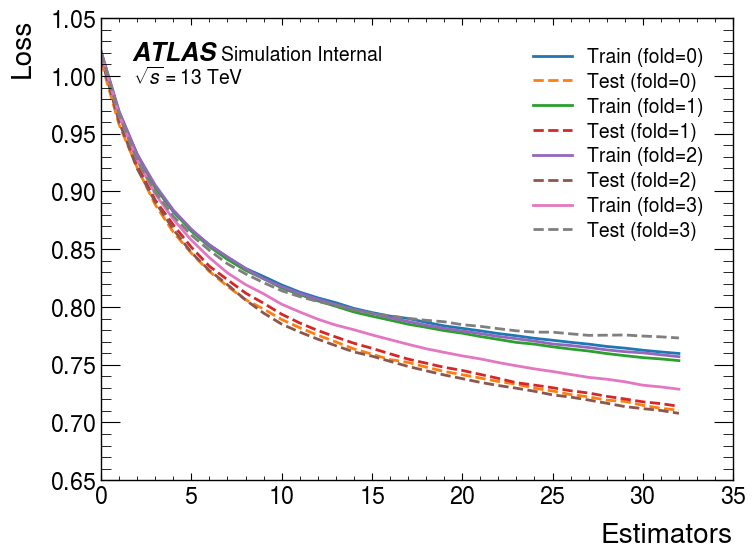

In [73]:
nfolds = 4
# Plotting the results
fig, ax = plt.subplots()
for fold in range(nfolds):
    estimators = range(0, n_estimators)
    ax.plot(estimators, trainloss[fold], label=f'Train ({fold=})')
    ax.plot(estimators, testloss[fold], label=f'Test ({fold=})', linestyle='--')

ax.legend()
ax.set_title('')
mplhep.atlas.label('Internal', data=False, ax=ax)   # true to remove Simulation
ax.set_xlabel('Estimators')
ax.set_ylabel('Loss')
plt.show()

In [251]:



nfolds = 4
testloss = {fold:[] for fold in range(nfolds)}
trainloss = {fold:[] for fold in range(nfolds)}

print(n_boosters)


for fold in range(nfolds):
    #n_boosters = len(models[fold].get_booster().get_dump()) # This ensures we are within the actual range
    for i in range(n_estimators):   # change these numbers accordingly
        # print("Value of tree:",i)
        # Predict probabilities for a subset of trees from 1 to i+1
        ypred_train = models[fold].predict_proba(X_train, iteration_range=(0, i+1))
        ypred_test = models[fold].predict_proba(X_test, iteration_range=(0, i+1))
        
        # Compute the log loss with the true labels and predicted probabilities
        loss_train = metrics.log_loss(y_train, ypred_train, sample_weight=np.abs(w_train))
        loss_test = metrics.log_loss(y_test, ypred_test, sample_weight=np.abs(w_test))
        
        # Append the loss values to respective lists
        trainloss[fold].append(loss_train)
        testloss[fold].append(loss_test)

99


In [252]:
mplhep.style.use('ATLAS')
nbins = 10

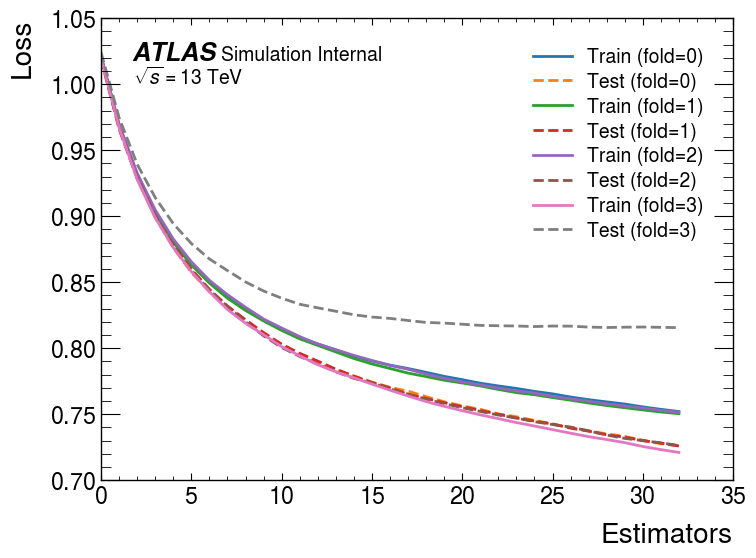

In [253]:
nbins = 10
nfolds = 4
n_estimators = 33
# Plotting the results
fig, ax = plt.subplots()
for fold in range(nfolds):
    estimators = range(0, n_estimators)
    ax.plot(estimators, trainloss[fold], label=f'Train ({fold=})')
    ax.plot(estimators, testloss[fold], label=f'Test ({fold=})', linestyle='--')

ax.legend()
ax.set_title('')
mplhep.atlas.label('Internal', data=False, ax=ax)   # true to remove Simulation
ax.set_xlabel('Estimators')
ax.set_ylabel('Loss')
plt.show()

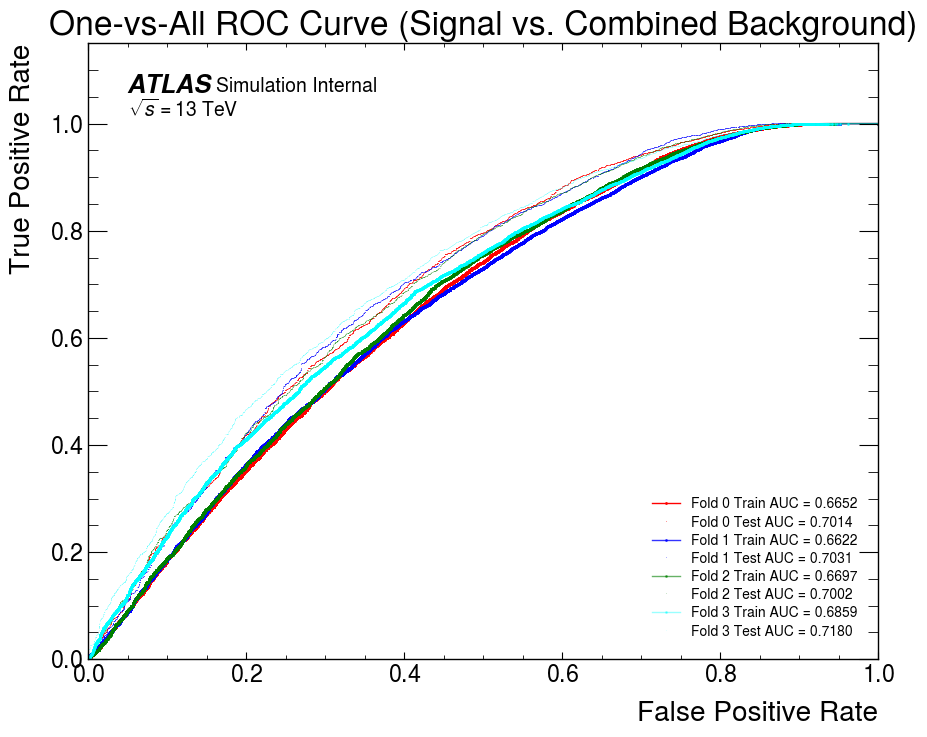

In [167]:

# Define number of folds
nfolds = 4

# Define colors for folds (ensuring strong contrast)
colors = ['red', 'blue', 'green', 'cyan']

# Set figure size
plt.figure(figsize=(10, 8))

# Loop over folds
for fold in range(nfolds):
    # Extract training data
    X_sig_train = df_sig_85[feature_cols][df_sig_85['eventNumber'] % nfolds != fold]
    X_sig_test = df_sig_85[feature_cols][df_sig_85['eventNumber'] % nfolds == fold]
    X_bkg_train_prompts = df_bkg_prompt_85_reweighted[feature_cols][df_bkg_prompt_85_reweighted['eventNumber'] % nfolds != fold]
    X_bkg_test_prompts = df_bkg_prompt_85_reweighted[feature_cols][df_bkg_prompt_85_reweighted['eventNumber'] % nfolds == fold]
    X_bkg_train_fakes = df_bkg_fakes_85_reweighted[feature_cols][df_bkg_fakes_85_reweighted['eventNumber'] % nfolds != fold]
    X_bkg_test_fakes = df_bkg_fakes_85_reweighted[feature_cols][df_bkg_fakes_85_reweighted['eventNumber'] % nfolds == fold]

    # Predict probabilities for training set
    results_sig_train = models[fold].predict_proba(X_sig_train)[:, 0]  # Signal class (0)
    results_bkg_prompts_train = models[fold].predict_proba(X_bkg_train_prompts)[:, 1]  # Background class 1
    results_bkg_fakes_train = models[fold].predict_proba(X_bkg_train_fakes)[:, 2]  # Background class 2

    # Predict probabilities for test set
    results_sig_test = models[fold].predict_proba(X_sig_test)[:, 0]  # Signal class (0)
    results_bkg_prompts_test = models[fold].predict_proba(X_bkg_test_prompts)[:, 1]  # Background class 1
    results_bkg_fakes_test = models[fold].predict_proba(X_bkg_test_fakes)[:, 2]  # Background class 2

    # Combine background categories into a single class
    results_bkg_train = np.concatenate([results_bkg_prompts_train, results_bkg_fakes_train])
    results_bkg_test = np.concatenate([results_bkg_prompts_test, results_bkg_fakes_test])

    # Create labels: 1 for signal, 0 for background
    y_train = np.concatenate([np.ones_like(results_sig_train), np.zeros_like(results_bkg_train)])
    y_test = np.concatenate([np.ones_like(results_sig_test), np.zeros_like(results_bkg_test)])

    # Combine predictions
    scores_train = np.concatenate([results_sig_train, results_bkg_train])
    scores_test = np.concatenate([results_sig_test, results_bkg_test])

    # Calculate ROC curve and AUC for training
    fpr_train, tpr_train, _ = metrics.roc_curve(y_train, scores_train, pos_label=1)
    auc_train = metrics.roc_auc_score(y_train, scores_train)

    # Calculate ROC curve and AUC for testing
    fpr_test, tpr_test, _ = metrics.roc_curve(y_test, scores_test, pos_label=1)
    auc_test = metrics.roc_auc_score(y_test, scores_test)

    # Set opacity (later folds get lower opacity)
    alpha_train = 1.0 - (0.2 * fold)  # Train curves: more visible
    alpha_test = 0.4 - (0.1 * fold)  # Test curves: slightly more transparent

    # Markers and linestyles
    marker_train = 'o'  # Signal: circles
    marker_test = ','  # Background: crosses
    linestyle_train = '-'  # Solid line for training
    linestyle_test = ''  # Dashed line for testing

    # Plot train AUC curve
    plt.plot(
        fpr_train, tpr_train,
        label=f'Fold {fold} Train AUC = {auc_train:.4f}',
        color=colors[fold], alpha=alpha_train,
        linewidth=1.0, linestyle=linestyle_train, marker=marker_train, markersize=1
    )

    # Plot test AUC curve
    plt.plot(
        fpr_test, tpr_test,
        label=f'Fold {fold} Test AUC = {auc_test:.4f}',
        color=colors[fold], alpha=alpha_test,
        linewidth=1.0, linestyle=linestyle_test, marker=marker_test, markersize=50
    )

# Formatting the plot
plt.legend(loc='lower right', fontsize=10)
plt.xlim(0, 1)
plt.ylim(0, 1.15)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('One-vs-All ROC Curve (Signal vs. Combined Background)')
mplhep.atlas.label('Internal', data=False)
plt.show()


Length of training scores: 273653
Length of testing scores: 91089
Length of training scores: 273740
Length of testing scores: 91002
Length of training scores: 273446
Length of testing scores: 91296
Length of training scores: 273387
Length of testing scores: 91355


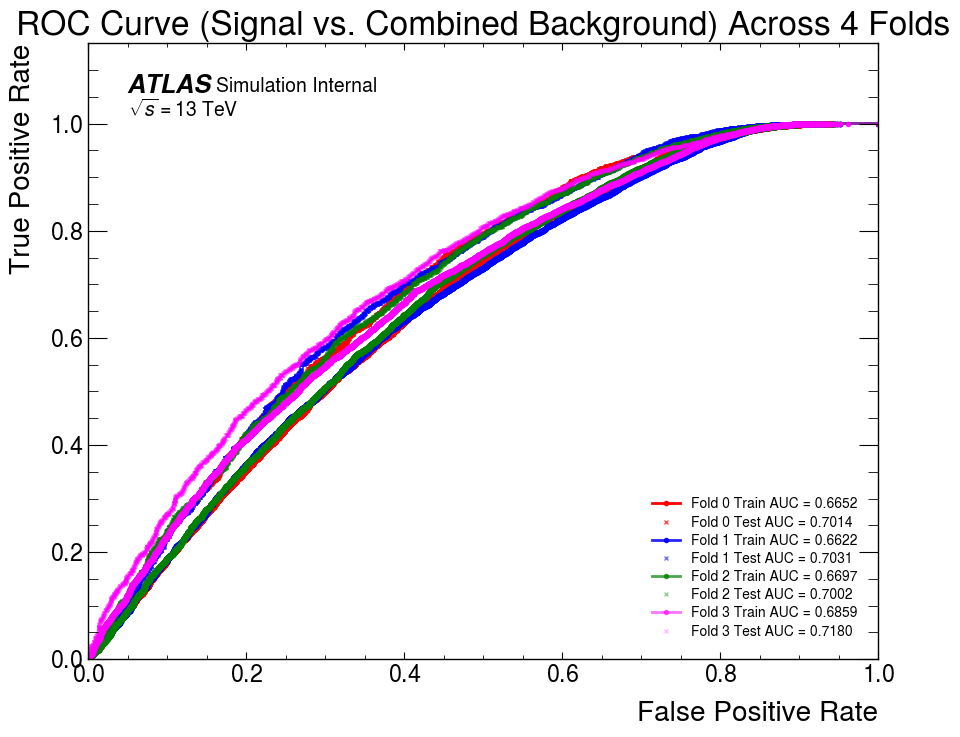

In [161]:
import numpy as np
import matplotlib.pyplot as plt
import mplhep
from sklearn import metrics

# Define colors for each fold
colors = ['red', 'blue', 'green', 'magenta']

# Set linestyles & markers for train and test
linestyle_train = '-'  # Solid line for training
linestyle_test = '--'  # Dashed line for testing
marker_train = 'o'  # Circles for train
marker_test = 'x'  # Crosses for test

# Set figure size
plt.figure(figsize=(10, 8))

# Loop over folds
for fold in range(4):
    # Extract train & test sets for the current fold
    X_sig_train = df_sig_85[feature_cols][df_sig_85['eventNumber'] % 4 != fold]
    X_sig_test = df_sig_85[feature_cols][df_sig_85['eventNumber'] % 4 == fold]
    X_bkg_train_prompts = df_bkg_prompt_85_reweighted[feature_cols][df_bkg_prompt_85_reweighted['eventNumber'] % 4 != fold]
    X_bkg_test_prompts = df_bkg_prompt_85_reweighted[feature_cols][df_bkg_prompt_85_reweighted['eventNumber'] % 4 == fold]
    X_bkg_train_fakes = df_bkg_fakes_85_reweighted[feature_cols][df_bkg_fakes_85_reweighted['eventNumber'] % 4 != fold]
    X_bkg_test_fakes = df_bkg_fakes_85_reweighted[feature_cols][df_bkg_fakes_85_reweighted['eventNumber'] % 4 == fold]

    # Predict probabilities
    results_sig_train = models[fold].predict_proba(X_sig_train)[:, 0]  # Class 0 (Signal)
    results_sig_test = models[fold].predict_proba(X_sig_test)[:, 0]  # Class 0 (Signal)

    # Combine background classes (1 & 2)
    results_bkg_train = np.concatenate([
        models[fold].predict_proba(X_bkg_train_prompts)[:, 1],  
        models[fold].predict_proba(X_bkg_train_fakes)[:, 2]  
    ])
    results_bkg_test = np.concatenate([
        models[fold].predict_proba(X_bkg_test_prompts)[:, 1],  
        models[fold].predict_proba(X_bkg_test_fakes)[:, 2]  
    ])

    # Create binary labels: 1 for Signal, 0 for Background
    y_train = np.concatenate([np.ones_like(results_sig_train), np.zeros_like(results_bkg_train)])
    y_test = np.concatenate([np.ones_like(results_sig_test), np.zeros_like(results_bkg_test)])

    # Combine predictions
    scores_train = np.concatenate([results_sig_train, results_bkg_train])
    print(f"Length of training scores:", len(scores_train))
    scores_test = np.concatenate([results_sig_test, results_bkg_test])
    print(f"Length of testing scores:", len(scores_test))


    # Calculate ROC curves and AUC scores
    fpr_train, tpr_train, _ = metrics.roc_curve(y_train, scores_train, pos_label=1)
    auc_train = metrics.roc_auc_score(y_train, scores_train)

    fpr_test, tpr_test, _ = metrics.roc_curve(y_test, scores_test, pos_label=1)
    auc_test = metrics.roc_auc_score(y_test, scores_test)

    # Set opacity (later folds get lower opacity)
    alpha_train = 1.0 - (0.15 * fold)  # Train: more visible
    alpha_test = 0.7 - (0.15 * fold)  # Test: slightly more transparent

    # Plot Train AUC Curve
    plt.plot(
        fpr_train, tpr_train, 
        label=f'Fold {fold} Train AUC = {auc_train:.4f}', 
        color=colors[fold], linestyle=linestyle_train, marker=marker_train, markersize=3, alpha=alpha_train
    )

    # Plot Test AUC Curve
    plt.plot(
        fpr_test, tpr_test, 
        label=f'Fold {fold} Test AUC = {auc_test:.4f}', 
        color=colors[fold], linestyle='', marker='x', markersize=3, alpha=alpha_test
    )

# Formatting the plot
plt.legend(loc='lower right', fontsize=10)
plt.xlim(0, 1)
plt.ylim(0, 1.15)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve (Signal vs. Combined Background) Across 4 Folds')
mplhep.atlas.label('Internal', data=False)
plt.show()



============================== Fold 0 ==============================

 **Class Distribution Check**
Training: Class 0: 269250, Class 1: 2100, Class 2: 2303
Testing: Class 0: 89637, Class 1: 704, Class 2: 748

 **Feature Statistics Across Folds**
Feature Mean (Train): [ 1.37263486e+05  8.96759329e+04  7.65304938e+04 -2.51958970e-03
  5.82590581e-04  9.73013180e+04  4.10860721e+04  1.47323520e+05
  9.10897508e+04  1.17727215e+05  1.78265541e+00  2.06248696e+00
  1.89104913e+00  7.24757266e-01  7.57528695e-01  1.39877323e+05
  9.00406668e+04  8.52118471e+05  4.66817466e+00  2.11329905e+00]
Feature Mean (Test): [ 1.37330737e+05  8.97379977e+04  7.63389502e+04 -2.61802791e-03
 -2.08240044e-03  9.69103115e+04  4.10017921e+04  1.46878508e+05
  9.10349755e+04  1.17366397e+05  1.78181778e+00  2.06112904e+00
  1.89560201e+00  7.25345541e-01  7.56040795e-01  1.39784937e+05
  8.98858984e+04  8.50327741e+05  4.66611775e+00  2.11592266e+00]
Feature Std (Train): [7.47485247e+04 4.58316182e+04 5.8067

/cvmfs/sft.cern.ch/lcg/views/LCG_105a_cuda/x86_64-el9-gcc11-opt/lib/python3.9/site-packages/xgboost/sklearn.py:885: UserWarning: `eval_metric` in `fit` method is deprecated for better compatibility with scikit-learn, use `eval_metric` in constructor or`set_params` instead.
  warnings.warn(


[0]	validation_0-mlogloss:0.98772	validation_1-mlogloss:0.98814
[1]	validation_0-mlogloss:0.91297	validation_1-mlogloss:0.91374
[2]	validation_0-mlogloss:0.86388	validation_1-mlogloss:0.86493
[3]	validation_0-mlogloss:0.82199	validation_1-mlogloss:0.82335
[4]	validation_0-mlogloss:0.79191	validation_1-mlogloss:0.79355
[5]	validation_0-mlogloss:0.76891	validation_1-mlogloss:0.77064
[6]	validation_0-mlogloss:0.74882	validation_1-mlogloss:0.75068
[7]	validation_0-mlogloss:0.73422	validation_1-mlogloss:0.73626
[8]	validation_0-mlogloss:0.72093	validation_1-mlogloss:0.72312
[9]	validation_0-mlogloss:0.71261	validation_1-mlogloss:0.71489
[10]	validation_0-mlogloss:0.70198	validation_1-mlogloss:0.70430
[11]	validation_0-mlogloss:0.69376	validation_1-mlogloss:0.69618
[12]	validation_0-mlogloss:0.68752	validation_1-mlogloss:0.69009
[13]	validation_0-mlogloss:0.68117	validation_1-mlogloss:0.68377
[14]	validation_0-mlogloss:0.67497	validation_1-mlogloss:0.67762
[15]	validation_0-mlogloss:0.67027	

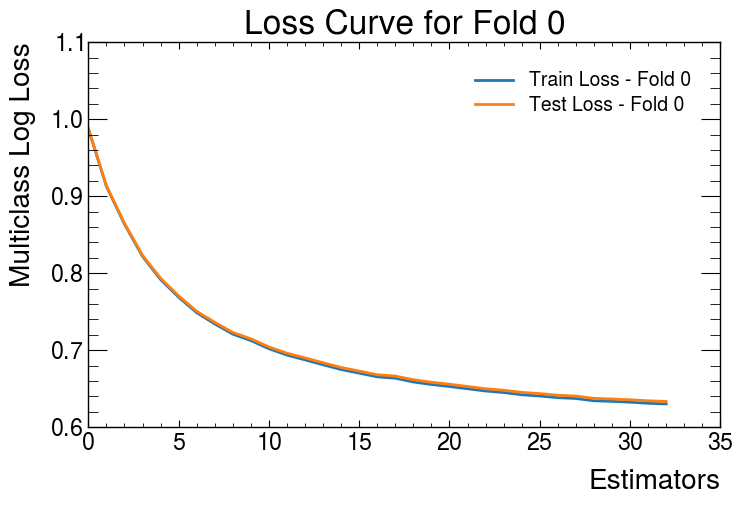


============================== Fold 1 ==============================

 **Class Distribution Check**
Training: Class 0: 269313, Class 1: 2106, Class 2: 2321
Testing: Class 0: 89574, Class 1: 698, Class 2: 730

 **Feature Statistics Across Folds**
Feature Mean (Train): [ 1.37279483e+05  8.96293451e+04  7.65302592e+04 -3.40852536e-03
  2.40326250e-04  9.72024223e+04  4.10696413e+04  1.47275996e+05
  9.11596644e+04  1.17724346e+05  1.78304596e+00  2.06274359e+00
  1.89437072e+00  7.23127785e-01  7.57967414e-01  1.39974675e+05
  8.99514455e+04  8.51553171e+05  4.66710747e+00  2.11433463e+00]
Feature Mean (Test): [ 1.37282681e+05  8.98781962e+04  7.63394725e+04  5.58549068e-05
 -1.05539462e-03  9.72074224e+04  4.10511366e+04  1.47021037e+05
  9.08246184e+04  1.17374681e+05  1.78064218e+00  2.06035577e+00
  1.88561480e+00  7.30247687e-01  7.54719676e-01  1.39492009e+05
  9.01541340e+04  8.52026486e+05  4.66932595e+00  2.11281008e+00]
Feature Std (Train): [7.46821720e+04 4.58742258e+04 5.8044

/cvmfs/sft.cern.ch/lcg/views/LCG_105a_cuda/x86_64-el9-gcc11-opt/lib/python3.9/site-packages/xgboost/sklearn.py:885: UserWarning: `eval_metric` in `fit` method is deprecated for better compatibility with scikit-learn, use `eval_metric` in constructor or`set_params` instead.
  warnings.warn(


[0]	validation_0-mlogloss:0.99330	validation_1-mlogloss:0.99337
[1]	validation_0-mlogloss:0.91838	validation_1-mlogloss:0.91846
[2]	validation_0-mlogloss:0.86510	validation_1-mlogloss:0.86492
[3]	validation_0-mlogloss:0.82320	validation_1-mlogloss:0.82309
[4]	validation_0-mlogloss:0.79611	validation_1-mlogloss:0.79573
[5]	validation_0-mlogloss:0.77093	validation_1-mlogloss:0.77055
[6]	validation_0-mlogloss:0.75191	validation_1-mlogloss:0.75154
[7]	validation_0-mlogloss:0.73605	validation_1-mlogloss:0.73557
[8]	validation_0-mlogloss:0.72092	validation_1-mlogloss:0.72043
[9]	validation_0-mlogloss:0.71189	validation_1-mlogloss:0.71149
[10]	validation_0-mlogloss:0.70337	validation_1-mlogloss:0.70299
[11]	validation_0-mlogloss:0.69555	validation_1-mlogloss:0.69519
[12]	validation_0-mlogloss:0.68868	validation_1-mlogloss:0.68821
[13]	validation_0-mlogloss:0.68292	validation_1-mlogloss:0.68259
[14]	validation_0-mlogloss:0.67640	validation_1-mlogloss:0.67615
[15]	validation_0-mlogloss:0.67369	

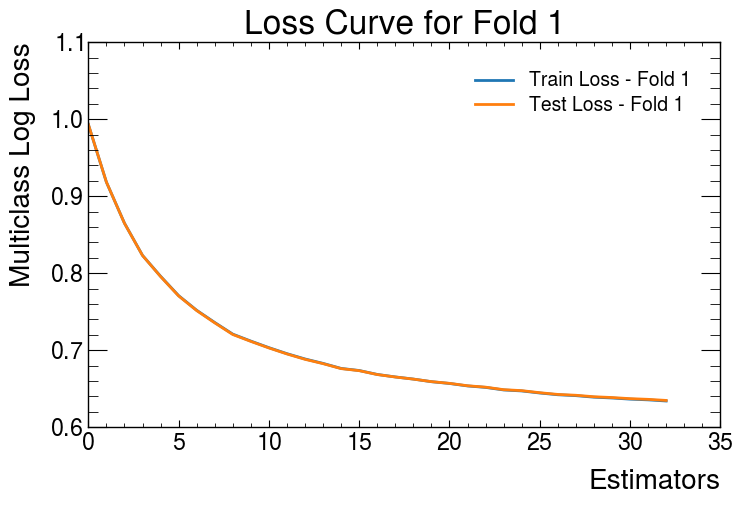


============================== Fold 2 ==============================

 **Class Distribution Check**
Training: Class 0: 269051, Class 1: 2127, Class 2: 2268
Testing: Class 0: 89836, Class 1: 677, Class 2: 783

 **Feature Statistics Across Folds**
Feature Mean (Train): [ 1.37294300e+05  8.97279653e+04  7.63377159e+04 -2.41233441e-03
 -7.27507550e-04  9.71328187e+04  4.10352176e+04  1.47318420e+05
  9.10532966e+04  1.17558581e+05  1.78236288e+00  2.06381382e+00
  1.89130845e+00  7.24797583e-01  7.56090782e-01  1.39865992e+05
  9.00444344e+04  8.51702923e+05  4.66782107e+00  2.11374868e+00]
Feature Mean (Test): [ 1.37238290e+05  8.95820116e+04  7.69167848e+04 -2.93905132e-03
  1.84759371e-03  9.74158801e+04  4.11543007e+04  1.46894790e+05
  9.11442859e+04  1.17872300e+05  1.78269585e+00  2.05715796e+00
  1.89481496e+00  7.25223449e-01  7.60350946e-01  1.39819086e+05
  8.98749647e+04  8.51576433e+05  4.66718148e+00  2.11457000e+00]
Feature Std (Train): [7.46978492e+04 4.60706744e+04 5.7875

/cvmfs/sft.cern.ch/lcg/views/LCG_105a_cuda/x86_64-el9-gcc11-opt/lib/python3.9/site-packages/xgboost/sklearn.py:885: UserWarning: `eval_metric` in `fit` method is deprecated for better compatibility with scikit-learn, use `eval_metric` in constructor or`set_params` instead.
  warnings.warn(


[0]	validation_0-mlogloss:0.99192	validation_1-mlogloss:0.99197
[1]	validation_0-mlogloss:0.91667	validation_1-mlogloss:0.91664
[2]	validation_0-mlogloss:0.86158	validation_1-mlogloss:0.86169
[3]	validation_0-mlogloss:0.82623	validation_1-mlogloss:0.82635
[4]	validation_0-mlogloss:0.79508	validation_1-mlogloss:0.79521
[5]	validation_0-mlogloss:0.77024	validation_1-mlogloss:0.77045
[6]	validation_0-mlogloss:0.75152	validation_1-mlogloss:0.75192
[7]	validation_0-mlogloss:0.73695	validation_1-mlogloss:0.73747
[8]	validation_0-mlogloss:0.72245	validation_1-mlogloss:0.72297
[9]	validation_0-mlogloss:0.71133	validation_1-mlogloss:0.71195
[10]	validation_0-mlogloss:0.70015	validation_1-mlogloss:0.70083
[11]	validation_0-mlogloss:0.69185	validation_1-mlogloss:0.69264
[12]	validation_0-mlogloss:0.68569	validation_1-mlogloss:0.68656
[13]	validation_0-mlogloss:0.67996	validation_1-mlogloss:0.68091
[14]	validation_0-mlogloss:0.67364	validation_1-mlogloss:0.67458
[15]	validation_0-mlogloss:0.67070	

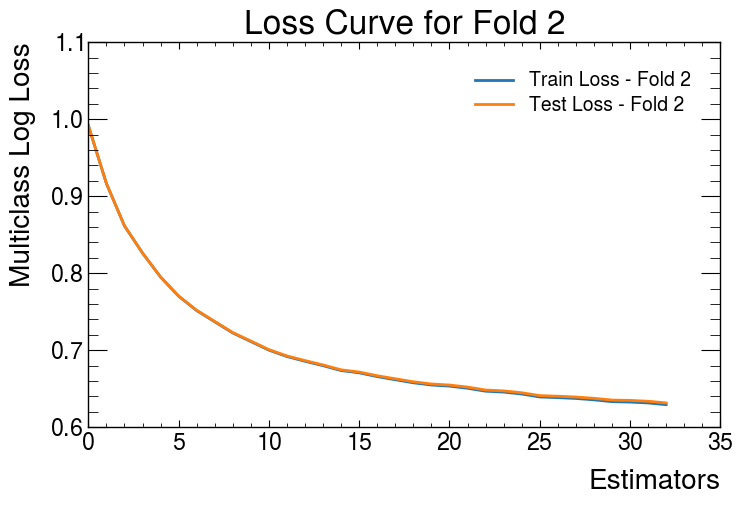


============================== Fold 3 ==============================

 **Class Distribution Check**
Training: Class 0: 269047, Class 1: 2079, Class 2: 2261
Testing: Class 0: 89840, Class 1: 725, Class 2: 790

 **Feature Statistics Across Folds**
Feature Mean (Train): [ 1.37283869e+05  8.97325747e+04  7.65320886e+04 -1.83517968e-03
 -4.28143545e-04  9.71780422e+04  4.10691467e+04  1.46931389e+05
  9.10014578e+04  1.17538098e+05  1.78171969e+00  2.05954552e+00
  1.89201475e+00  7.26936541e-01  7.57040386e-01  1.39698834e+05
  8.99715344e+04  8.51310193e+05  4.66754089e+00  2.11443487e+00]
Feature Mean (Test): [ 1.37269544e+05  8.95683118e+04  7.63347353e+04 -4.66589195e-03
  9.50060377e-04  9.72803625e+04  4.10526881e+04  1.48053286e+05
  9.12993588e+04  1.17933395e+05  1.78462044e+00  2.06993547e+00
  1.89269906e+00  7.18822177e-01  7.57506431e-01  1.40319349e+05
  9.00932331e+04  8.52751787e+05  4.66802036e+00  2.11251600e+00]
Feature Std (Train): [7.46937440e+04 4.61100462e+04 5.7931

/cvmfs/sft.cern.ch/lcg/views/LCG_105a_cuda/x86_64-el9-gcc11-opt/lib/python3.9/site-packages/xgboost/sklearn.py:885: UserWarning: `eval_metric` in `fit` method is deprecated for better compatibility with scikit-learn, use `eval_metric` in constructor or`set_params` instead.
  warnings.warn(


[0]	validation_0-mlogloss:0.98947	validation_1-mlogloss:0.98952
[1]	validation_0-mlogloss:0.91310	validation_1-mlogloss:0.91311
[2]	validation_0-mlogloss:0.85734	validation_1-mlogloss:0.85735
[3]	validation_0-mlogloss:0.81655	validation_1-mlogloss:0.81675
[4]	validation_0-mlogloss:0.78607	validation_1-mlogloss:0.78627
[5]	validation_0-mlogloss:0.75924	validation_1-mlogloss:0.75937
[6]	validation_0-mlogloss:0.73921	validation_1-mlogloss:0.73935
[7]	validation_0-mlogloss:0.72278	validation_1-mlogloss:0.72300
[8]	validation_0-mlogloss:0.70984	validation_1-mlogloss:0.71000
[9]	validation_0-mlogloss:0.70035	validation_1-mlogloss:0.70052
[10]	validation_0-mlogloss:0.68787	validation_1-mlogloss:0.68806
[11]	validation_0-mlogloss:0.68078	validation_1-mlogloss:0.68102
[12]	validation_0-mlogloss:0.67368	validation_1-mlogloss:0.67391
[13]	validation_0-mlogloss:0.66611	validation_1-mlogloss:0.66636
[14]	validation_0-mlogloss:0.66266	validation_1-mlogloss:0.66286
[15]	validation_0-mlogloss:0.65721	

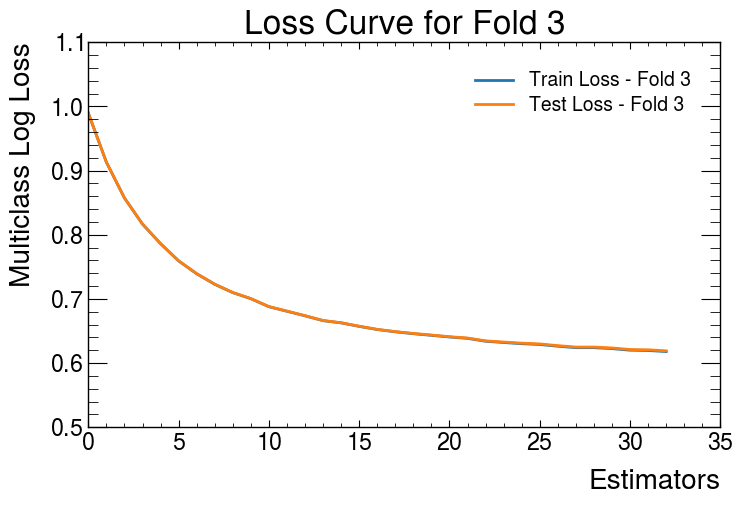

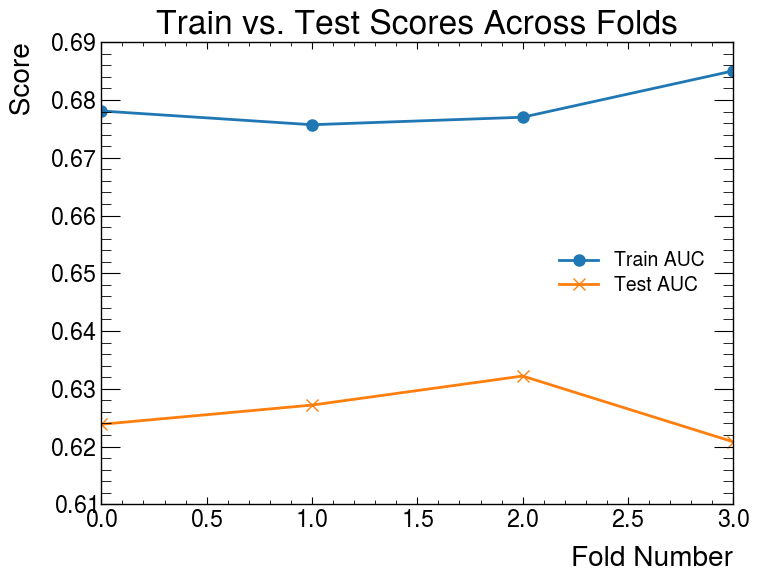

In [229]:
nfolds = 4

models_val = []
scores_train, scores_test = [], []
testloss = {fold: [] for fold in range(nfolds)}
trainloss = {fold: [] for fold in range(nfolds)}

for fold in range(nfolds):
    print(f"\n{'='*30} Fold {fold} {'='*30}")

    # Extract training and testing sets
    X_sig_train = df_sig_85[feature_cols][df_sig_85['eventNumber'] % nfolds != fold]
    w_sig_train = df_sig_85['weight'][df_sig_85['eventNumber'] % nfolds != fold]
    X_sig_test = df_sig_85[feature_cols][df_sig_85['eventNumber'] % nfolds == fold]
    w_sig_test = df_sig_85['weight'][df_sig_85['eventNumber'] % nfolds == fold]

    X_bkg_train_prompts = df_bkg_prompt_85_reweighted[feature_cols][df_bkg_prompt_85_reweighted['eventNumber'] % nfolds != fold]
    w_bkg_train_prompts = df_bkg_prompt_85_reweighted['weight'][df_bkg_prompt_85_reweighted['eventNumber'] % nfolds != fold]
    X_bkg_test_prompts = df_bkg_prompt_85_reweighted[feature_cols][df_bkg_prompt_85_reweighted['eventNumber'] % nfolds == fold]
    w_bkg_test_prompts = df_bkg_prompt_85_reweighted['weight'][df_bkg_prompt_85_reweighted['eventNumber'] % nfolds == fold]

    X_bkg_train_fakes = df_bkg_fakes_85_reweighted[feature_cols][df_bkg_fakes_85_reweighted['eventNumber'] % nfolds != fold]
    w_bkg_train_fakes = df_bkg_fakes_85_reweighted['weight'][df_bkg_fakes_85_reweighted['eventNumber'] % nfolds != fold]
    X_bkg_test_fakes = df_bkg_fakes_85_reweighted[feature_cols][df_bkg_fakes_85_reweighted['eventNumber'] % nfolds == fold]
    w_bkg_test_fakes = df_bkg_fakes_85_reweighted['weight'][df_bkg_fakes_85_reweighted['eventNumber'] % nfolds == fold]

    # Combine classes
    y_train = np.concatenate([np.zeros_like(w_sig_train), np.ones_like(w_bkg_train_prompts), 2 * np.ones_like(w_bkg_train_fakes)])
    X_train = np.concatenate([X_sig_train, X_bkg_train_prompts, X_bkg_train_fakes])
    w_train = np.concatenate([w_sig_train, w_bkg_train_prompts, w_bkg_train_fakes])

    y_test = np.concatenate([np.zeros_like(w_sig_test), np.ones_like(w_bkg_test_prompts), 2 * np.ones_like(w_bkg_test_fakes)])
    X_test = np.concatenate([X_sig_test, X_bkg_test_prompts, X_bkg_test_fakes])
    w_test = np.concatenate([w_sig_test, w_bkg_test_prompts, w_bkg_test_fakes])

    ### **Validation Check 1: Dataset Integrity**
    print("\n **Class Distribution Check**")
    print(f"Training: Class 0: {np.sum(y_train == 0)}, Class 1: {np.sum(y_train == 1)}, Class 2: {np.sum(y_train == 2)}")
    print(f"Testing: Class 0: {np.sum(y_test == 0)}, Class 1: {np.sum(y_test == 1)}, Class 2: {np.sum(y_test == 2)}")


    ### **Validation Check 2: Feature Mean & Standard Deviation Comparison**
    print("\n **Feature Statistics Across Folds**")
    print(f"Feature Mean (Train): {X_train.mean(axis=0)}")
    print(f"Feature Mean (Test): {X_test.mean(axis=0)}")
    print(f"Feature Std (Train): {X_train.std(axis=0)}")
    print(f"Feature Std (Test): {X_test.std(axis=0)}")

    # Initialize XGBoost model
    model = XGBClassifier(
        tree_method="hist",
        verbosity=2,
        n_estimators=33,
        objective="multi:softmax",
        num_class=3
    )

    # Train the model
    eval_set = [(X_train, y_train), (X_test, y_test)]
    model.fit(
        X_train, y_train, sample_weight=np.abs(w_train),
        eval_set=eval_set, eval_metric="mlogloss", verbose=True     # using multi-class log loss function
    )

    models_val.append(model)
    scores_train.append(model.score(X_train, y_train, sample_weight=np.abs(w_train)))   # calculating accuracy
    scores_test.append(model.score(X_test, y_test, sample_weight=np.abs(w_test)))

    print(len(scores_train), len(scores_test))
    # Track loss
    results = model.evals_result()
    trainloss[fold] = results["validation_0"]["mlogloss"]
    testloss[fold] = results["validation_1"]["mlogloss"]

    ### **Validation Check 4: Loss Curve Plot**
    plt.figure(figsize=(8, 5))
    plt.plot(trainloss[fold], label=f"Train Loss - Fold {fold}")
    plt.plot(testloss[fold], label=f"Test Loss - Fold {fold}")
    plt.xlabel("Estimators")
    plt.ylabel("Multiclass Log Loss")
    plt.legend()
    plt.title(f"Loss Curve for Fold {fold}")
    plt.show()

# Plot AUC across folds
plt.figure(figsize=(8, 6))
plt.plot(range(nfolds), scores_train, label="Train AUC", marker="o")
plt.plot(range(nfolds), scores_test, label="Test AUC", marker="x")
plt.xlabel("Fold Number")
plt.ylabel(" Score")
plt.legend()
plt.title("Train vs. Test Scores Across Folds")
plt.show()



============================== Fold 0 ==============================

 **Class Distribution Check**
Training: Class 0: 269250, Class 1: 2100, Class 2: 2303
Testing: Class 0: 89637, Class 1: 704, Class 2: 748

 **Feature Statistics Across Folds**
Feature Mean (Train): [ 1.37263486e+05  8.96759329e+04  7.65304938e+04 -2.51958970e-03
  5.82590581e-04  9.73013180e+04  4.10860721e+04  1.47323520e+05
  9.10897508e+04  1.17727215e+05  1.78265541e+00  2.06248696e+00
  1.89104913e+00  7.24757266e-01  7.57528695e-01  1.39877323e+05
  9.00406668e+04  8.52118471e+05  4.66817466e+00  2.11329905e+00]
Feature Mean (Test): [ 1.37330737e+05  8.97379977e+04  7.63389502e+04 -2.61802791e-03
 -2.08240044e-03  9.69103115e+04  4.10017921e+04  1.46878508e+05
  9.10349755e+04  1.17366397e+05  1.78181778e+00  2.06112904e+00
  1.89560201e+00  7.25345541e-01  7.56040795e-01  1.39784937e+05
  8.98858984e+04  8.50327741e+05  4.66611775e+00  2.11592266e+00]
Feature Std (Train): [7.47485247e+04 4.58316182e+04 5.8067

/cvmfs/sft.cern.ch/lcg/views/LCG_105a_cuda/x86_64-el9-gcc11-opt/lib/python3.9/site-packages/xgboost/sklearn.py:885: UserWarning: `eval_metric` in `fit` method is deprecated for better compatibility with scikit-learn, use `eval_metric` in constructor or`set_params` instead.
  warnings.warn(


[0]	validation_0-mlogloss:0.71932	validation_1-mlogloss:0.71956
[1]	validation_0-mlogloss:0.50633	validation_1-mlogloss:0.50680
[2]	validation_0-mlogloss:0.37091	validation_1-mlogloss:0.37167
[3]	validation_0-mlogloss:0.28027	validation_1-mlogloss:0.28129
[4]	validation_0-mlogloss:0.21785	validation_1-mlogloss:0.21914
[5]	validation_0-mlogloss:0.17424	validation_1-mlogloss:0.17580
[6]	validation_0-mlogloss:0.14351	validation_1-mlogloss:0.14539
[7]	validation_0-mlogloss:0.12178	validation_1-mlogloss:0.12399
[8]	validation_0-mlogloss:0.10634	validation_1-mlogloss:0.10892
[9]	validation_0-mlogloss:0.09537	validation_1-mlogloss:0.09842
[10]	validation_0-mlogloss:0.08758	validation_1-mlogloss:0.09105
[11]	validation_0-mlogloss:0.08196	validation_1-mlogloss:0.08591
[12]	validation_0-mlogloss:0.07790	validation_1-mlogloss:0.08240
[13]	validation_0-mlogloss:0.07494	validation_1-mlogloss:0.07999
[14]	validation_0-mlogloss:0.07267	validation_1-mlogloss:0.07828
[15]	validation_0-mlogloss:0.07089	

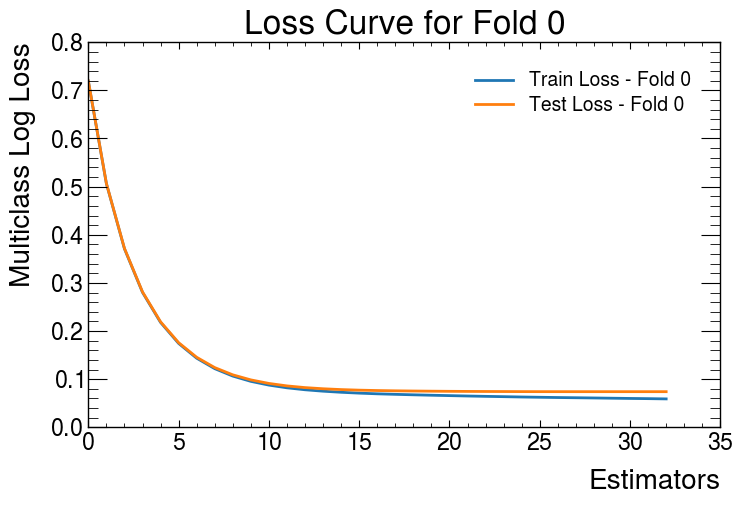


============================== Fold 1 ==============================

 **Class Distribution Check**
Training: Class 0: 269313, Class 1: 2106, Class 2: 2321
Testing: Class 0: 89574, Class 1: 698, Class 2: 730

 **Feature Statistics Across Folds**
Feature Mean (Train): [ 1.37279483e+05  8.96293451e+04  7.65302592e+04 -3.40852536e-03
  2.40326250e-04  9.72024223e+04  4.10696413e+04  1.47275996e+05
  9.11596644e+04  1.17724346e+05  1.78304596e+00  2.06274359e+00
  1.89437072e+00  7.23127785e-01  7.57967414e-01  1.39974675e+05
  8.99514455e+04  8.51553171e+05  4.66710747e+00  2.11433463e+00]
Feature Mean (Test): [ 1.37282681e+05  8.98781962e+04  7.63394725e+04  5.58549068e-05
 -1.05539462e-03  9.72074224e+04  4.10511366e+04  1.47021037e+05
  9.08246184e+04  1.17374681e+05  1.78064218e+00  2.06035577e+00
  1.88561480e+00  7.30247687e-01  7.54719676e-01  1.39492009e+05
  9.01541340e+04  8.52026486e+05  4.66932595e+00  2.11281008e+00]
Feature Std (Train): [7.46821720e+04 4.58742258e+04 5.8044

/cvmfs/sft.cern.ch/lcg/views/LCG_105a_cuda/x86_64-el9-gcc11-opt/lib/python3.9/site-packages/xgboost/sklearn.py:885: UserWarning: `eval_metric` in `fit` method is deprecated for better compatibility with scikit-learn, use `eval_metric` in constructor or`set_params` instead.
  warnings.warn(


[0]	validation_0-mlogloss:0.71942	validation_1-mlogloss:0.71948
[1]	validation_0-mlogloss:0.50646	validation_1-mlogloss:0.50651
[2]	validation_0-mlogloss:0.37109	validation_1-mlogloss:0.37117
[3]	validation_0-mlogloss:0.28051	validation_1-mlogloss:0.28063
[4]	validation_0-mlogloss:0.21814	validation_1-mlogloss:0.21837
[5]	validation_0-mlogloss:0.17458	validation_1-mlogloss:0.17493
[6]	validation_0-mlogloss:0.14389	validation_1-mlogloss:0.14442
[7]	validation_0-mlogloss:0.12218	validation_1-mlogloss:0.12291
[8]	validation_0-mlogloss:0.10678	validation_1-mlogloss:0.10777
[9]	validation_0-mlogloss:0.09584	validation_1-mlogloss:0.09712
[10]	validation_0-mlogloss:0.08807	validation_1-mlogloss:0.08963
[11]	validation_0-mlogloss:0.08245	validation_1-mlogloss:0.08451
[12]	validation_0-mlogloss:0.07839	validation_1-mlogloss:0.08089
[13]	validation_0-mlogloss:0.07540	validation_1-mlogloss:0.07841
[14]	validation_0-mlogloss:0.07314	validation_1-mlogloss:0.07658
[15]	validation_0-mlogloss:0.07132	

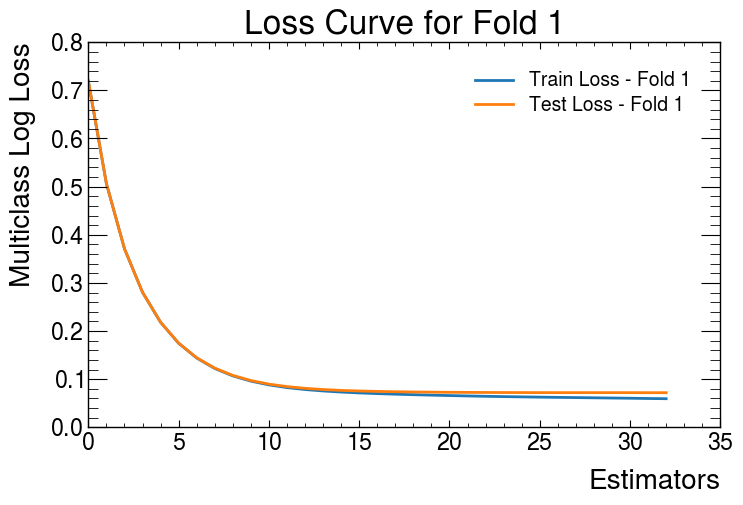


============================== Fold 2 ==============================

 **Class Distribution Check**
Training: Class 0: 269051, Class 1: 2127, Class 2: 2268
Testing: Class 0: 89836, Class 1: 677, Class 2: 783

 **Feature Statistics Across Folds**
Feature Mean (Train): [ 1.37294300e+05  8.97279653e+04  7.63377159e+04 -2.41233441e-03
 -7.27507550e-04  9.71328187e+04  4.10352176e+04  1.47318420e+05
  9.10532966e+04  1.17558581e+05  1.78236288e+00  2.06381382e+00
  1.89130845e+00  7.24797583e-01  7.56090782e-01  1.39865992e+05
  9.00444344e+04  8.51702923e+05  4.66782107e+00  2.11374868e+00]
Feature Mean (Test): [ 1.37238290e+05  8.95820116e+04  7.69167848e+04 -2.93905132e-03
  1.84759371e-03  9.74158801e+04  4.11543007e+04  1.46894790e+05
  9.11442859e+04  1.17872300e+05  1.78269585e+00  2.05715796e+00
  1.89481496e+00  7.25223449e-01  7.60350946e-01  1.39819086e+05
  8.98749647e+04  8.51576433e+05  4.66718148e+00  2.11457000e+00]
Feature Std (Train): [7.46978492e+04 4.60706744e+04 5.7875

/cvmfs/sft.cern.ch/lcg/views/LCG_105a_cuda/x86_64-el9-gcc11-opt/lib/python3.9/site-packages/xgboost/sklearn.py:885: UserWarning: `eval_metric` in `fit` method is deprecated for better compatibility with scikit-learn, use `eval_metric` in constructor or`set_params` instead.
  warnings.warn(


[0]	validation_0-mlogloss:0.71921	validation_1-mlogloss:0.71977
[1]	validation_0-mlogloss:0.50615	validation_1-mlogloss:0.50717
[2]	validation_0-mlogloss:0.37071	validation_1-mlogloss:0.37209
[3]	validation_0-mlogloss:0.27999	validation_1-mlogloss:0.28175
[4]	validation_0-mlogloss:0.21758	validation_1-mlogloss:0.21971
[5]	validation_0-mlogloss:0.17399	validation_1-mlogloss:0.17648
[6]	validation_0-mlogloss:0.14322	validation_1-mlogloss:0.14615
[7]	validation_0-mlogloss:0.12148	validation_1-mlogloss:0.12480
[8]	validation_0-mlogloss:0.10604	validation_1-mlogloss:0.10978
[9]	validation_0-mlogloss:0.09510	validation_1-mlogloss:0.09930
[10]	validation_0-mlogloss:0.08727	validation_1-mlogloss:0.09200
[11]	validation_0-mlogloss:0.08167	validation_1-mlogloss:0.08685
[12]	validation_0-mlogloss:0.07770	validation_1-mlogloss:0.08329
[13]	validation_0-mlogloss:0.07476	validation_1-mlogloss:0.08082
[14]	validation_0-mlogloss:0.07246	validation_1-mlogloss:0.07912
[15]	validation_0-mlogloss:0.07070	

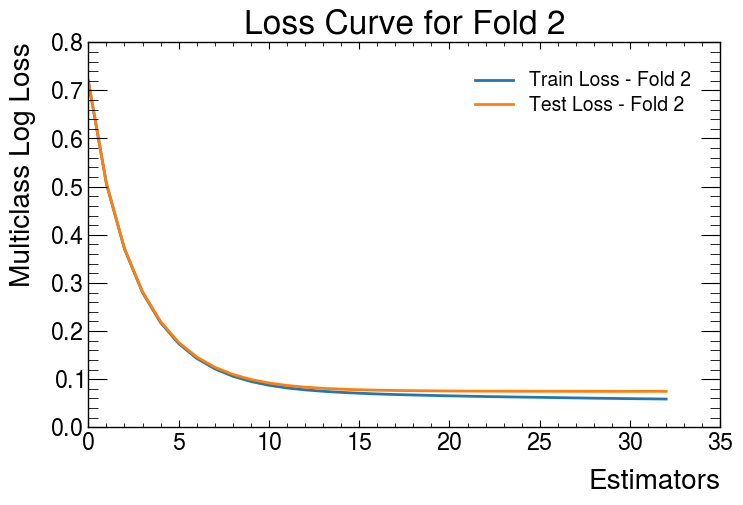


============================== Fold 3 ==============================

 **Class Distribution Check**
Training: Class 0: 269047, Class 1: 2079, Class 2: 2261
Testing: Class 0: 89840, Class 1: 725, Class 2: 790

 **Feature Statistics Across Folds**
Feature Mean (Train): [ 1.37283869e+05  8.97325747e+04  7.65320886e+04 -1.83517968e-03
 -4.28143545e-04  9.71780422e+04  4.10691467e+04  1.46931389e+05
  9.10014578e+04  1.17538098e+05  1.78171969e+00  2.05954552e+00
  1.89201475e+00  7.26936541e-01  7.57040386e-01  1.39698834e+05
  8.99715344e+04  8.51310193e+05  4.66754089e+00  2.11443487e+00]
Feature Mean (Test): [ 1.37269544e+05  8.95683118e+04  7.63347353e+04 -4.66589195e-03
  9.50060377e-04  9.72803625e+04  4.10526881e+04  1.48053286e+05
  9.12993588e+04  1.17933395e+05  1.78462044e+00  2.06993547e+00
  1.89269906e+00  7.18822177e-01  7.57506431e-01  1.40319349e+05
  9.00932331e+04  8.52751787e+05  4.66802036e+00  2.11251600e+00]
Feature Std (Train): [7.46937440e+04 4.61100462e+04 5.7931

/cvmfs/sft.cern.ch/lcg/views/LCG_105a_cuda/x86_64-el9-gcc11-opt/lib/python3.9/site-packages/xgboost/sklearn.py:885: UserWarning: `eval_metric` in `fit` method is deprecated for better compatibility with scikit-learn, use `eval_metric` in constructor or`set_params` instead.
  warnings.warn(


[0]	validation_0-mlogloss:0.71912	validation_1-mlogloss:0.71987
[1]	validation_0-mlogloss:0.50602	validation_1-mlogloss:0.50733
[2]	validation_0-mlogloss:0.37055	validation_1-mlogloss:0.37233
[3]	validation_0-mlogloss:0.27985	validation_1-mlogloss:0.28208
[4]	validation_0-mlogloss:0.21739	validation_1-mlogloss:0.22006
[5]	validation_0-mlogloss:0.17376	validation_1-mlogloss:0.17689
[6]	validation_0-mlogloss:0.14299	validation_1-mlogloss:0.14653
[7]	validation_0-mlogloss:0.12123	validation_1-mlogloss:0.12523
[8]	validation_0-mlogloss:0.10577	validation_1-mlogloss:0.11035
[9]	validation_0-mlogloss:0.09481	validation_1-mlogloss:0.09988
[10]	validation_0-mlogloss:0.08695	validation_1-mlogloss:0.09257
[11]	validation_0-mlogloss:0.08140	validation_1-mlogloss:0.08752
[12]	validation_0-mlogloss:0.07742	validation_1-mlogloss:0.08407
[13]	validation_0-mlogloss:0.07443	validation_1-mlogloss:0.08162
[14]	validation_0-mlogloss:0.07214	validation_1-mlogloss:0.07989
[15]	validation_0-mlogloss:0.07033	

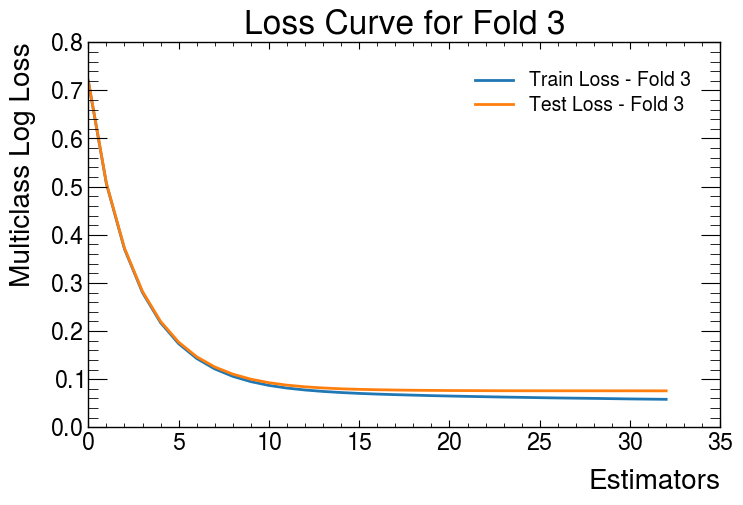

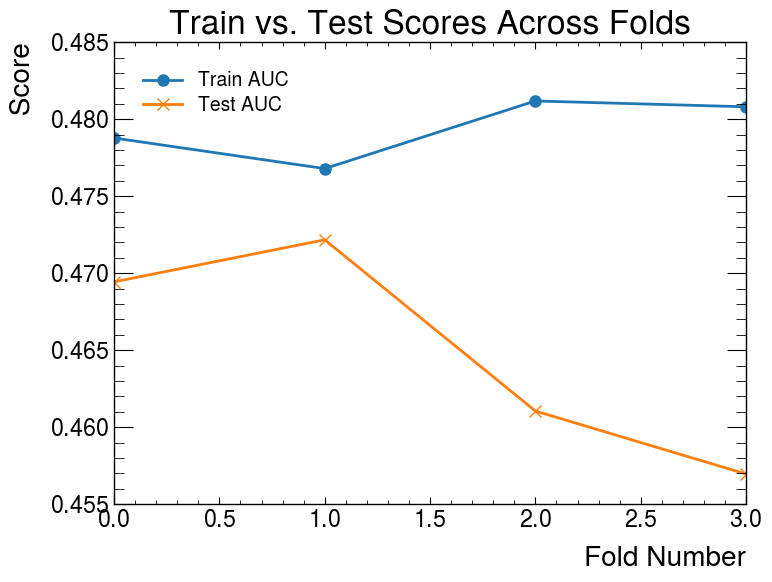

In [242]:
nfolds = 4

models_val = []
scores_train, scores_test = [], []
testloss = {fold: [] for fold in range(nfolds)}
trainloss = {fold: [] for fold in range(nfolds)}

for fold in range(nfolds):
    print(f"\n{'='*30} Fold {fold} {'='*30}")

    # Extract training and testing sets
    X_sig_train = df_sig_85[feature_cols][df_sig_85['eventNumber'] % nfolds != fold]
    w_sig_train = df_sig_85['weight'][df_sig_85['eventNumber'] % nfolds != fold]
    X_sig_test = df_sig_85[feature_cols][df_sig_85['eventNumber'] % nfolds == fold]
    w_sig_test = df_sig_85['weight'][df_sig_85['eventNumber'] % nfolds == fold]

    X_bkg_train_prompts = df_bkg_prompt_85_reweighted[feature_cols][df_bkg_prompt_85_reweighted['eventNumber'] % nfolds != fold]
    w_bkg_train_prompts = df_bkg_prompt_85_reweighted['weight'][df_bkg_prompt_85_reweighted['eventNumber'] % nfolds != fold]
    X_bkg_test_prompts = df_bkg_prompt_85_reweighted[feature_cols][df_bkg_prompt_85_reweighted['eventNumber'] % nfolds == fold]
    w_bkg_test_prompts = df_bkg_prompt_85_reweighted['weight'][df_bkg_prompt_85_reweighted['eventNumber'] % nfolds == fold]

    X_bkg_train_fakes = df_bkg_fakes_85_reweighted[feature_cols][df_bkg_fakes_85_reweighted['eventNumber'] % nfolds != fold]
    w_bkg_train_fakes = df_bkg_fakes_85_reweighted['weight'][df_bkg_fakes_85_reweighted['eventNumber'] % nfolds != fold]
    X_bkg_test_fakes = df_bkg_fakes_85_reweighted[feature_cols][df_bkg_fakes_85_reweighted['eventNumber'] % nfolds == fold]
    w_bkg_test_fakes = df_bkg_fakes_85_reweighted['weight'][df_bkg_fakes_85_reweighted['eventNumber'] % nfolds == fold]

    # Combine classes
    y_train = np.concatenate([np.zeros_like(w_sig_train), np.ones_like(w_bkg_train_prompts), 2 * np.ones_like(w_bkg_train_fakes)])
    X_train = np.concatenate([X_sig_train, X_bkg_train_prompts, X_bkg_train_fakes])
    w_train = np.concatenate([w_sig_train, w_bkg_train_prompts, w_bkg_train_fakes])

    y_test = np.concatenate([np.zeros_like(w_sig_test), np.ones_like(w_bkg_test_prompts), 2 * np.ones_like(w_bkg_test_fakes)])
    X_test = np.concatenate([X_sig_test, X_bkg_test_prompts, X_bkg_test_fakes])
    w_test = np.concatenate([w_sig_test, w_bkg_test_prompts, w_bkg_test_fakes])

    ### **Validation Check 1: Dataset Integrity**
    print("\n **Class Distribution Check**")
    print(f"Training: Class 0: {np.sum(y_train == 0)}, Class 1: {np.sum(y_train == 1)}, Class 2: {np.sum(y_train == 2)}")
    print(f"Testing: Class 0: {np.sum(y_test == 0)}, Class 1: {np.sum(y_test == 1)}, Class 2: {np.sum(y_test == 2)}")


    ### **Validation Check 2: Feature Mean & Standard Deviation Comparison**
    print("\n **Feature Statistics Across Folds**")
    print(f"Feature Mean (Train): {X_train.mean(axis=0)}")
    print(f"Feature Mean (Test): {X_test.mean(axis=0)}")
    print(f"Feature Std (Train): {X_train.std(axis=0)}")
    print(f"Feature Std (Test): {X_test.std(axis=0)}")

    # Initialize XGBoost model
    model = XGBClassifier(
        tree_method="hist",
        verbosity=2,
        n_estimators=33,
        objective="multi:softmax",
        num_class=3
    )

    # Train the model
    eval_set = [(X_train, y_train), (X_test, y_test)]
    model.fit(
        X_train, y_train, 
        eval_set=eval_set, eval_metric="mlogloss", verbose=True     # using multi-class log loss function
    )

    models_val.append(model)
    scores_train.append(model.score(X_train, y_train, sample_weight=np.abs(w_train)))   # calculating accuracy
    scores_test.append(model.score(X_test, y_test, sample_weight=np.abs(w_test)))

    print(len(scores_train), len(scores_test))
    # Track loss
    results = model.evals_result()
    trainloss[fold] = results["validation_0"]["mlogloss"]
    testloss[fold] = results["validation_1"]["mlogloss"]

    ### **Validation Check 4: Loss Curve Plot**
    plt.figure(figsize=(8, 5))
    plt.plot(trainloss[fold], label=f"Train Loss - Fold {fold}")
    plt.plot(testloss[fold], label=f"Test Loss - Fold {fold}")
    plt.xlabel("Estimators")
    plt.ylabel("Multiclass Log Loss")
    plt.legend()
    plt.title(f"Loss Curve for Fold {fold}")
    plt.show()

# Plot AUC across folds
plt.figure(figsize=(8, 6))
plt.plot(range(nfolds), scores_train, label="Train AUC", marker="o")
plt.plot(range(nfolds), scores_test, label="Test AUC", marker="x")
plt.xlabel("Fold Number")
plt.ylabel(" Score")
plt.legend()
plt.title("Train vs. Test Scores Across Folds")
plt.show()


In [29]:
X_sig = df_sig_85[feature_cols].to_numpy().astype(np.float32) 
X_bkg_prompts = df_bkg_prompt_85_reweighted[feature_cols].to_numpy().astype(np.float32) 
X_bkg_fakes = df_bkg_fakes_85_reweighted[feature_cols].to_numpy().astype(np.float32) 


results_sig_list = [model.predict_proba(X_sig)[:,0] for model in models]   #array of bdt scores
results_bkg_prompts_list = [model.predict_proba(X_bkg_prompts)[:,0] for model in models]   #array of bdt scores
results_bkg_fakes_list = [model.predict_proba(X_bkg_fakes)[:,0] for model in models]   #array of bdt scores

"""
print('Arrays for BDT scroes:')
print('Sig: ',results_sig_list)
print('Bkg: ',results_bkg_list)
print("Length: ", len(results_sig_list))
"""

# Separate into folds
condlist_sig = [df_sig_85['eventNumber']%nfolds == fold for fold in range(nfolds)]
results_sig = np.select(condlist_sig, results_sig_list)

condlist_bkg_prompts = [df_bkg_prompt_85_reweighted['eventNumber']%nfolds == fold for fold in range(nfolds)]
results_bkg_prompts = np.select(condlist_bkg_prompts, results_bkg_prompts_list)

condlist_bkg_fakes = [df_bkg_fakes_85_reweighted['eventNumber']%nfolds == fold for fold in range(nfolds)]
results_bkg_fakes = np.select(condlist_bkg_fakes, results_bkg_fakes_list)

print('Fold separated arrays for BDT scroes:')
print(results_bkg_prompts[1],results_bkg_fakes[1],results_sig[1])
print("Length sig: ", len(results_sig))
print("Length bkg: ", len(results_bkg_prompts))
print("Length bkg: ", len(results_bkg_fakes))

Fold separated arrays for BDT scroes:
0.34640235 0.63850445 0.68560064
Length sig:  358887
Length bkg:  2804
Length bkg:  3051


(exptext: Custom Text(0.05, 0.95, 'ATLAS'),
 expsuffix: Custom Text(0.05, 0.955, 'Simulation Internal'),
 expsuffix: Custom Text(0.05, 0.95, '$\\sqrt{s} = \\mathrm{13\\ TeV}$'))

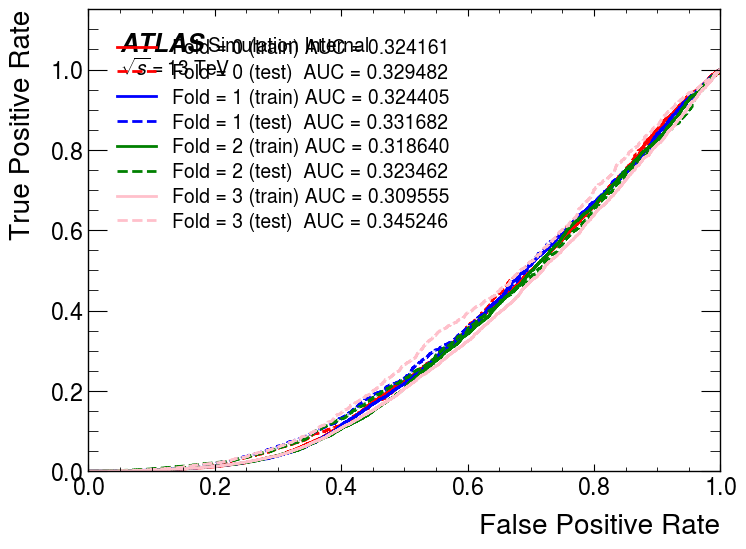

In [64]:
# AUC curve: Adapted for 3-class


nfolds = 4

colors = ['red','blue','green','pink'] 
for fold in range(nfolds):
    X_sig_train = df_sig_85[feature_cols][df_sig_85['eventNumber']%nfolds != fold]
    X_sig_test = df_sig_85[feature_cols][df_sig_85['eventNumber']%nfolds == fold]
    X_bkg_train_prompts = df_bkg_prompt_85_reweighted[feature_cols][df_bkg_prompt_85_reweighted['eventNumber']%nfolds != fold]
    X_bkg_test_prompts = df_bkg_prompt_85_reweighted[feature_cols][df_bkg_prompt_85_reweighted['eventNumber']%nfolds == fold]
    X_bkg_train_fakes = df_bkg_fakes_85_reweighted[feature_cols][df_bkg_fakes_85_reweighted['eventNumber']%nfolds != fold]
    X_bkg_test_fakes = df_bkg_fakes_85_reweighted[feature_cols][df_bkg_fakes_85_reweighted['eventNumber']%nfolds == fold]
    
    #X_bkg_train = df_bkg[feature_cols][df_bkg['eventNumber']%nfolds != fold]
    #X_bkg_test = df_bkg[feature_cols][df_bkg['eventNumber']%nfolds == fold]
    results_sig_fold_train = models[fold].predict_proba(X_sig_train)[:,1]
    results_bkg_prompts_fold_train = models[fold].predict_proba(X_bkg_train_prompts)[:,1]
    results_bkg_fakes_fold_train = models[fold].predict_proba(X_bkg_train_fakes)[:,1]

    results_sig_fold_test = models[fold].predict_proba(X_sig_test)[:,1]
    results_bkg_prompts_fold_test = models[fold].predict_proba(X_bkg_test_prompts)[:,1]
    results_bkg_fakes_fold_test = models[fold].predict_proba(X_bkg_test_fakes)[:,1]

    y = np.concatenate([np.ones_like(results_sig_fold_train),np.zeros_like(results_bkg_prompts_fold_train),2 * np.zeros_like(results_bkg_fakes_fold_train)])

    #y = np.concatenate([np.ones_like(results_sig_fold_train), np.zeros_like(results_bkg_fold_train)])
    scores = np.concatenate([results_sig_fold_train, results_bkg_prompts_fold_train, results_bkg_fakes_fold_train])
    fpr, tpr, thresholds = metrics.roc_curve(y, scores, pos_label=1)
    AUC = metrics.roc_auc_score(y, scores)
    plt.plot(fpr,tpr,label=F'Fold = {fold} (train) AUC = {AUC:.6f}', color=colors[fold])
    
    y = np.concatenate([np.ones_like(results_sig_fold_test),np.zeros_like(results_bkg_prompts_fold_test),2 * np.zeros_like(results_bkg_fakes_fold_test)])
    #y = np.concatenate([np.ones_like(results_sig_fold_test), np.zeros_like(results_bkg_fold_test)])
    scores = np.concatenate([results_sig_fold_test, results_bkg_prompts_fold_test, results_bkg_fakes_fold_test])
    fpr, tpr, thresholds = metrics.roc_curve(y, scores, pos_label=1)
    AUC = metrics.roc_auc_score(y, scores)
    plt.plot(fpr,tpr,label=F'Fold = {fold} (test)  AUC = {AUC:.6f}', color=colors[fold], linestyle='--')

plt.legend()
plt.xlim(0,1)
plt.ylim(0,1.15)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
mplhep.atlas.label('Internal', data=False)
#plt.savefig('auc.png')

(exptext: Custom Text(0.05, 0.95, 'ATLAS'),
 expsuffix: Custom Text(0.05, 0.955, 'Simulation Internal'),
 expsuffix: Custom Text(0.05, 0.95, '$\\sqrt{s} = \\mathrm{13\\ TeV}$'))

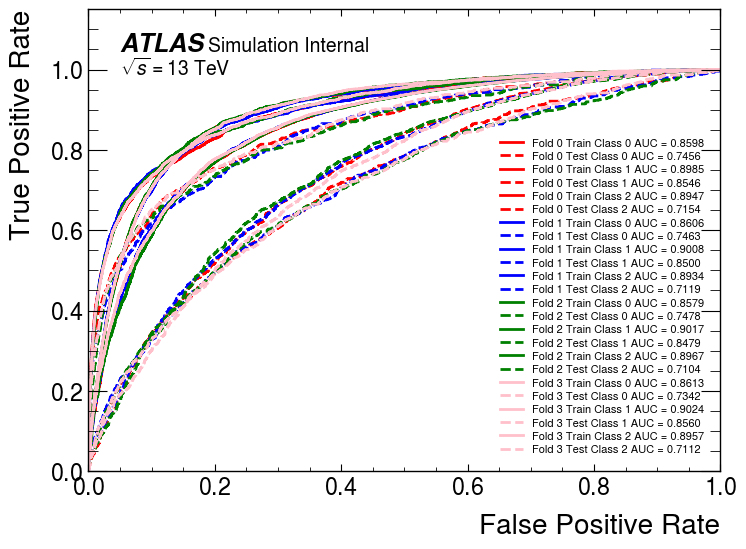

In [67]:
nfolds = 4

colors = ['red','blue','green','pink'] 

for fold in range(nfolds):
    for c in range(3):  # Iterate through the classes (0, 1, 2)
        X_sig_train = df_sig_85[feature_cols][df_sig_85['eventNumber'] % nfolds != fold]
        X_sig_test = df_sig_85[feature_cols][df_sig_85['eventNumber'] % nfolds == fold]
        X_bkg_train_prompts = df_bkg_prompt_85_reweighted[feature_cols][df_bkg_prompt_85_reweighted['eventNumber'] % nfolds != fold]
        X_bkg_test_prompts = df_bkg_prompt_85_reweighted[feature_cols][df_bkg_prompt_85_reweighted['eventNumber'] % nfolds == fold]
        X_bkg_train_fakes = df_bkg_fakes_85_reweighted[feature_cols][df_bkg_fakes_85_reweighted['eventNumber'] % nfolds != fold]
        X_bkg_test_fakes = df_bkg_fakes_85_reweighted[feature_cols][df_bkg_fakes_85_reweighted['eventNumber'] % nfolds == fold]

        y_train = np.concatenate([np.zeros_like(X_sig_train.iloc[:, 0]), np.ones_like(X_bkg_train_prompts.iloc[:, 0]),
                                  2 * np.ones_like(X_bkg_train_fakes.iloc[:, 0])])  # putting classes 0, 1, 2
        X_train = np.concatenate([X_sig_train, X_bkg_train_prompts, X_bkg_train_fakes])
        y_test = np.concatenate([np.zeros_like(X_sig_test.iloc[:, 0]), np.ones_like(X_bkg_test_prompts.iloc[:, 0]),
                                 2 * np.ones_like(X_bkg_test_fakes.iloc[:, 0])])
        X_test = np.concatenate([X_sig_test, X_bkg_test_prompts, X_bkg_test_fakes])

        y_train_c = (y_train == c).astype(int)  # 1 if class c, 0 otherwise (train)
        y_test_c = (y_test == c).astype(int)  # 1 if class c, 0 otherwise (test)

        scores_train_c = models[fold].predict_proba(X_train)[:, c]  # Probability of class c (train)
        scores_test_c = models[fold].predict_proba(X_test)[:, c]  # Probability of class c (test)

        fpr_train, tpr_train, _ = metrics.roc_curve(y_train_c, scores_train_c)
        auc_train = metrics.roc_auc_score(y_train_c, scores_train_c)
        plt.plot(fpr_train, tpr_train, label=f'Fold {fold} Train Class {c} AUC = {auc_train:.4f}', color=colors[fold])

        fpr_test, tpr_test, _ = metrics.roc_curve(y_test_c, scores_test_c)
        auc_test = metrics.roc_auc_score(y_test_c, scores_test_c)
        plt.plot(fpr_test, tpr_test, label=f'Fold {fold} Test Class {c} AUC = {auc_test:.4f}', color=colors[fold],
                 linestyle='--')

plt.legend(fontsize=8)
plt.xlim(0,1)
plt.ylim(0,1.15)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
mplhep.atlas.label('Internal', data=False)
#plt.savefig('auc.png')

In [30]:
custom_bins = [0,1,2,3,4,5,6,7,8,9,10]
custom_bins

[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10]

[0.42  0.203 0.377]


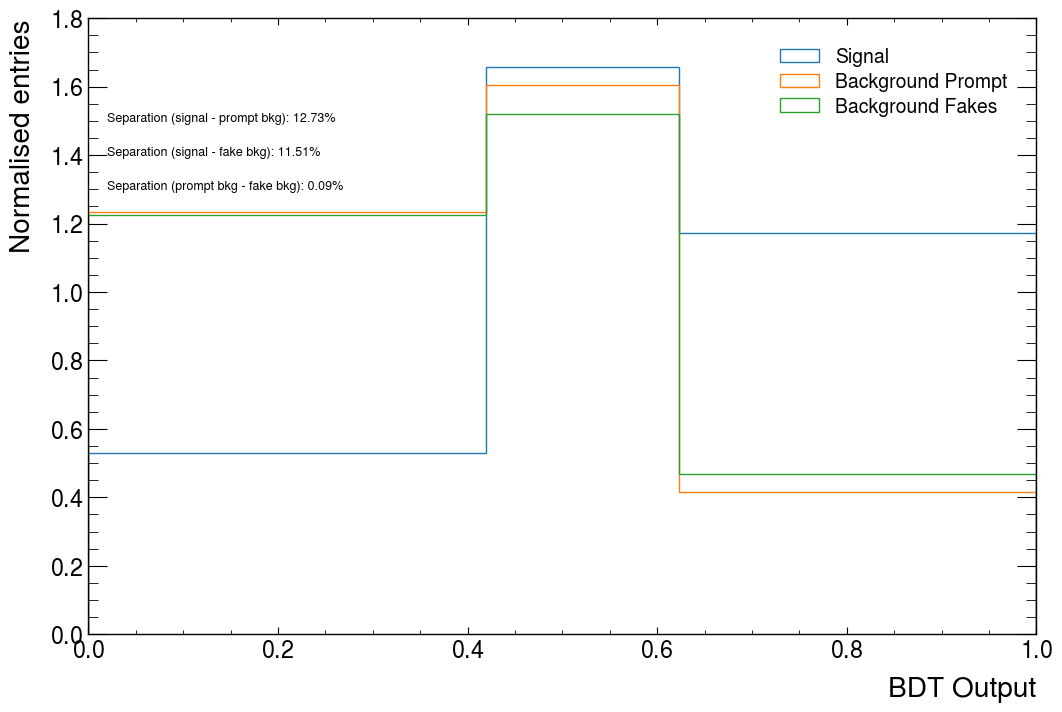

In [31]:
plt.figure(figsize=(12, 8))

# Define custom bin edges
custom_bins = [0., 0.42, 0.623, 1.] #[0, 0.4, 0.6, 1]

# Histogram plotting
bc_sig, bin_edges, _ = plt.hist(results_sig, weights=df_sig_85['weight'], bins=custom_bins, histtype='step', density=True, label='Signal')
bc_bkg_prompt, _, _ = plt.hist(results_bkg_prompts, weights=df_bkg_prompt_85_reweighted['weight'], bins=custom_bins, histtype='step', density=True, label='Background Prompt')
bc_bkg_fake, _, _ = plt.hist(results_bkg_fakes, weights=df_bkg_fakes_85_reweighted['weight'], bins=custom_bins, histtype='step', density=True, label='Background Fakes')


# Calculate bin widths and separation
bin_widths = np.diff(bin_edges)
print(bin_widths)
separation_sig_bkgPrompt = 0.5 * np.sum(np.nan_to_num(((bc_sig - bc_bkg_prompt) ** 2) / (bc_sig + bc_bkg_prompt)) * bin_widths)
separation_sig_bkgFake = 0.5 * np.sum(np.nan_to_num(((bc_sig - bc_bkg_fake) ** 2) / (bc_sig + bc_bkg_fake)) * bin_widths)
separation_bkgPrompt_bkgFake = 0.5 * np.sum(np.nan_to_num(((bc_bkg_prompt - bc_bkg_fake) ** 2) / (bc_bkg_prompt + bc_bkg_fake)) * bin_widths)

#separation = 0.5 * np.sum(np.nan_to_num(((bc_sig - bc_bkg) ** 2) / (bc_sig + bc_bkg)) * bin_widths)

# Plotting details
plt.legend(loc='upper right')
plt.xlabel('BDT Output')
plt.ylabel('Normalised entries')
plt.text(x=0.02, y=1.50, s=f'Separation (signal - prompt bkg): {separation_sig_bkgPrompt*100:.2f}%', fontsize = 9)
plt.text(x=0.02, y=1.40, s=f'Separation (signal - fake bkg): {separation_sig_bkgFake*100:.2f}%', fontsize = 9)
plt.text(x=0.02, y=1.30, s=f'Separation (prompt bkg - fake bkg): {separation_bkgPrompt_bkgFake*100:.2f}%', fontsize = 9)

#plt.savefig(f'separation_fittedbins_3class.pdf')
plt.legend()


In [32]:
results_bkg = np.concatenate([results_bkg_prompts,results_bkg_fakes])
df_bkg      = np.concatenate([df_bkg_prompt_85_reweighted,df_bkg_fakes_85_reweighted])

df_bkg_weight = np.concatenate([df_bkg_prompt_85_reweighted['weight'],df_bkg_fakes_85_reweighted['weight']])

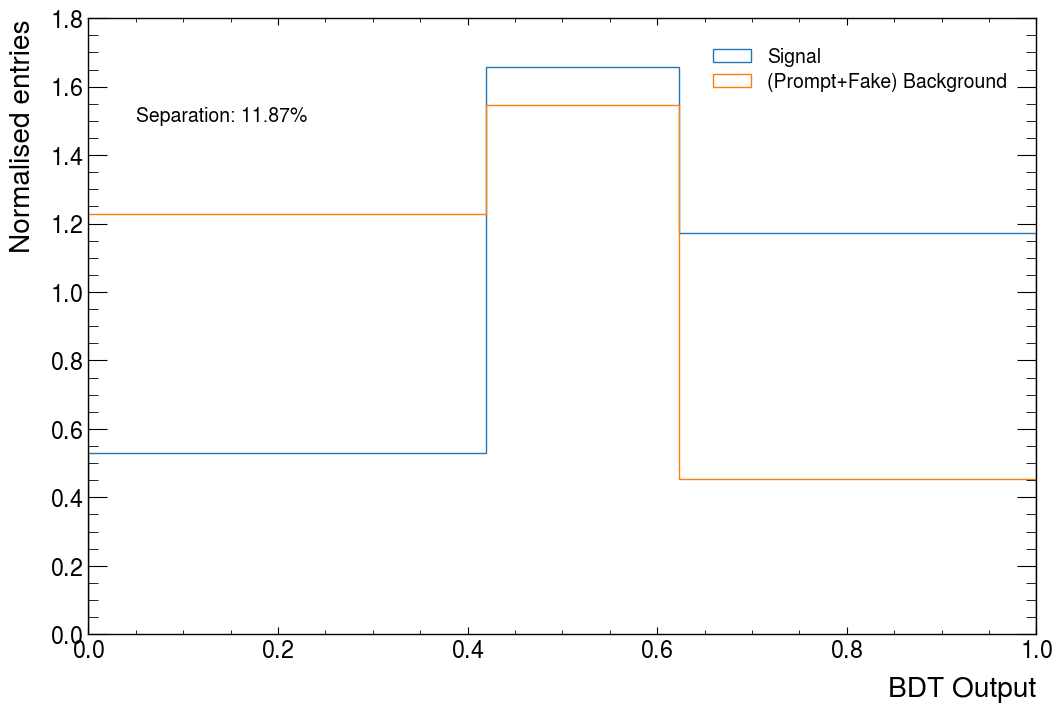

In [33]:
plt.figure(figsize=(12, 8))


# Define custom bin edges
custom_bins = [0., 0.42, 0.623, 1.] #[0, 0.4, 0.6, 1]

# Histogram plotting
bc_sig, bin_edges, _ = plt.hist(results_sig, weights=df_sig_85['weight'], bins=custom_bins, histtype='step', density=True, label='Signal')
bc_bkg, _, _ = plt.hist(results_bkg, weights=df_bkg_weight, bins=custom_bins, histtype='step', density=True, label='(Prompt+Fake) Background')

# Calculate bin widths and separation
bin_widths = np.diff(bin_edges)
separation = 0.5 * np.sum(np.nan_to_num(((bc_sig - bc_bkg) ** 2) / (bc_sig + bc_bkg)) * bin_widths)

# Plotting details
plt.legend(loc='upper right')
plt.xlabel('BDT Output')
plt.ylabel('Normalised entries')
plt.text(x=0.05, y=1.5, s=f'Separation: {separation*100:.2f}%')
#plt.savefig(f'separation_fittedbins_3class_converged.pdf')
plt.legend()


(exptext: Custom Text(0.05, 0.95, 'ATLAS'),
 expsuffix: Custom Text(0.05, 0.955, 'Simulation Internal'),
 expsuffix: Custom Text(0.05, 0.95, '$\\sqrt{s} = \\mathrm{13\\ TeV}$'))

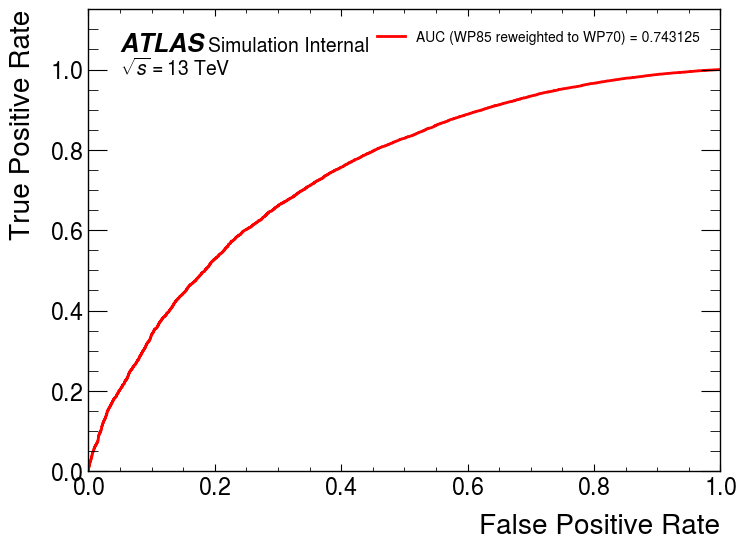

In [40]:
# Aggregate AUC 

scores_85_reweighted_3class = np.concatenate([results_sig, results_bkg])
y_85_reweighted_3class = np.concatenate([np.ones_like(results_sig), np.zeros_like(results_bkg)])

fpr_85_reweighted_3class, tpr_85_reweighted_3class, thresholds_85_reweighted_3class = metrics.roc_curve(y_85_reweighted_3class, scores_85_reweighted_3class, pos_label=1)
AUC_85_reweighted_3class = metrics.roc_auc_score(y_85_reweighted_3class, scores_85_reweighted_3class)

plt.plot(fpr_85_reweighted_3class,tpr_85_reweighted_3class,label=F'AUC (WP85 reweighted to WP70) = {AUC_85_reweighted_3class:.6f}', color='red')
plt.legend(loc = 'upper right', fontsize=10)
plt.xlim(0,1)
plt.ylim(0,1.15)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
mplhep.atlas.label('Internal', data=False)

# Save the data to a file
#np.savez('roc_data_85_reweighted_perprocess_3class.npz', fpr=fpr_85_reweighted_3class, tpr=tpr_85_reweighted_3class, thresholds=thresholds_85_reweighted_3class, auc=AUC_85_reweighted_3class)
#print("Data saved to 'roc_data_85_reweighted_perprocess_3class.npz'")

In [34]:
# Define the custom formatter function
def custom_formatter(x, pos):
    return f'{x * 0.1:.1f}'

# KS test - 3 classes separated

[0.    0.42  0.623 1.   ]
-----------------------------------------------
0.5313675339543386 1.6825903112907572
0.5203812436384033 1.5790731247104637
4 3 3 3
Signal train histogram: [0.53136753 1.68259031 1.15453525]
Signal test histogram: [0.52038124 1.57907312 1.22251468]
Background 1 train histogram: [1.25098994 1.63899542 0.37630811]
Background 1 test histogram: [1.18002717 1.50833423 0.5257208 ]
Background 2 train histogram: [1.20542389 1.57541864 0.46130499]
Background 2 test histogram: [1.27915576 1.36234168 0.49389714]
-----------------------------------------------

Signal train errors: [0.03255976 0.0401402  0.04516903]
Signal test errors: [0.01866606 0.02249146 0.02687277]
Background 1 train errors: [0.46450314 0.2588964  0.13946703]
Background 1 test errors: [0.19060962 0.14434974 0.13838154]
Background 2 train errors: [0.54294676 0.38389832 0.25455192]
Background 2 test errors: [0.3100433  0.22069262 0.18478365]
-----------------------------------------------

Sig ratio:  

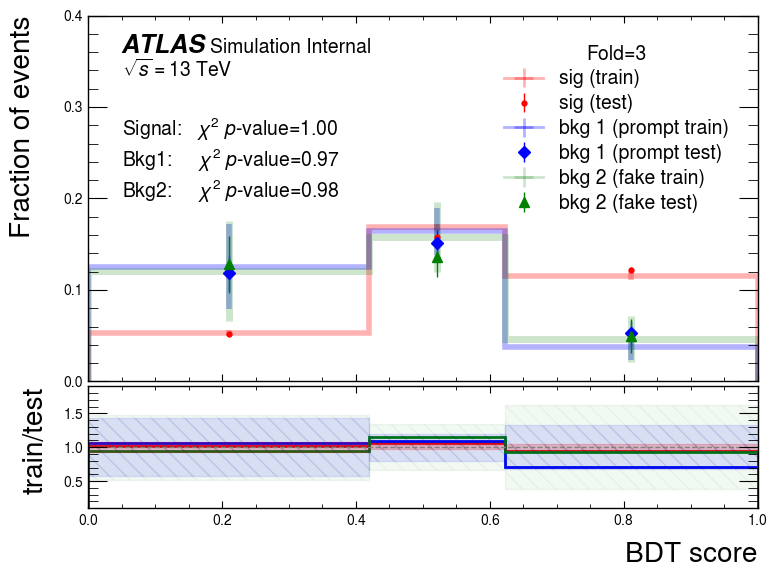

In [39]:
## !!!! KS test with fitted bins 


# Working code - Per fold. Change no. of folds
# Unweighted  - with corrected Sumw2()
# Normalized with auc
folds = 4
fold = 3
fig, axes = plt.subplots(nrows=2,ncols=1,gridspec_kw={'height_ratios': [3, 1]}, sharex=True)
custom_bins = [0, 0.420, 0.623, 1]


# Example dummy data and plots:
results_sig_fold_test = results_sig[df_sig_85['eventNumber']%folds == fold]
results_bkg1_fold_test = results_bkg_prompts[df_bkg_prompt_85_reweighted['eventNumber']%folds == fold]
results_bkg2_fold_test = results_bkg_fakes[df_bkg_fakes_85_reweighted['eventNumber']%folds == fold]

weights_sig_fold_test = df_sig_85['weight'][df_sig_85['eventNumber']%folds == fold]
weights_bkg1_fold_test = df_bkg_prompt_85_reweighted['weight'][df_bkg_prompt_85_reweighted['eventNumber']%folds == fold]
weights_bkg2_fold_test = df_bkg_fakes_85_reweighted['weight'][df_bkg_fakes_85_reweighted['eventNumber']%folds == fold]

y = np.concatenate([np.ones_like(results_sig_fold_test), np.zeros_like(results_bkg1_fold_test), np.zeros_like(results_bkg2_fold_test)])
scores = np.concatenate([results_sig_fold_test, results_bkg1_fold_test, results_bkg2_fold_test])
weights = np.concatenate([weights_sig_fold_test,weights_bkg1_fold_test, weights_bkg2_fold_test])




results_sig_fold_train = results_sig[df_sig_85['eventNumber']%folds != fold]
results_bkg1_fold_train = results_bkg_prompts[df_bkg_prompt_85_reweighted['eventNumber']%folds != fold]
results_bkg2_fold_train = results_bkg_fakes[df_bkg_fakes_85_reweighted['eventNumber']%folds != fold]

weights_sig_fold_train = df_sig_85['weight'][df_sig_85['eventNumber']%folds != fold]
weights_bkg1_fold_train = df_bkg_prompt_85_reweighted['weight'][df_bkg_prompt_85_reweighted['eventNumber']%folds != fold]
weights_bkg2_fold_train = df_bkg_fakes_85_reweighted['weight'][df_bkg_fakes_85_reweighted['eventNumber']%folds != fold]

y = np.concatenate([np.ones_like(results_sig_fold_train), np.zeros_like(results_bkg1_fold_train), np.zeros_like(results_bkg2_fold_train)])
scores = np.concatenate([results_sig_fold_train, results_bkg1_fold_train, results_bkg2_fold_train])
weights = np.concatenate([weights_sig_fold_train, weights_bkg1_fold_train, weights_bkg2_fold_train])

"""
bc, bb = np.histogram(data1, weights=weights1, range=(-3,3), bins=10)
sumW2, bb = np.histogram(data1, weights=weights1**2, range=(-3,3), bins=10)
mplhep.histplot(bc,bb,yerr=np.sqrt(sumW2),density=True,label='10000 events, weight=0.1', histtype='errorbar')
"""
#bc_sig_train, bb = np.histogram(results_sig_fold_train, weights=weights_sig_fold_train, bins=np.linspace(0,1,11), density=True)


bc_sig_train, bb = np.histogram(results_sig_fold_train, weights=weights_sig_fold_train, range=(0,1), bins=custom_bins, density=True)
total_sig_train = len(results_sig_fold_train) #np.sum(bc_sig_train)
sumW2, bb = np.histogram(results_sig_fold_train, weights=weights_sig_fold_train**2, range=(0,1), bins=custom_bins)
mplhep.histplot(bc_sig_train,bb,yerr=np.sqrt(sumW2), density=True, label='sig (train)', histtype='step', ax=axes[0], color='red', alpha=0.3, linewidth=4)
bc_sig_train_e = np.sqrt(sumW2)

bc_sig_test, bb = np.histogram(results_sig_fold_test,  weights=weights_sig_fold_test, range=(0,1), bins=custom_bins, density=True)
total_sig_test = len(results_sig_fold_test) #np.sum(bc_sig_test)
sumW2, bb = np.histogram(results_sig_fold_test, weights=weights_sig_fold_test**2, range=(0,1), bins=custom_bins)
mplhep.histplot(bc_sig_test,bb,yerr=np.sqrt(sumW2),density=True, label='sig (test)', histtype='errorbar', ax=axes[0], color='red', markersize=7)
bc_sig_test_e = np.sqrt(sumW2)

bc_bkg1_train, bb = np.histogram(results_bkg1_fold_train, weights=weights_bkg1_fold_train, range=(0,1), bins=custom_bins, density=True)
total_bkg1_train = len(results_bkg1_fold_train) #np.sum(bc_sig_train)
sumW2, bb = np.histogram(results_bkg1_fold_train, weights=weights_bkg1_fold_train**2, range=(0,1), bins=custom_bins)
mplhep.histplot(bc_bkg1_train,bb,yerr=np.sqrt(sumW2), density=True, label='bkg 1 (prompt train)', histtype='step', ax=axes[0], color='blue', alpha=0.3, linewidth=4)
bc_bkg1_train_e = np.sqrt(sumW2)


bc_bkg1_test, bb = np.histogram(results_bkg1_fold_test,  weights=weights_bkg1_fold_test, range=(0,1), bins=custom_bins, density=True)
total_bkg1_test = len(results_bkg1_fold_test) #np.sum(bc_sig_test)
sumW2, bb = np.histogram(results_bkg1_fold_test, weights=weights_bkg1_fold_test**2, range=(0,1), bins=custom_bins)
mplhep.histplot(bc_bkg1_test,bb,yerr=np.sqrt(sumW2), density=True, label='bkg 1 (prompt test)', histtype='errorbar', ax=axes[0], color='blue', markersize=6, marker='D')
bc_bkg1_test_e = np.sqrt(sumW2)



bc_bkg2_train, bb = np.histogram(results_bkg2_fold_train, weights=weights_bkg2_fold_train, range=(0,1), bins=custom_bins, density=True)
total_bkg2_train = len(results_bkg2_fold_train) #np.sum(bc_sig_train)
sumW2, bb = np.histogram(results_bkg2_fold_train, weights=weights_bkg2_fold_train**2, range=(0,1), bins=custom_bins)
mplhep.histplot(bc_bkg2_train,bb,yerr=np.sqrt(sumW2), density=True, label='bkg 2 (fake train)', histtype='step', ax=axes[0], color='green', alpha=0.2, linewidth=5)
bc_bkg2_train_e = np.sqrt(sumW2)


bc_bkg2_test, bb = np.histogram(results_bkg2_fold_test,  weights=weights_bkg2_fold_test, range=(0,1), bins=custom_bins, density=True)
total_bkg2_test = len(results_bkg2_fold_test) #np.sum(bc_sig_test)
sumW2, bb = np.histogram(results_bkg2_fold_test, weights=weights_bkg2_fold_test**2, range=(0,1), bins=custom_bins)
mplhep.histplot(bc_bkg2_test,bb,yerr=np.sqrt(sumW2), density=True, label='bkg 2 (fake test)', histtype='errorbar', ax=axes[0], color='green', markersize=7, marker='^')
bc_bkg2_test_e = np.sqrt(sumW2)




print(bb)


print("-----------------------------------------------")
# Example check if data is within expected range
print(bc_sig_train.min(), bc_sig_train.max())
print(bc_sig_test.min(), bc_sig_test.max())

print(len(bb), len(bc_sig_train), len(bc_bkg1_train), len(bc_bkg2_train))
bc_bkg1_test = np.where(bc_bkg1_test == 0, 1e-1, bc_bkg1_test)


corr_factor_sig = np.sum(bc_sig_train)/np.sum(bc_sig_test)
chi2_sig, p_sig = chisquare(bc_sig_train, bc_sig_test*corr_factor_sig)
corr_factor_bkg1 = np.sum(bc_bkg1_train)/np.sum(bc_bkg1_test)
chi2_bkg1, p_bkg1 = chisquare(bc_bkg1_train, bc_bkg1_test*corr_factor_bkg1)
corr_factor_bkg2 = np.sum(bc_bkg2_train)/np.sum(bc_bkg2_test)
chi2_bkg2, p_bkg2 = chisquare(bc_bkg2_train, bc_bkg2_test*corr_factor_bkg2)


axes[0].set_xlim(0,1)
axes[0].set_ylim(0,4)

#scale_and_format_y_axis(axes[0], scale_factor=0.1)  # Adjust scale_factor as needed

# Create the FuncFormatter object
formatter = mtick.FuncFormatter(custom_formatter)

# Apply the custom formatter to the y-axis
axes[0].yaxis.set_major_formatter(formatter)
axes[0].yaxis.set_major_locator(mtick.MultipleLocator(1))   # removing this will lead to duplicate labels


axes[0].legend(title=F'Fold={fold}', loc='upper right')

#ax.set_xlabel('BDT score')
axes[0].set_ylabel('Fraction of events', labelpad=20)
mplhep.atlas.label('Internal', data=False, ax=axes[0])
axes[0].text(x=0.05, y=2.0,s=F'Signal:   $\chi^2$ $p$-value={p_sig:.2f}\nBkg1:     $\chi^2$ $p$-value={p_bkg1:.2f}\nBkg2:     $\chi^2$ $p$-value={p_bkg2:.2f}')
axes[0].tick_params(axis='both', labelsize=10)

print("Signal train histogram:", bc_sig_train)
print("Signal test histogram:", bc_sig_test)
print("Background 1 train histogram:", bc_bkg1_train)
print("Background 1 test histogram:", bc_bkg1_test)
print("Background 2 train histogram:", bc_bkg2_train)
print("Background 2 test histogram:", bc_bkg2_test)

print("-----------------------------------------------")




print("\nSignal train errors:", bc_sig_train_e)
print("Signal test errors:", bc_sig_test_e)
print("Background 1 train errors:", bc_bkg1_train_e)
print("Background 1 test errors:", bc_bkg1_test_e)
print("Background 2 train errors:", bc_bkg2_train_e)
print("Background 2 test errors:", bc_bkg2_test_e)

print("-----------------------------------------------")

ratio_sig = np.where(bc_sig_test == 0, 1, bc_sig_train / bc_sig_test)
ratio_bkg1 = np.where(bc_bkg1_test == 0, 1, bc_bkg1_train / bc_bkg1_test)
ratio_bkg2 = np.where(bc_bkg2_test == 0, 1, bc_bkg2_train / bc_bkg2_test)

print("\nSig ratio: ", ratio_sig)
print("Bkg 1 ratio: ", ratio_bkg1)
print("Bkg 2 ratio: ", ratio_bkg2)

ratio_sig_e = np.sqrt((bc_sig_train/(1.0*bc_sig_test*bc_sig_test))*(bc_sig_train/(1.0*bc_sig_test*bc_sig_test))*bc_sig_test_e*bc_sig_test_e+(1/(1.0*bc_sig_test))*(1/(1.0*bc_sig_test))*bc_sig_train_e*bc_sig_train_e)
ratio_bkg1_e = np.sqrt((bc_bkg1_train/(1.0*bc_bkg1_test*bc_bkg1_test))*(bc_bkg1_train/(1.0*bc_bkg1_test*bc_bkg1_test))*bc_bkg1_test_e*bc_bkg1_test_e+(1/(1.0*bc_bkg1_test))*(1/(1.0*bc_bkg1_test))*bc_bkg1_train_e*bc_bkg1_train_e)
ratio_bkg2_e = np.sqrt((bc_bkg2_train/(1.0*bc_bkg2_test*bc_bkg2_test))*(bc_bkg2_train/(1.0*bc_bkg2_test*bc_bkg2_test))*bc_bkg2_test_e*bc_bkg2_test_e+(1/(1.0*bc_bkg2_test))*(1/(1.0*bc_bkg2_test))*bc_bkg2_train_e*bc_bkg2_train_e)


print("\nSig Ratio uncertainties per bin: ", ratio_sig_e)



# Clip errors and add padding
max_error = 100  # Example maximum error threshold
clipped_errors_sig = np.clip(ratio_sig_e, 0, max_error)
clipped_errors_bkg1 = np.clip(ratio_bkg1_e, 0, max_error)
clipped_errors_bkg2 = np.clip(ratio_bkg2_e, 0, max_error)


print("Clipped errors:", clipped_errors_sig)
print("Clipped errors:", clipped_errors_bkg1)
print("Clipped errors:", clipped_errors_bkg2)

custom_bins = np.array([0, 0.420, 0.623, 1])


#bb_centers = (bb[:-1] + bb[1:]) / 2
bb_centers = (custom_bins[:-1] + custom_bins[1:]) / 2

mplhep.histplot(ratio_sig, custom_bins, histtype='step', ax=axes[1], color='red', linewidth=2)
mplhep.histplot(ratio_bkg1, custom_bins, histtype='step', ax=axes[1], color='blue', linewidth=2)
mplhep.histplot(ratio_bkg2, custom_bins, histtype='step', ax=axes[1], color='green', linewidth=2)


#bin_width = bb[1] - bb[0] 
#bin_width = custom_bins[1] - custom_bins[0]  # Update bin width based on custom bins
bin_widths = np.diff(custom_bins)  # Using np.diff to calculate the distance between bin edges
print(bin_widths)

    
# Plot the uncertainty band using custom bin centers and the clipped errors
for center, err, width in zip(bb_centers, clipped_errors_sig, bin_widths):
    axes[1].bar(center, 2 * err, width=width, bottom=1 - err, color='red', alpha=0.2, edgecolor='red', hatch='\\\\', align='center')

for center, err, width in zip(bb_centers, clipped_errors_bkg1, bin_widths):
    axes[1].bar(center, 2 * err, width=width, bottom=1 - err, color='blue', alpha=0.1, edgecolor='blue', hatch='\\\\', align='center')

for center, err, width in zip(bb_centers, clipped_errors_bkg2, bin_widths):
    axes[1].bar(center, 2 * err, width=width, bottom=1 - err, color='green', alpha=0.05, edgecolor='green', hatch='\\\\', align='center')


#axes[1].set_dashes((5,2))

axes[1].axhline(1,0,1,linestyle='--',color='grey', linewidth=1)
axes[1].set_ylabel('train/test')
axes[1].set_xlabel('BDT score')
axes[1].tick_params(axis='both', labelsize=10)

axes[1].set_ylim(0.1,1.9)  # Adjust based on your ratio values
fig.tight_layout()
fig.subplots_adjust(hspace=0.02)
fig.savefig(f'Test_Train_Chi_Squared_Unweighted_{fold}_Model8_3Class_fittedbins_splitbackground.png')

# KS test - Bkg classes combined

[0.    0.42  0.623 1.   ]
-----------------------------------------------
0.5303835381742171 1.6422745793297435
0.523303409030995 1.6997449646294043
4 3 3
Signal train histogram: [0.53038354 1.64227458 1.17734002]
Signal test histogram: [0.52330341 1.69974496 1.15428207]
Background train histogram: [1.48161904 1.22105077 0.34442094]
Background test histogram: [1.48890784 1.22982912 0.33157399]
-----------------------------------------------

Signal train errors: [0.03254836 0.03968342 0.04562188]
Signal test errors: [0.01868595 0.02328791 0.02609676]
Background train errors: [1.2402264  0.7089907  0.46678334]
Background test errors: [0.93608147 0.35351133 0.29389158]
-----------------------------------------------

Sig ratio:  [1.01352968 0.96618882 1.01997601]
Bkg ratio:  [0.9951046  0.99286214 1.03874535]

Sig Ratio uncertainties per bin:  [0.07196074 0.02683844 0.04575943]
Clipped errors: [0.07196074 0.02683844 0.04575943]
Clipped errors: [1.04175747 0.64327098 1.68211911]
[0.42  0.

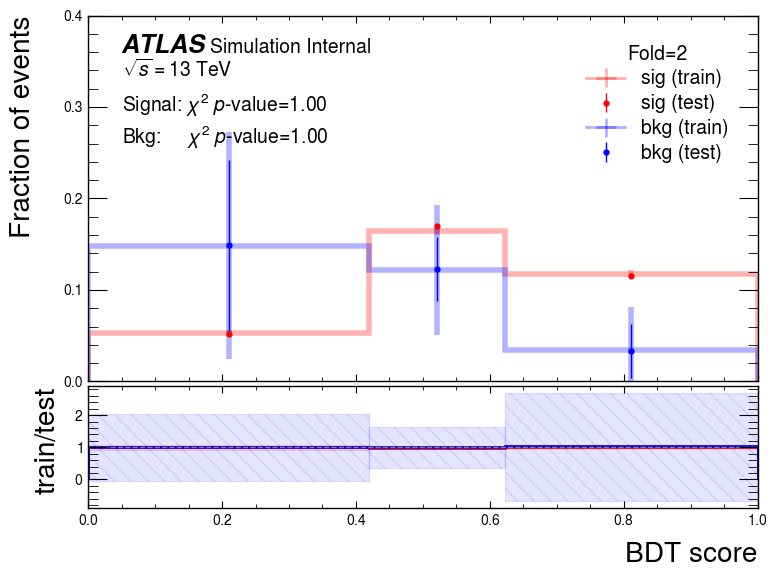

In [44]:
## !!!! KS test with fitted bins

# Working code - Per fold. Change no. of folds
# Unweighted  - with corrected Sumw2()
# Normalized with auc
folds = 4
fold = 2
fig, axes = plt.subplots(nrows=2,ncols=1,gridspec_kw={'height_ratios': [3, 1]}, sharex=True)
custom_bins = [0, 0.420, 0.623, 1]


# Example dummy data and plots:
results_sig_fold_test = results_sig[df_sig_85['eventNumber']%folds == fold]
results_bkg_fold_test = results_bkg[df_bkg_85['eventNumber']%folds == fold]
weights_sig_fold_test = df_sig_85['weight'][df_sig_85['eventNumber']%folds == fold]
weights_bkg_fold_test = df_bkg_85['weight'][df_bkg_85['eventNumber']%folds == fold]
y = np.concatenate([np.ones_like(results_sig_fold_test), np.zeros_like(results_bkg_fold_test)])
scores = np.concatenate([results_sig_fold_test, results_bkg_fold_test])
weights = np.concatenate([weights_sig_fold_test,weights_bkg_fold_test])

results_sig_fold_train = results_sig[df_sig_85['eventNumber']%folds != fold]
results_bkg_fold_train = results_bkg[df_bkg_85['eventNumber']%folds != fold]
weights_sig_fold_train = df_sig_85['weight'][df_sig_85['eventNumber']%folds != fold]
weights_bkg_fold_train = df_bkg_85['weight'][df_bkg_85['eventNumber']%folds != fold]
y = np.concatenate([np.ones_like(results_sig_fold_train), np.zeros_like(results_bkg_fold_train)])
scores = np.concatenate([results_sig_fold_train, results_bkg_fold_train])
weights = np.concatenate([weights_sig_fold_train,weights_bkg_fold_train])

"""
bc, bb = np.histogram(data1, weights=weights1, range=(-3,3), bins=10)
sumW2, bb = np.histogram(data1, weights=weights1**2, range=(-3,3), bins=10)
mplhep.histplot(bc,bb,yerr=np.sqrt(sumW2),density=True,label='10000 events, weight=0.1', histtype='errorbar')
"""
#bc_sig_train, bb = np.histogram(results_sig_fold_train, weights=weights_sig_fold_train, bins=np.linspace(0,1,11), density=True)


bc_sig_train, bb = np.histogram(results_sig_fold_train, weights=weights_sig_fold_train, range=(0,1), bins=custom_bins, density=True)
total_sig_train = len(results_sig_fold_train) #np.sum(bc_sig_train)
sumW2, bb = np.histogram(results_sig_fold_train, weights=weights_sig_fold_train**2, range=(0,1), bins=custom_bins)
mplhep.histplot(bc_sig_train,bb,yerr=np.sqrt(sumW2), density=True, label='sig (train)', histtype='step', ax=axes[0], color='red', alpha=0.3, linewidth=4)
bc_sig_train_e = np.sqrt(sumW2)

bc_sig_test, bb = np.histogram(results_sig_fold_test,  weights=weights_sig_fold_test, range=(0,1), bins=custom_bins, density=True)
total_sig_test = len(results_sig_fold_test) #np.sum(bc_sig_test)
sumW2, bb = np.histogram(results_sig_fold_test, weights=weights_sig_fold_test**2, range=(0,1), bins=custom_bins)
mplhep.histplot(bc_sig_test,bb,yerr=np.sqrt(sumW2),density=True, label='sig (test)', histtype='errorbar', ax=axes[0], color='red', markersize=7)
bc_sig_test_e = np.sqrt(sumW2)

bc_bkg_train, bb = np.histogram(results_bkg_fold_train, weights=weights_bkg_fold_train, range=(0,1), bins=custom_bins, density=True)
total_bkg_train = len(results_bkg_fold_train) #np.sum(bc_sig_train)
sumW2, bb = np.histogram(results_bkg_fold_train, weights=weights_bkg_fold_train**2, range=(0,1), bins=custom_bins)
mplhep.histplot(bc_bkg_train,bb,yerr=np.sqrt(sumW2), density=True, label='bkg (train)', histtype='step', ax=axes[0], color='blue', alpha=0.3, linewidth=4)
bc_bkg_train_e = np.sqrt(sumW2)


bc_bkg_test, bb = np.histogram(results_bkg_fold_test,  weights=weights_bkg_fold_test, range=(0,1), bins=custom_bins, density=True)
total_bkg_test = len(results_bkg_fold_test) #np.sum(bc_sig_test)
sumW2, bb = np.histogram(results_bkg_fold_test, weights=weights_bkg_fold_test**2, range=(0,1), bins=custom_bins)
mplhep.histplot(bc_bkg_test,bb,yerr=np.sqrt(sumW2), density=True, label='bkg (test)', histtype='errorbar', ax=axes[0], color='blue', markersize=7)
bc_bkg_test_e = np.sqrt(sumW2)

print(bb)


print("-----------------------------------------------")
# Example check if data is within expected range
print(bc_sig_train.min(), bc_sig_train.max())
print(bc_sig_test.min(), bc_sig_test.max())

print(len(bb), len(bc_sig_train), len(bc_bkg_train))
bc_bkg_test = np.where(bc_bkg_test == 0, 1e-1, bc_bkg_test)


corr_factor_sig = np.sum(bc_sig_train)/np.sum(bc_sig_test)
chi2_sig, p_sig = chisquare(bc_sig_train, bc_sig_test*corr_factor_sig)
corr_factor_bkg = np.sum(bc_bkg_train)/np.sum(bc_bkg_test)
chi2_bkg, p_bkg = chisquare(bc_bkg_train, bc_bkg_test*corr_factor_bkg)


axes[0].set_xlim(0,1)
axes[0].set_ylim(0,4)

#scale_and_format_y_axis(axes[0], scale_factor=0.1)  # Adjust scale_factor as needed

# Create the FuncFormatter object
formatter = mtick.FuncFormatter(custom_formatter)

# Apply the custom formatter to the y-axis
axes[0].yaxis.set_major_formatter(formatter)
axes[0].yaxis.set_major_locator(mtick.MultipleLocator(1))   # removing this will lead to duplicate labels


axes[0].legend(title=F'Fold={fold}', loc='upper right')

#ax.set_xlabel('BDT score')
axes[0].set_ylabel('Fraction of events', labelpad=20)
mplhep.atlas.label('Internal', data=False, ax=axes[0])
axes[0].text(x=0.05, y=2.6,s=F'Signal: $\chi^2$ $p$-value={p_sig:.2f}\nBkg:     $\chi^2$ $p$-value={p_bkg:.2f}')
axes[0].tick_params(axis='both', labelsize=10)

print("Signal train histogram:", bc_sig_train)
print("Signal test histogram:", bc_sig_test)
print("Background train histogram:", bc_bkg_train)
print("Background test histogram:", bc_bkg_test)

print("-----------------------------------------------")




print("\nSignal train errors:", bc_sig_train_e)
print("Signal test errors:", bc_sig_test_e)
print("Background train errors:", bc_bkg_train_e)
print("Background test errors:", bc_bkg_test_e)

print("-----------------------------------------------")

ratio_sig = np.where(bc_sig_test == 0, 1, bc_sig_train / bc_sig_test)
ratio_bkg = np.where(bc_bkg_test == 0, 1, bc_bkg_train / bc_bkg_test)


print("\nSig ratio: ", ratio_sig)
print("Bkg ratio: ", ratio_bkg)


ratio_sig_e = np.sqrt((bc_sig_train/(1.0*bc_sig_test*bc_sig_test))*(bc_sig_train/(1.0*bc_sig_test*bc_sig_test))*bc_sig_test_e*bc_sig_test_e+(1/(1.0*bc_sig_test))*(1/(1.0*bc_sig_test))*bc_sig_train_e*bc_sig_train_e)
ratio_bkg_e = np.sqrt((bc_bkg_train/(1.0*bc_bkg_test*bc_bkg_test))*(bc_bkg_train/(1.0*bc_bkg_test*bc_bkg_test))*bc_bkg_test_e*bc_bkg_test_e+(1/(1.0*bc_bkg_test))*(1/(1.0*bc_bkg_test))*bc_bkg_train_e*bc_bkg_train_e)

print("\nSig Ratio uncertainties per bin: ", ratio_sig_e)



# Clip errors and add padding
max_error = 100  # Example maximum error threshold
clipped_errors_sig = np.clip(ratio_sig_e, 0, max_error)
clipped_errors_bkg = np.clip(ratio_bkg_e, 0, max_error)

print("Clipped errors:", clipped_errors_sig)
print("Clipped errors:", clipped_errors_bkg)

custom_bins = np.array([0, 0.420, 0.623, 1])


#bb_centers = (bb[:-1] + bb[1:]) / 2
bb_centers = (custom_bins[:-1] + custom_bins[1:]) / 2

mplhep.histplot(ratio_sig, custom_bins, histtype='step', ax=axes[1], color='red', linewidth=2)
mplhep.histplot(ratio_bkg, custom_bins, histtype='step', ax=axes[1], color='blue', linewidth=2)

#bin_width = bb[1] - bb[0] 
#bin_width = custom_bins[1] - custom_bins[0]  # Update bin width based on custom bins
bin_widths = np.diff(custom_bins)  # Using np.diff to calculate the distance between bin edges
print(bin_widths)

    
# Plot the uncertainty band using custom bin centers and the clipped errors
for center, err, width in zip(bb_centers, clipped_errors_sig, bin_widths):
    axes[1].bar(center, 2 * err, width=width, bottom=1 - err, color='red', alpha=0.1, edgecolor='red', hatch='\\\\', align='center')

for center, err, width in zip(bb_centers, clipped_errors_bkg, bin_widths):
    axes[1].bar(center, 2 * err, width=width, bottom=1 - err, color='blue', alpha=0.1, edgecolor='blue', hatch='\\\\', align='center')


#axes[1].set_dashes((5,2))

axes[1].axhline(1,0,1,linestyle='--',color='grey', linewidth=1)
axes[1].set_ylabel('train/test')
axes[1].set_xlabel('BDT score')
axes[1].tick_params(axis='both', labelsize=10)

axes[1].set_ylim(-0.9,2.9)  # Adjust based on your ratio values
fig.tight_layout()
fig.subplots_adjust(hspace=0.02)
#fig.savefig(f'Test_Train_Chi_Squared_Unweighted_{fold}_Model8_3Class_fittedBins.png')

[0.    0.383 0.598 1.   ]
-----------------------------------------------
0.46441681956100245 1.5356168593455228
0.4560171588555321 1.5870285744140096
4 3 3
Signal train histogram: [0.46441682 1.53561686 1.22380783]
Signal test histogram: [0.45601716 1.58702857 1.20431414]
Background train histogram: [1.41781066 1.38137967 0.3979649 ]
Background test histogram: [1.49480071 1.30527932 0.36531411]
-----------------------------------------------

Signal train errors: [0.02909684 0.03951022 0.04804   ]
Signal test errors: [0.01667857 0.02316352 0.02752833]
Background train errors: [1.1414908 0.8187923 0.534129 ]
Background test errors: [0.9243734  0.35364947 0.32872018]
-----------------------------------------------

Sig ratio:  [1.01841962 0.96760505 1.01618655]
Bkg ratio:  [0.94849477 1.05830196 1.08937728]

Sig Ratio uncertainties per bin:  [0.07388293 0.0286225  0.04616005]
Clipped errors: [0.07388293 0.0286225  0.04616005]
Clipped errors: [0.96290121 0.68971921 1.76030072]
[0.383 0.2

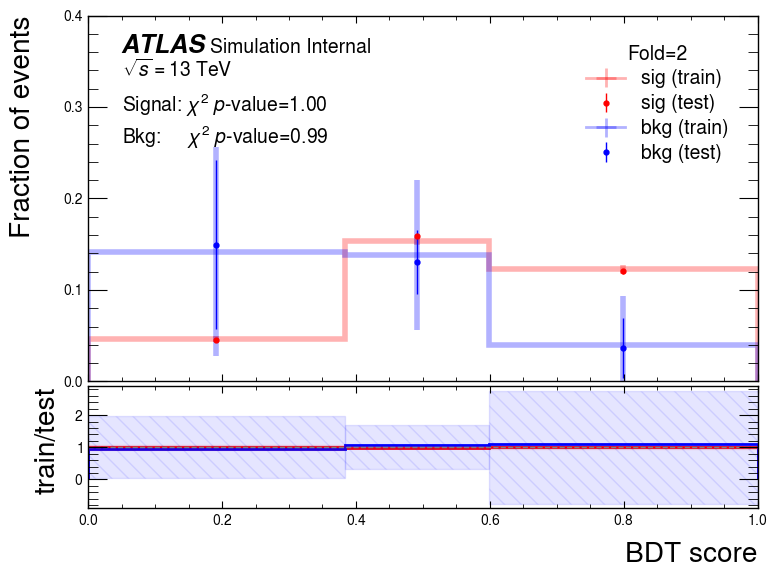

In [52]:
## !!!! KS test with fitted bins used in Analysis

# Working code - Per fold. Change no. of folds
# Unweighted  - with corrected Sumw2()
# Normalized with auc
folds = 4
fold = 2
fig, axes = plt.subplots(nrows=2,ncols=1,gridspec_kw={'height_ratios': [3, 1]}, sharex=True)
custom_bins = [0, 0.383, 0.598, 1]


# Example dummy data and plots:
results_sig_fold_test = results_sig[df_sig_85['eventNumber']%folds == fold]
results_bkg_fold_test = results_bkg[df_bkg_85['eventNumber']%folds == fold]
weights_sig_fold_test = df_sig_85['weight'][df_sig_85['eventNumber']%folds == fold]
weights_bkg_fold_test = df_bkg_85['weight'][df_bkg_85['eventNumber']%folds == fold]
y = np.concatenate([np.ones_like(results_sig_fold_test), np.zeros_like(results_bkg_fold_test)])
scores = np.concatenate([results_sig_fold_test, results_bkg_fold_test])
weights = np.concatenate([weights_sig_fold_test,weights_bkg_fold_test])

results_sig_fold_train = results_sig[df_sig_85['eventNumber']%folds != fold]
results_bkg_fold_train = results_bkg[df_bkg_85['eventNumber']%folds != fold]
weights_sig_fold_train = df_sig_85['weight'][df_sig_85['eventNumber']%folds != fold]
weights_bkg_fold_train = df_bkg_85['weight'][df_bkg_85['eventNumber']%folds != fold]
y = np.concatenate([np.ones_like(results_sig_fold_train), np.zeros_like(results_bkg_fold_train)])
scores = np.concatenate([results_sig_fold_train, results_bkg_fold_train])
weights = np.concatenate([weights_sig_fold_train,weights_bkg_fold_train])

"""
bc, bb = np.histogram(data1, weights=weights1, range=(-3,3), bins=10)
sumW2, bb = np.histogram(data1, weights=weights1**2, range=(-3,3), bins=10)
mplhep.histplot(bc,bb,yerr=np.sqrt(sumW2),density=True,label='10000 events, weight=0.1', histtype='errorbar')
"""
#bc_sig_train, bb = np.histogram(results_sig_fold_train, weights=weights_sig_fold_train, bins=np.linspace(0,1,11), density=True)


bc_sig_train, bb = np.histogram(results_sig_fold_train, weights=weights_sig_fold_train, range=(0,1), bins=custom_bins, density=True)
total_sig_train = len(results_sig_fold_train) #np.sum(bc_sig_train)
sumW2, bb = np.histogram(results_sig_fold_train, weights=weights_sig_fold_train**2, range=(0,1), bins=custom_bins)
mplhep.histplot(bc_sig_train,bb,yerr=np.sqrt(sumW2), density=True, label='sig (train)', histtype='step', ax=axes[0], color='red', alpha=0.3, linewidth=4)
bc_sig_train_e = np.sqrt(sumW2)

bc_sig_test, bb = np.histogram(results_sig_fold_test,  weights=weights_sig_fold_test, range=(0,1), bins=custom_bins, density=True)
total_sig_test = len(results_sig_fold_test) #np.sum(bc_sig_test)
sumW2, bb = np.histogram(results_sig_fold_test, weights=weights_sig_fold_test**2, range=(0,1), bins=custom_bins)
mplhep.histplot(bc_sig_test,bb,yerr=np.sqrt(sumW2),density=True, label='sig (test)', histtype='errorbar', ax=axes[0], color='red', markersize=7)
bc_sig_test_e = np.sqrt(sumW2)

bc_bkg_train, bb = np.histogram(results_bkg_fold_train, weights=weights_bkg_fold_train, range=(0,1), bins=custom_bins, density=True)
total_bkg_train = len(results_bkg_fold_train) #np.sum(bc_sig_train)
sumW2, bb = np.histogram(results_bkg_fold_train, weights=weights_bkg_fold_train**2, range=(0,1), bins=custom_bins)
mplhep.histplot(bc_bkg_train,bb,yerr=np.sqrt(sumW2), density=True, label='bkg (train)', histtype='step', ax=axes[0], color='blue', alpha=0.3, linewidth=4)
bc_bkg_train_e = np.sqrt(sumW2)


bc_bkg_test, bb = np.histogram(results_bkg_fold_test,  weights=weights_bkg_fold_test, range=(0,1), bins=custom_bins, density=True)
total_bkg_test = len(results_bkg_fold_test) #np.sum(bc_sig_test)
sumW2, bb = np.histogram(results_bkg_fold_test, weights=weights_bkg_fold_test**2, range=(0,1), bins=custom_bins)
mplhep.histplot(bc_bkg_test,bb,yerr=np.sqrt(sumW2), density=True, label='bkg (test)', histtype='errorbar', ax=axes[0], color='blue', markersize=7)
bc_bkg_test_e = np.sqrt(sumW2)

print(bb)


print("-----------------------------------------------")
# Example check if data is within expected range
print(bc_sig_train.min(), bc_sig_train.max())
print(bc_sig_test.min(), bc_sig_test.max())

print(len(bb), len(bc_sig_train), len(bc_bkg_train))
bc_bkg_test = np.where(bc_bkg_test == 0, 1e-1, bc_bkg_test)


corr_factor_sig = np.sum(bc_sig_train)/np.sum(bc_sig_test)
chi2_sig, p_sig = chisquare(bc_sig_train, bc_sig_test*corr_factor_sig)
corr_factor_bkg = np.sum(bc_bkg_train)/np.sum(bc_bkg_test)
chi2_bkg, p_bkg = chisquare(bc_bkg_train, bc_bkg_test*corr_factor_bkg)


axes[0].set_xlim(0,1)
axes[0].set_ylim(0,4)

#scale_and_format_y_axis(axes[0], scale_factor=0.1)  # Adjust scale_factor as needed

# Create the FuncFormatter object
formatter = mtick.FuncFormatter(custom_formatter)

# Apply the custom formatter to the y-axis
axes[0].yaxis.set_major_formatter(formatter)
axes[0].yaxis.set_major_locator(mtick.MultipleLocator(1))   # removing this will lead to duplicate labels


axes[0].legend(title=F'Fold={fold}', loc='upper right')

#ax.set_xlabel('BDT score')
axes[0].set_ylabel('Fraction of events', labelpad=20)
mplhep.atlas.label('Internal', data=False, ax=axes[0])
axes[0].text(x=0.05, y=2.6,s=F'Signal: $\chi^2$ $p$-value={p_sig:.2f}\nBkg:     $\chi^2$ $p$-value={p_bkg:.2f}')
axes[0].tick_params(axis='both', labelsize=10)

print("Signal train histogram:", bc_sig_train)
print("Signal test histogram:", bc_sig_test)
print("Background train histogram:", bc_bkg_train)
print("Background test histogram:", bc_bkg_test)

print("-----------------------------------------------")




print("\nSignal train errors:", bc_sig_train_e)
print("Signal test errors:", bc_sig_test_e)
print("Background train errors:", bc_bkg_train_e)
print("Background test errors:", bc_bkg_test_e)

print("-----------------------------------------------")

ratio_sig = np.where(bc_sig_test == 0, 1, bc_sig_train / bc_sig_test)
ratio_bkg = np.where(bc_bkg_test == 0, 1, bc_bkg_train / bc_bkg_test)


print("\nSig ratio: ", ratio_sig)
print("Bkg ratio: ", ratio_bkg)


ratio_sig_e = np.sqrt((bc_sig_train/(1.0*bc_sig_test*bc_sig_test))*(bc_sig_train/(1.0*bc_sig_test*bc_sig_test))*bc_sig_test_e*bc_sig_test_e+(1/(1.0*bc_sig_test))*(1/(1.0*bc_sig_test))*bc_sig_train_e*bc_sig_train_e)
ratio_bkg_e = np.sqrt((bc_bkg_train/(1.0*bc_bkg_test*bc_bkg_test))*(bc_bkg_train/(1.0*bc_bkg_test*bc_bkg_test))*bc_bkg_test_e*bc_bkg_test_e+(1/(1.0*bc_bkg_test))*(1/(1.0*bc_bkg_test))*bc_bkg_train_e*bc_bkg_train_e)

print("\nSig Ratio uncertainties per bin: ", ratio_sig_e)



# Clip errors and add padding
max_error = 100  # Example maximum error threshold
clipped_errors_sig = np.clip(ratio_sig_e, 0, max_error)
clipped_errors_bkg = np.clip(ratio_bkg_e, 0, max_error)

print("Clipped errors:", clipped_errors_sig)
print("Clipped errors:", clipped_errors_bkg)

#custom_bins = np.array([0, 0.420, 0.623, 1])
custom_bins = np.array([0, 0.383, 0.598, 1])


#bb_centers = (bb[:-1] + bb[1:]) / 2
bb_centers = (custom_bins[:-1] + custom_bins[1:]) / 2

mplhep.histplot(ratio_sig, custom_bins, histtype='step', ax=axes[1], color='red', linewidth=2)
mplhep.histplot(ratio_bkg, custom_bins, histtype='step', ax=axes[1], color='blue', linewidth=2)

#bin_width = bb[1] - bb[0] 
#bin_width = custom_bins[1] - custom_bins[0]  # Update bin width based on custom bins
bin_widths = np.diff(custom_bins)  # Using np.diff to calculate the distance between bin edges
print(bin_widths)

    
# Plot the uncertainty band using custom bin centers and the clipped errors
for center, err, width in zip(bb_centers, clipped_errors_sig, bin_widths):
    axes[1].bar(center, 2 * err, width=width, bottom=1 - err, color='red', alpha=0.1, edgecolor='red', hatch='\\\\', align='center')

for center, err, width in zip(bb_centers, clipped_errors_bkg, bin_widths):
    axes[1].bar(center, 2 * err, width=width, bottom=1 - err, color='blue', alpha=0.1, edgecolor='blue', hatch='\\\\', align='center')


#axes[1].set_dashes((5,2))

axes[1].axhline(1,0,1,linestyle='--',color='grey', linewidth=1)
axes[1].set_ylabel('train/test')
axes[1].set_xlabel('BDT score')
axes[1].tick_params(axis='both', labelsize=10)

axes[1].set_ylim(-0.9,2.9)  # Adjust based on your ratio values
fig.tight_layout()
fig.subplots_adjust(hspace=0.02)
fig.savefig(f'Test_Train_Chi_Squared_Unweighted_{fold}_Model8_3Class_fittedOlderBins.png')

-----------------------------------------------
0.004494540590413282 2.0298820594103804
0.008375600099206536 1.9906003753772166
11 10 10
Signal train histogram: [0.00449454 0.23512346 0.68013335 1.04167071 1.41071201 1.75873372
 2.02988206 1.95270543 0.8751425  0.01140199]
Signal test histogram: [0.0083756  0.25767891 0.67339207 1.06277666 1.41118787 1.7476213
 1.99060038 1.95155677 0.88772804 0.00908256]
Background train histogram: [0.04385175 1.55967445 2.29729445 1.81441122 1.49599627 1.21232506
 0.8683899  0.58267771 0.12537971 0.        ]
Background test histogram: [0.09495882 1.56149802 2.40614851 2.20908271 1.32376083 0.89373419
 0.88154863 0.56013988 0.06912847 0.1       ]
-----------------------------------------------

Signal train errors: [0.00148164 0.01061526 0.01803128 0.02224001 0.02584375 0.02878713
 0.03085857 0.03027071 0.02023048 0.00230196]
Signal test errors: [0.00115606 0.00642162 0.01031979 0.01297146 0.01490141 0.01661222
 0.01769125 0.01749046 0.01174996 0.0011

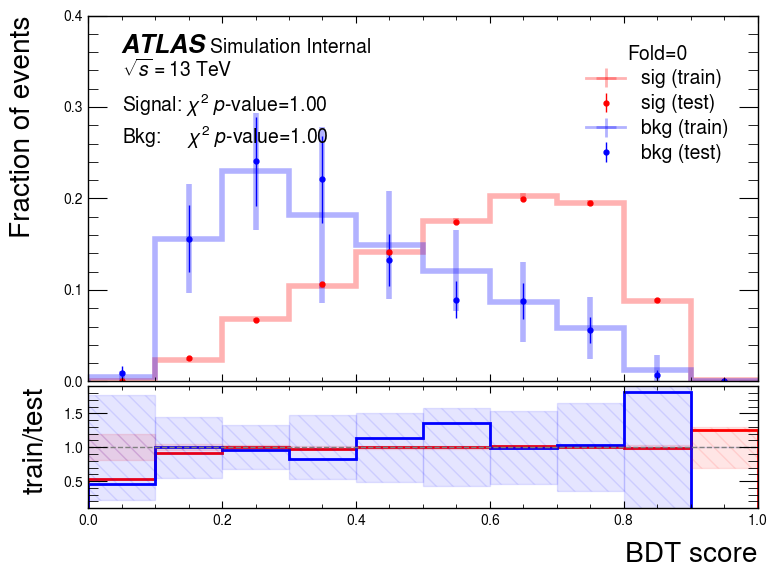

In [41]:
# Working code - Per fold. Change no. of folds
# Unweighted  - with corrected Sumw2()
# Normalized with auc
folds = 4
fold = 0
fig, axes = plt.subplots(nrows=2,ncols=1,gridspec_kw={'height_ratios': [3, 1]}, sharex=True)

results_sig_fold_test = results_sig[df_sig_85['eventNumber']%folds == fold]
results_bkg_fold_test = results_bkg[df_bkg_85['eventNumber']%folds == fold]
weights_sig_fold_test = df_sig_85['weight'][df_sig_85['eventNumber']%folds == fold]
weights_bkg_fold_test = df_bkg_85['weight'][df_bkg_85['eventNumber']%folds == fold]
y = np.concatenate([np.ones_like(results_sig_fold_test), np.zeros_like(results_bkg_fold_test)])
scores = np.concatenate([results_sig_fold_test, results_bkg_fold_test])
weights = np.concatenate([weights_sig_fold_test,weights_bkg_fold_test])

results_sig_fold_train = results_sig[df_sig_85['eventNumber']%folds != fold]
results_bkg_fold_train = results_bkg[df_bkg_85['eventNumber']%folds != fold]
weights_sig_fold_train = df_sig_85['weight'][df_sig_85['eventNumber']%folds != fold]
weights_bkg_fold_train = df_bkg_85['weight'][df_bkg_85['eventNumber']%folds != fold]
y = np.concatenate([np.ones_like(results_sig_fold_train), np.zeros_like(results_bkg_fold_train)])
scores = np.concatenate([results_sig_fold_train, results_bkg_fold_train])
weights = np.concatenate([weights_sig_fold_train,weights_bkg_fold_train])

"""
bc, bb = np.histogram(data1, weights=weights1, range=(-3,3), bins=10)
sumW2, bb = np.histogram(data1, weights=weights1**2, range=(-3,3), bins=10)
mplhep.histplot(bc,bb,yerr=np.sqrt(sumW2),density=True,label='10000 events, weight=0.1', histtype='errorbar')
"""
#bc_sig_train, bb = np.histogram(results_sig_fold_train, weights=weights_sig_fold_train, bins=np.linspace(0,1,11), density=True)


bc_sig_train, bb = np.histogram(results_sig_fold_train, weights=weights_sig_fold_train, range=(0,1), bins=10, density=True)
total_sig_train = len(results_sig_fold_train) #np.sum(bc_sig_train)
sumW2, bb = np.histogram(results_sig_fold_train, weights=weights_sig_fold_train**2, range=(0,1), bins=10)
mplhep.histplot(bc_sig_train,bb,yerr=np.sqrt(sumW2), density=True, label='sig (train)', histtype='step', ax=axes[0], color='red', alpha=0.3, linewidth=4)
bc_sig_train_e = np.sqrt(sumW2)

bc_sig_test, bb = np.histogram(results_sig_fold_test,  weights=weights_sig_fold_test, range=(0,1), bins=10, density=True)
total_sig_test = len(results_sig_fold_test) #np.sum(bc_sig_test)
sumW2, bb = np.histogram(results_sig_fold_test, weights=weights_sig_fold_test**2, range=(0,1), bins=10)
mplhep.histplot(bc_sig_test,bb,yerr=np.sqrt(sumW2),density=True, label='sig (test)', histtype='errorbar', ax=axes[0], color='red', markersize=7)
bc_sig_test_e = np.sqrt(sumW2)

bc_bkg_train, bb = np.histogram(results_bkg_fold_train, weights=weights_bkg_fold_train, range=(0,1), bins=10, density=True)
total_bkg_train = len(results_bkg_fold_train) #np.sum(bc_sig_train)
sumW2, bb = np.histogram(results_bkg_fold_train, weights=weights_bkg_fold_train**2, range=(0,1), bins=10)
mplhep.histplot(bc_bkg_train,bb,yerr=np.sqrt(sumW2), density=True, label='bkg (train)', histtype='step', ax=axes[0], color='blue', alpha=0.3, linewidth=4)
bc_bkg_train_e = np.sqrt(sumW2)


bc_bkg_test, bb = np.histogram(results_bkg_fold_test,  weights=weights_bkg_fold_test, range=(0,1), bins=10, density=True)
total_bkg_test = len(results_bkg_fold_test) #np.sum(bc_sig_test)
sumW2, bb = np.histogram(results_bkg_fold_test, weights=weights_bkg_fold_test**2, range=(0,1), bins=10)
mplhep.histplot(bc_bkg_test,bb,yerr=np.sqrt(sumW2), density=True, label='bkg (test)', histtype='errorbar', ax=axes[0], color='blue', markersize=7)
bc_bkg_test_e = np.sqrt(sumW2)




print("-----------------------------------------------")
# Example check if data is within expected range
print(bc_sig_train.min(), bc_sig_train.max())
print(bc_sig_test.min(), bc_sig_test.max())

print(len(bb), len(bc_sig_train), len(bc_bkg_train))
bc_bkg_test = np.where(bc_bkg_test == 0, 1e-1, bc_bkg_test)


corr_factor_sig = np.sum(bc_sig_train)/np.sum(bc_sig_test)
chi2_sig, p_sig = chisquare(bc_sig_train, bc_sig_test*corr_factor_sig)
corr_factor_bkg = np.sum(bc_bkg_train)/np.sum(bc_bkg_test)
chi2_bkg, p_bkg = chisquare(bc_bkg_train, bc_bkg_test*corr_factor_bkg)


axes[0].set_xlim(0,1)
axes[0].set_ylim(0,4)

#scale_and_format_y_axis(axes[0], scale_factor=0.1)  # Adjust scale_factor as needed

# Create the FuncFormatter object
formatter = mtick.FuncFormatter(custom_formatter)

# Apply the custom formatter to the y-axis
axes[0].yaxis.set_major_formatter(formatter)
axes[0].yaxis.set_major_locator(mtick.MultipleLocator(1))   # removing this will lead to duplicate labels


axes[0].legend(title=F'Fold={fold}', loc='upper right')

#ax.set_xlabel('BDT score')
axes[0].set_ylabel('Fraction of events', labelpad=20)
mplhep.atlas.label('Internal', data=False, ax=axes[0])
axes[0].text(x=0.05, y=2.6,s=F'Signal: $\chi^2$ $p$-value={p_sig:.2f}\nBkg:     $\chi^2$ $p$-value={p_bkg:.2f}')
axes[0].tick_params(axis='both', labelsize=10)

print("Signal train histogram:", bc_sig_train)
print("Signal test histogram:", bc_sig_test)
print("Background train histogram:", bc_bkg_train)
print("Background test histogram:", bc_bkg_test)

print("-----------------------------------------------")




#y1 = bc_sig_train
#y1err = np.sqrt(sumW2) # calculated from sig train
#y2 = bc_sig_test
#y2err = np.sqrt(sumW2) # calculated from sig test






# Errors on histograms:
#bc_sig_train_e = np.sqrt(bc_sig_train/total_sig_train)*10  #np.sqrt(bc_sig_train)
#bc_sig_test_e = np.sqrt(bc_sig_test/total_sig_test)*10  #np.sqrt(bc_sig_test)
#bc_bkg_train_e = np.sqrt(bc_bkg_train/total_bkg_train)*10  #np.sqrt(bc_bkg_train)
#bc_bkg_test_e = np.sqrt(bc_bkg_test/total_bkg_test)*10  #np.sqrt(bc_bkg_test)





print("\nSignal train errors:", bc_sig_train_e)
print("Signal test errors:", bc_sig_test_e)
print("Background train errors:", bc_bkg_train_e)
print("Background test errors:", bc_bkg_test_e)

print("-----------------------------------------------")

ratio_sig = np.where(bc_sig_test == 0, 1, bc_sig_train / bc_sig_test)
ratio_bkg = np.where(bc_bkg_test == 0, 1, bc_bkg_train / bc_bkg_test)


print("\nSig ratio: ", ratio_sig)
print("Bkg ratio: ", ratio_bkg)


ratio_sig_e = np.sqrt((bc_sig_train/(1.0*bc_sig_test*bc_sig_test))*(bc_sig_train/(1.0*bc_sig_test*bc_sig_test))*bc_sig_test_e*bc_sig_test_e+(1/(1.0*bc_sig_test))*(1/(1.0*bc_sig_test))*bc_sig_train_e*bc_sig_train_e)
ratio_bkg_e = np.sqrt((bc_bkg_train/(1.0*bc_bkg_test*bc_bkg_test))*(bc_bkg_train/(1.0*bc_bkg_test*bc_bkg_test))*bc_bkg_test_e*bc_bkg_test_e+(1/(1.0*bc_bkg_test))*(1/(1.0*bc_bkg_test))*bc_bkg_train_e*bc_bkg_train_e)

print("\nSig Ratio uncertainties per bin: ", ratio_sig_e)



# Ratio plot
#ratio_sig = bc_sig_train/bc_sig_test # np.divide(bc_sig_train, bc_sig_test, out=np.zeros_like(bc_sig_train), where=bc_sig_test != 0)
#ratio_bkg = bc_bkg_train/bc_bkg_test #  np.divide(bc_bkg_train, bc_bkg_test, out=np.zeros_like(bc_bkg_train), where=bc_bkg_test != 0)
#print(bb)
#print(ratio_sig)
#print(ratio_bkg)
#print(len(bb), len(ratio_sig), len(ratio_bkg))

# Clip errors and add padding
max_error = 100  # Example maximum error threshold
clipped_errors_sig = np.clip(ratio_sig_e, 0, max_error)
clipped_errors_bkg = np.clip(ratio_bkg_e, 0, max_error)

print("Clipped errors:", clipped_errors_sig)
print("Clipped errors:", clipped_errors_bkg)




bb_centers = (bb[:-1] + bb[1:]) / 2
#axes[1].plot(bb_centers, ratio_sig, 'o', label='Sig', color='red', linestyle='None', markersize=5)
#axes[1].plot(bb_centers, ratio_bkg, 'o', label='Bkg', color='blue', linestyle='None', markersize=5)
#axes[1].axhline(1,0,1,linestyle='--',color='grey')

mplhep.histplot(ratio_sig, bb, histtype='step', ax=axes[1], color='red', linewidth=2)
mplhep.histplot(ratio_bkg, bb, histtype='step', ax=axes[1], color='blue', linewidth=2)


# Plot with clipped errors
#axes[1].fill_between(bb_centers, y1=(ratio_sig + clipped_errors_sig), y2=(ratio_sig - clipped_errors_sig), alpha=0.2, color='red')
#axes[1].fill_between(bb_centers, y1=(ratio_bkg + clipped_errors_bkg), y2=(ratio_bkg - clipped_errors_bkg), alpha=0.2, color='blue')

#axes[1].fill_between(bb_centers, y1=(1 + clipped_errors_sig), y2=(1 - clipped_errors_sig), alpha=0.2, color='red', hatch='\\\\', zorder=1) 
#axes[1].fill_between(bb_centers, y1=(1 + clipped_errors_bkg), y2=(1 - clipped_errors_bkg), alpha=0.2, color='blue', hatch='/', zorder=1) 


# Plot the ratio uncertainty bands with hatch styles
#axes[1].fill_between(
#    bb_centers, y1=(1 + clipped_errors_sig), y2=(1 - clipped_errors_sig), facecolor='none', edgecolor='red', hatch='\\\\', zorder=1, linewidth=0.0)
#axes[1].fill_between(
#    bb_centers, y1=(1 + clipped_errors_bkg), y2=(1 - clipped_errors_bkg), facecolor='none', edgecolor='#CCCCFF', hatch='///', zorder=1, linewidth=0.0)


#axes[1].fill_between(
#    bb_centers, y1=(1 + clipped_errors_sig), y2=(1 - clipped_errors_sig), facecolor='red', alpha=0.2, edgecolor='red', hatch='\\\\', zorder=1)

bin_width = bb[1] - bb[0] 
# Plot the uncertainty band in histogram style using bar
for center, err in zip(bb_centers, clipped_errors_sig):
    axes[1].bar(center, 2 * err, width=bin_width, bottom=1 - err, color='red', alpha=0.1, edgecolor='red', hatch='\\\\', align='center')
for center, err in zip(bb_centers, clipped_errors_bkg):
    axes[1].bar(center, 2 * err, width=bin_width, bottom=1 - err, color='blue', alpha=0.1, edgecolor='blue', hatch='\\\\', align='center')


#axes[1].set_dashes((5,2))

axes[1].axhline(1,0,1,linestyle='--',color='grey', linewidth=1)
axes[1].set_ylabel('train/test')
axes[1].set_xlabel('BDT score')
axes[1].tick_params(axis='both', labelsize=10)

axes[1].set_ylim(0.1,1.9)  # Adjust based on your ratio values
fig.tight_layout()
fig.subplots_adjust(hspace=0.02)
fig.savefig(f'Test_Train_Chi_Squared_10bins_{fold}_Model8_3ClassPerProcess.png')

# Using scale_pos_weight for Reweighting

In [45]:
n_estimators = 33

In [52]:
len(df_sig_85), len(df_bkg_prompt_85_reweighted), len(df_bkg_fakes_85_reweighted), 

(358887, 2804, 3051)

In [59]:

nfolds = 4

# SINGLE MODEL  : Using XGB Classifier
models = []
scores_train, scores_test = [], []
testloss = {fold: [] for fold in range(nfolds)}
trainloss = {fold: [] for fold in range(nfolds)}

for fold in range(nfolds):
    # Signal: Train/Test split
    X_sig_train = df_sig_85[feature_cols][df_sig_85['eventNumber'] % nfolds != fold]
    w_sig_train = df_sig_85['weight'][df_sig_85['eventNumber'] % nfolds != fold]

    X_sig_test = df_sig_85[feature_cols][df_sig_85['eventNumber'] % nfolds == fold]
    w_sig_test = df_sig_85['weight'][df_sig_85['eventNumber'] % nfolds == fold]

    # Prompt Background: Train/Test split
    X_bkg_train_prompts = df_bkg_prompt_85_reweighted[feature_cols][df_bkg_prompt_85_reweighted['eventNumber'] % nfolds != fold]
    w_bkg_train_prompts = df_bkg_prompt_85_reweighted['weight'][df_bkg_prompt_85_reweighted['eventNumber'] % nfolds != fold]

    X_bkg_test_prompts = df_bkg_prompt_85_reweighted[feature_cols][df_bkg_prompt_85_reweighted['eventNumber'] % nfolds == fold]
    w_bkg_test_prompts = df_bkg_prompt_85_reweighted['weight'][df_bkg_prompt_85_reweighted['eventNumber'] % nfolds == fold]

    # Fake Background: Train/Test split
    X_bkg_train_fakes = df_bkg_fakes_85_reweighted[feature_cols][df_bkg_fakes_85_reweighted['eventNumber'] % nfolds != fold]
    w_bkg_train_fakes = df_bkg_fakes_85_reweighted['weight'][df_bkg_fakes_85_reweighted['eventNumber'] % nfolds != fold]

    X_bkg_test_fakes = df_bkg_fakes_85_reweighted[feature_cols][df_bkg_fakes_85_reweighted['eventNumber'] % nfolds == fold]
    w_bkg_test_fakes = df_bkg_fakes_85_reweighted['weight'][df_bkg_fakes_85_reweighted['eventNumber'] % nfolds == fold]

    # Reweight Backgrounds: Train
    total_w_bkg_train_prompts = np.sum(np.abs(w_bkg_train_prompts))
    total_w_bkg_train_fakes = np.sum(np.abs(w_bkg_train_fakes))

    scale_train_prompt = 1.0 / total_w_bkg_train_prompts
    scale_train_fake = 1.0 / total_w_bkg_train_fakes

    w_bkg_train_prompts_reweighted = w_bkg_train_prompts * scale_train_prompt
    w_bkg_train_fakes_reweighted = w_bkg_train_fakes * scale_train_fake

    # Reweight Backgrounds: Test
    total_w_bkg_test_prompts = np.sum(np.abs(w_bkg_test_prompts))
    total_w_bkg_test_fakes = np.sum(np.abs(w_bkg_test_fakes))

    scale_test_prompt = 1.0 / total_w_bkg_test_prompts
    scale_test_fake = 1.0 / total_w_bkg_test_fakes

    w_bkg_test_prompts_reweighted = w_bkg_test_prompts * scale_test_prompt
    w_bkg_test_fakes_reweighted = w_bkg_test_fakes * scale_test_fake

    # Class Ratios for `scale_pos_weight` -----------> might NOT BE NEEDED
    #num_prompt_train = len(w_bkg_train_prompts)
    #num_fake_train = len(w_bkg_train_fakes)

    #scale_pos_weight_prompt_fake = num_fake_train / num_prompt_train

    # Combine data for training
    y_train = np.concatenate([
        np.zeros_like(w_sig_train),
        np.ones_like(w_bkg_train_prompts),
        2 * np.ones_like(w_bkg_train_fakes)
    ])
    X_train = np.concatenate([X_sig_train, X_bkg_train_prompts, X_bkg_train_fakes])
    w_train = np.concatenate([w_sig_train, w_bkg_train_prompts, w_bkg_train_fakes])

    y_test = np.concatenate([
        np.zeros_like(w_sig_test),
        np.ones_like(w_bkg_test_prompts),
        2 * np.ones_like(w_bkg_test_fakes)
    ])
    X_test = np.concatenate([X_sig_test, X_bkg_test_prompts, X_bkg_test_fakes])
    w_test = np.concatenate([w_sig_test, w_bkg_test_prompts, w_bkg_test_fakes])

    # Print Data Summary
    print("\n\nFold", fold)
    print("Signal train/test: ", len(X_sig_train), len(X_sig_test))
    print("Prompt train/test: ", len(X_bkg_train_prompts), len(X_bkg_test_prompts))
    print("Fake train/test: ", len(X_bkg_train_fakes), len(X_bkg_test_fakes))
    print(f"Class Ratios (Train): Prompt : Fake = {num_prompt_train} : {num_fake_train}")
    print(f"scale_pos_weight = {scale_pos_weight_prompt_fake:.3f}")    
    
    
    model = XGBClassifier(
        tree_method="hist",     # Tree method to use (e.g., "hist" for faster training)
        verbosity=3,            # Set verbosity level for debugging
        n_estimators=n_estimators,  # Number of trees in the model
        objective="multi:softmax",  # Objective for multi-class classification
        num_class=3,             # Specify the number of classes (3 in this case)
        #scale_pos_weight=scale_pos_weight_prompt_fake
    )

    # Fit model
    model.fit(X_train, y_train, sample_weight=np.abs(w_train))
    models.append(model)


    # Evaluate Model
    scores_train.append(model.score(X_train, y_train, sample_weight=np.abs(w_train)))
    scores_test.append(model.score(X_test, y_test, sample_weight=np.abs(w_test)))

    print(f"Train Score (Fold {fold}): {scores_train[-1]:.4f}")
    print(f"Test Score (Fold {fold}): {scores_test[-1]:.4f}")




Fold 0
Signal train/test:  269250 89637
Prompt train/test:  2100 704
Fake train/test:  2303 748
Class Ratios (Train): Prompt : Fake = 2079 : 2261
scale_pos_weight = 1.088
[17:33:39] ======== Monitor (0): HostSketchContainer ========
[17:33:39] AllReduce: 0.00684s, 1 calls @ 6840us

[17:33:39] MakeCuts: 0.006925s, 1 calls @ 6925us

[17:33:39] DEBUG: /build/jenkins/workspace/lcg_release_pipeline/build/pyexternals/xgboost-2.0.2/src/xgboost/2.0.2/src/gbm/gbtree.cc:130: Using tree method: 3
[17:33:40] ======== Monitor (0): Learner ========
[17:33:40] Configure: 0.000387s, 1 calls @ 387us

[17:33:40] EvalOneIter: 0.000338s, 33 calls @ 338us

[17:33:40] GetGradient: 0.163826s, 33 calls @ 163826us

[17:33:40] PredictRaw: 0.000723s, 33 calls @ 723us

[17:33:40] UpdateOneIter: 1.00902s, 33 calls @ 1009024us

[17:33:40] ======== Monitor (0): GBTree ========
[17:33:40] BoostNewTrees: 0.843034s, 33 calls @ 843034us

[17:33:40] CommitModel: 0.000189s, 33 calls @ 189us

[17:33:40] ======== Monitor 

In [61]:
# Works

nfolds = 4
testloss = {fold:[] for fold in range(nfolds)}
trainloss = {fold:[] for fold in range(nfolds)}

print(n_boosters)

n_estimators = 33

for fold in range(nfolds):
    #n_boosters = len(models[fold].get_booster().get_dump()) # This ensures we are within the actual range
    for i in range(n_estimators):   # change these numbers accordingly
        # print("Value of tree:",i)
        # Predict probabilities for a subset of trees from 1 to i+1
        ypred_train = models[fold].predict_proba(X_train, iteration_range=(0, i+1))
        ypred_test = models[fold].predict_proba(X_test, iteration_range=(0, i+1))
        
        # Compute the log loss with the true labels and predicted probabilities
        loss_train = metrics.log_loss(y_train, ypred_train, sample_weight=(w_train))
        loss_test = metrics.log_loss(y_test, ypred_test, sample_weight=(w_test))
        
        # Append the loss values to respective lists
        trainloss[fold].append(loss_train)
        testloss[fold].append(loss_test)

99


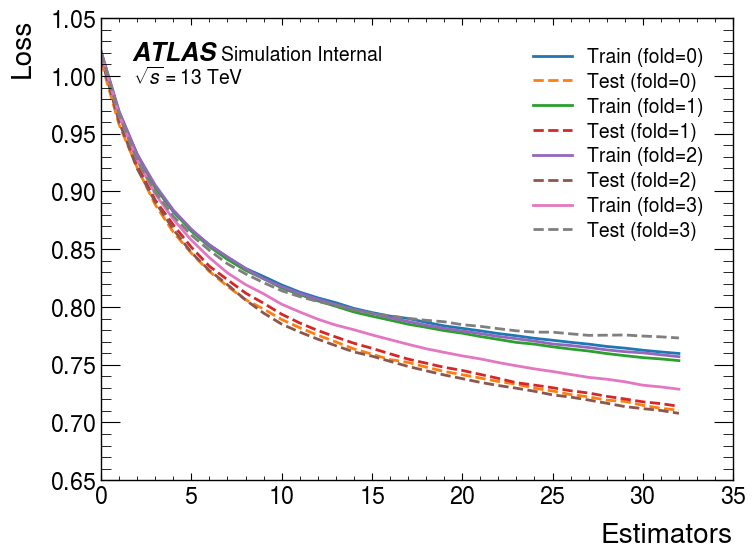

In [62]:
mplhep.style.use('ATLAS')

nfolds = 4
n_estimators = 33
# Plotting the results
fig, ax = plt.subplots()
for fold in range(nfolds):
    estimators = range(0, n_estimators)
    ax.plot(estimators, trainloss[fold], label=f'Train ({fold=})')
    ax.plot(estimators, testloss[fold], label=f'Test ({fold=})', linestyle='--')

ax.legend()
ax.set_title('')
mplhep.atlas.label('Internal', data=False, ax=ax)   # true to remove Simulation
ax.set_xlabel('Estimators')
ax.set_ylabel('Loss')
plt.show()

In [64]:
X_sig = df_sig_85[feature_cols].to_numpy().astype(np.float32) 
X_bkg_prompts = df_bkg_prompt_85_reweighted[feature_cols].to_numpy().astype(np.float32) 
X_bkg_fakes = df_bkg_fakes_85_reweighted[feature_cols].to_numpy().astype(np.float32) 


results_sig_list = [model.predict_proba(X_sig)[:,0] for model in models]   #array of bdt scores
results_bkg_prompts_list = [model.predict_proba(X_bkg_prompts)[:,0] for model in models]   #array of bdt scores
results_bkg_fakes_list = [model.predict_proba(X_bkg_fakes)[:,0] for model in models]   #array of bdt scores

"""
print('Arrays for BDT scroes:')
print('Sig: ',results_sig_list)
print('Bkg: ',results_bkg_list)
print("Length: ", len(results_sig_list))
"""

# Separate into folds
condlist_sig = [df_sig_85['eventNumber']%nfolds == fold for fold in range(nfolds)]
results_sig = np.select(condlist_sig, results_sig_list)

condlist_bkg_prompts = [df_bkg_prompt_85_reweighted['eventNumber']%nfolds == fold for fold in range(nfolds)]
results_bkg_prompts = np.select(condlist_bkg_prompts, results_bkg_prompts_list)

condlist_bkg_fakes = [df_bkg_fakes_85_reweighted['eventNumber']%nfolds == fold for fold in range(nfolds)]
results_bkg_fakes = np.select(condlist_bkg_fakes, results_bkg_fakes_list)

print('Fold separated arrays for BDT scroes:')
print(results_bkg_prompts[1],results_bkg_fakes[1],results_sig[1])
print("Length sig: ", len(results_sig))
print("Length bkg: ", len(results_bkg_prompts))
print("Length bkg: ", len(results_bkg_fakes))

Fold separated arrays for BDT scroes:
0.34640235 0.63850445 0.68560064
Length sig:  358887
Length bkg:  2804
Length bkg:  3051


[0.383 0.215 0.402]


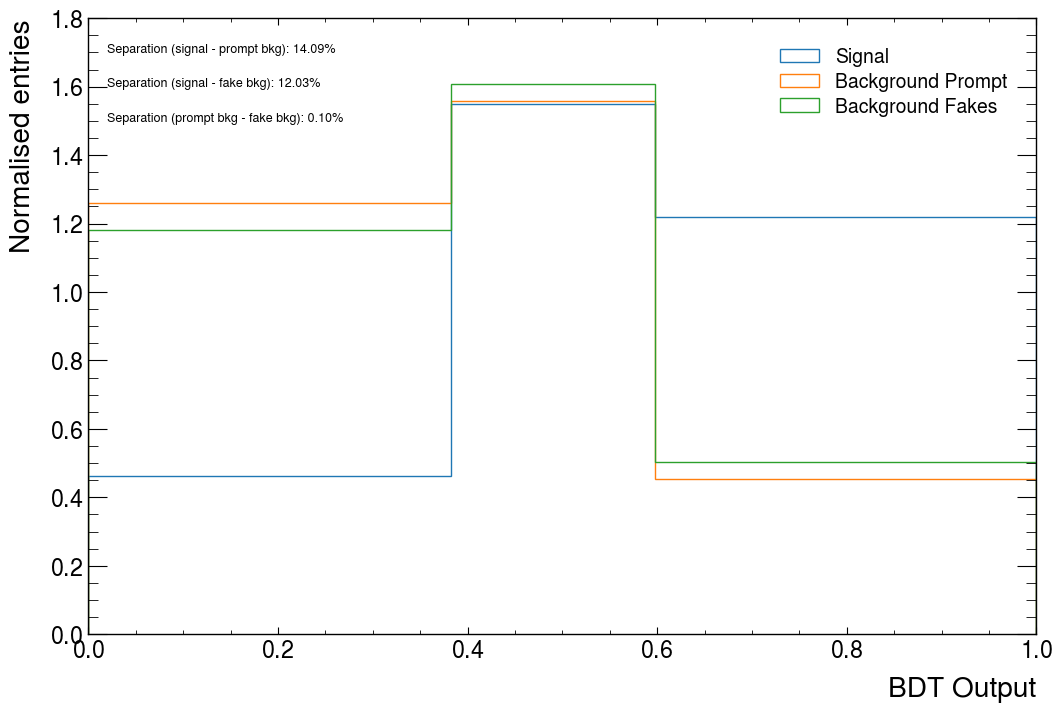

In [65]:
plt.figure(figsize=(12, 8))

# Define custom bin edges
custom_bins = [0, 0.383, 0.598, 1]

# Histogram plotting
bc_sig, bin_edges, _ = plt.hist(results_sig, weights=df_sig_85['weight'], bins=custom_bins, histtype='step', density=True, label='Signal')
bc_bkg_prompt, _, _ = plt.hist(results_bkg_prompts, weights=df_bkg_prompt_85_reweighted['weight'], bins=custom_bins, histtype='step', density=True, label='Background Prompt')
bc_bkg_fake, _, _ = plt.hist(results_bkg_fakes, weights=df_bkg_fakes_85_reweighted['weight'], bins=custom_bins, histtype='step', density=True, label='Background Fakes')


# Calculate bin widths and separation
bin_widths = np.diff(bin_edges)
print(bin_widths)
separation_sig_bkgPrompt = 0.5 * np.sum(np.nan_to_num(((bc_sig - bc_bkg_prompt) ** 2) / (bc_sig + bc_bkg_prompt)) * bin_widths)
separation_sig_bkgFake = 0.5 * np.sum(np.nan_to_num(((bc_sig - bc_bkg_fake) ** 2) / (bc_sig + bc_bkg_fake)) * bin_widths)
separation_bkgPrompt_bkgFake = 0.5 * np.sum(np.nan_to_num(((bc_bkg_prompt - bc_bkg_fake) ** 2) / (bc_bkg_prompt + bc_bkg_fake)) * bin_widths)

#separation = 0.5 * np.sum(np.nan_to_num(((bc_sig - bc_bkg) ** 2) / (bc_sig + bc_bkg)) * bin_widths)

# Plotting details
plt.legend(loc='upper right')
plt.xlabel('BDT Output')
plt.ylabel('Normalised entries')
plt.text(x=0.02, y=1.70, s=f'Separation (signal - prompt bkg): {separation_sig_bkgPrompt*100:.2f}%', fontsize = 9)
plt.text(x=0.02, y=1.60, s=f'Separation (signal - fake bkg): {separation_sig_bkgFake*100:.2f}%', fontsize = 9)
plt.text(x=0.02, y=1.50, s=f'Separation (prompt bkg - fake bkg): {separation_bkgPrompt_bkgFake*100:.2f}%', fontsize = 9)

plt.savefig(f'separation_fittedbins_3class.pdf')
plt.legend()
